# Metaheuristic Search: Simulated Annealing & Genetic Algorithms


**Who this is for:** anyone comfortable with basic Python and NumPy. No prior optimization background is assumed. We start from first principles, follow the lecture slides on Simulated Annealing and Genetic Algorithms step by step, and then go beyond them with larger experiments.

**Learning objectives.** By the end you should be able to:
1. Describe an optimization problem in terms of decision variables, objective, constraints, and search space, and explain local vs. global optima.
2. Explain every line of the **Simulated Annealing** pseudocode, implement it, and tune its temperature schedule.
3. Explain the three GA operators from the slides (**reproduction, crossover, mutation**), reproduce the slides' 8-queens example by hand' **GENETIC-ALGORITHM** pseudocode.
4. Explain what **elitism, culling, and mutation rate** do, using experiments.
5. Verify both algorithms against known optima and compare them fairly.

### Agenda

| Part | Topic | Core | Full |
|---|---|---|---|
| 1 | Foundations: optimization, local vs. global, combinatorial explosion, neighbourhoods, exploration vs. exploitation |
| 2 | Benchmarks: Rastrigin and **8-queens**; hill-climbing baseline |
| 3 | **Simulated Annealing**, following the slides (3.1–3.6), then supporting experiments |
| 4 | **Genetic Algorithm**, following the slides (4.1–4.6), then supporting experiments |
| 5 | Head-to-head at equal evaluation budget |


**Requirements:** `numpy` and `matplotlib` only.

## 📖 About this demonstration code

After **every code cell** in this notebook you will find an explanation cell marked **🔍**. Each one has three parts:

1. **Concept** — the idea behind the code, explained from first principles (with the maths where it helps).
   Most cells also include a **Diagram** that pictures the concept: flowcharts of the algorithms, worked examples of the operators, and sketches of landscapes, basins and trade-offs.
2. **Line by line** — what each line, or small group of closely related lines, does and *why*, including the Python and NumPy techniques used (vectorisation, broadcasting, closures, boolean masks, …).
3. **Reading the output** — how to interpret the printed numbers and figures from the saved run.

Some cells also carry a **note** pointing out a subtle detail (e.g. how an experiment counts its budget) worth knowing before reusing the code or quoting its numbers.

The original code and its outputs are unchanged, so *Kernel → Restart & Run All* behaves exactly as before.

In [1]:
import math
import time
import itertools
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (10, 4.5),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
})

SEED = 42  # global seed for reproducibility
print("numpy", np.__version__)

numpy 2.2.6


#### 🔍 Explanation of the cell above — setup

**Concept.** Every notebook starts by loading the libraries it needs and fixing anything that must be the same on every run. Two ideas matter here. First, *plot defaults*: instead of repeating the same size and grid settings on every figure, we set them once globally. Second, *reproducibility*: SA and GA are random algorithms, so we keep one global seed (`SEED`) that later cells pass into random number generators. Anyone who runs the notebook again then gets exactly the same numbers and figures.

**Line by line.**
- `import math` — Python's standard maths module. We use `math.exp`, `math.log` and `math.factorial` on *single numbers*; for scalars it is faster and simpler than NumPy.
- `import time` — gives `time.perf_counter()`, a high-resolution clock used to measure how long a run takes.
- `import itertools` — tools for iteration: `itertools.product` (all bit combinations), `itertools.permutations` (all tours) and `itertools.count` (an endless counter 1, 2, 3, … used by the slide SA).
- `import numpy as np` — arrays, vectorised arithmetic and random number generators. `np` is the universal abbreviation.
- `import matplotlib.pyplot as plt` — the plotting interface.
- `plt.rcParams.update({...})` — `rcParams` is Matplotlib's global settings dictionary; `update` overwrites some entries:
  - `"figure.figsize": (10, 4.5)` — default figure width × height in inches.
  - `"axes.grid": True` — draw a grid on every axis.
  - `"grid.alpha": 0.3` — make the grid lines 70% transparent so they do not dominate.
  - `"font.size": 11` — base font size for labels and titles.
- `SEED = 42` — the global seed. Any value works; what matters is that it is fixed.
- `print("numpy", np.__version__)` — records the NumPy version in the output. Results of numerical code can differ slightly between versions, so this is good practice for reproducible work.

**Reading the output.** It prints the NumPy version (2.1.3 in the saved run).

---
# Part 1 — Foundations: what are we actually doing?

### 1.1 What is optimization?
Optimization means **choosing the best option from a set of possibilities**. You do it every day:

- Picking the fastest route to college (*which roads?*)
- Packing a bag with limited space (*which items?*)
- Building a class timetable without clashes (*which slot for each class?*)
- Training a neural network (*which weight values?*)

Every optimization problem has the same ingredients:

| Term | Meaning | Example: delivery route |
|---|---|---|
| **Decision variables** $\mathbf{x}$ | What we get to choose | The order in which we visit shops |
| **Objective function** $f(\mathbf{x})$ | A single number that scores a choice | Total distance travelled (km) |
| **Constraints** | Rules a valid choice must obey | Visit each shop exactly once |
| **Search space** $\mathcal{S}$ | Every possible choice | Every possible ordering |
| **Feasible solution** | A choice that obeys all constraints | Any valid ordering |
| **Optimal solution** $\mathbf{x}^*$ | The best feasible choice | The shortest valid route |

**Minimize or maximize?** These are interchangeable, because $\max_x f(x) = -\min_x\,[-f(x)]$. In this notebook we **minimize** unless a section says otherwise.

**Black-box view.** Throughout, we assume we can only *evaluate* $f(\mathbf{x})$ for a given $\mathbf{x}$. We do not have a formula to differentiate. This is realistic: the "function" might be a simulation, a lab experiment, or a neural network's validation accuracy.

### 1.2 The smallest possible problem
Minimize $f(x) = (x-3)^2 + 1$ for $x \in [-2, 8]$.

Calculus gives the answer immediately: $f'(x) = 2(x-3) = 0 \Rightarrow x^* = 3,\ f(x^*) = 1$. But suppose we can only evaluate $f$. The most naive strategy is **brute force (grid search)**: try evenly spaced points and keep the best.

 x     f(x)
-2.0   26.00
-1.0   17.00
 0.0   10.00
 1.0    5.00
 2.0    2.00
 3.0    1.00   <-- best
 4.0    2.00
 5.0    5.00
 6.0   10.00
 7.0   17.00
 8.0   26.00


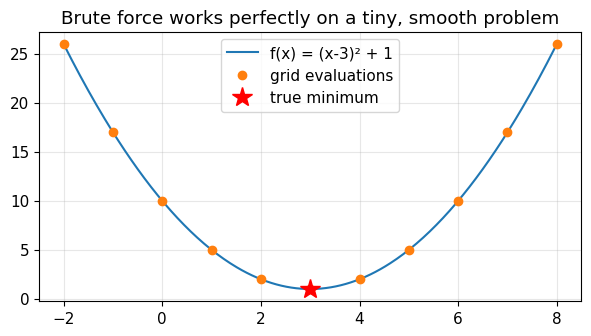

In [2]:
def f_bowl(x):
    return (x - 3) ** 2 + 1

grid = np.linspace(-2, 8, 11)          # 11 evenly spaced trial points
values = f_bowl(grid)
print(" x     f(x)")
for x, v in zip(grid, values):
    print(f"{x:4.1f}  {v:6.2f}" + ("   <-- best" if v == values.min() else ""))

xx = np.linspace(-2, 8, 300)
plt.figure(figsize=(7, 3.5))
plt.plot(xx, f_bowl(xx), label="f(x) = (x-3)² + 1")
plt.plot(grid, values, "o", label="grid evaluations")
plt.plot(3, 1, "r*", ms=15, label="true minimum")
plt.legend(); plt.title("Brute force works perfectly on a tiny, smooth problem"); plt.show()

#### 🔍 Explanation of the cell above — brute-force grid search

**Concept.** *Grid search* (brute force) is the simplest optimizer: evaluate the objective at evenly spaced points and keep the best. It needs no derivatives and no cleverness, and on a finite set it is guaranteed to find the best grid point. Its weaknesses are *resolution* and *cost*. With a grid step $h$, the true minimum can lie anywhere between two grid points, so the error in $x$ can be as large as $h/2$. Halving the error doubles the number of evaluations in 1-D, and in $d$ dimensions the number of points grows like $(1/h)^d$. Section 1.4 shows how fast that blows up.

The objective here, $f(x) = (x-3)^2 + 1$, is a single smooth bowl (a *convex* function): it has exactly one minimum, at $x^* = 3$ with $f(x^*) = 1$. On such a friendly function every method works; the interesting cases come later.

**Diagram.** Left: with a grid step $h$ the true minimum can sit between two grid points, so the best grid point can be off by up to $h/2$. Right: refining the grid multiplies the cost, and the multiplier is raised to the power of the dimension $d$.

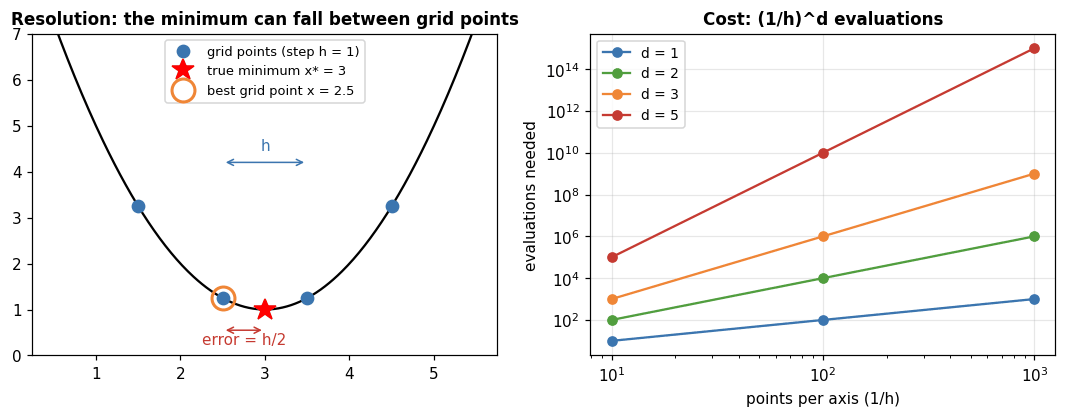

**Line by line.**
- `def f_bowl(x): return (x - 3) ** 2 + 1` — the objective. Because it uses only arithmetic, it works on a single number *or* on a whole NumPy array (element by element).
- `grid = np.linspace(-2, 8, 11)` — 11 evenly spaced points from −2 to 8 inclusive, so the spacing is $(8-(-2))/10 = 1.0$.
- `values = f_bowl(grid)` — evaluates all 11 points in one vectorised call; `values` is an array of 11 numbers.
- `print(" x     f(x)")` — table header.
- `for x, v in zip(grid, values):` — `zip` walks through the two arrays in parallel, giving one (x, f(x)) pair per step.
- `print(f"{x:4.1f}  {v:6.2f}" + ("   <-- best" if v == values.min() else ""))` — an f-string: `{x:4.1f}` prints x in a field 4 characters wide with 1 decimal; `{v:6.2f}` prints f(x) 6 wide with 2 decimals. The conditional expression appends a marker only on the row whose value equals the minimum.
- `xx = np.linspace(-2, 8, 300)` — 300 points, used only to draw a smooth curve.
- `plt.figure(figsize=(7, 3.5))` — a new, slightly smaller figure.
- `plt.plot(xx, f_bowl(xx), label=...)` — the true curve.
- `plt.plot(grid, values, "o", label=...)` — the 11 evaluations as dots (`"o"` = circle markers, no line).
- `plt.plot(3, 1, "r*", ms=15, label=...)` — the true minimum as a red star (`ms` = marker size).
- `plt.legend(); plt.title(...); plt.show()` — legend, title and display.

**Reading the output.** The table shows the values falling and then rising, with the best grid point at $x = 3.0$, $f = 1.00$. Grid search hit the exact answer only because 3 happens to be on the grid; with a grid of, say, −2, −0.9, 0.2, … it would have missed by up to half a step.

**Observation:** brute force found $x=3$ because 3 happened to be on our grid. With a grid step of 1.0, our answer can be off by up to 0.5 in general. Halving the error means doubling the number of evaluations, and that cost grows *much* faster in more dimensions, as Section 1.4 will show.

### 1.3 Local vs. global minima
Most interesting problems are not a single bowl. Consider the "wavy" function
$$
f(x) = 0.1\,x^2 + 2\sin(2x), \qquad x \in [-10, 10].
$$

- A **local minimum** is a point where every *nearby* point is worse: a valley bottom.
- The **global minimum** is the lowest point of the *entire* search space.
- The **basin of attraction** of a minimum is the set of starting points from which "always walk downhill" ends at that minimum.

7 local minima found:
  x =  -9.95   f =   8.16
  x =  -6.89   f =   2.87
  x =  -3.83   f =  -0.50
  x =  -0.77   f =  -1.94   <-- GLOBAL
  x =   2.30   f =  -1.46
  x =   5.36   f =   0.95
  x =   8.42   f =   5.28


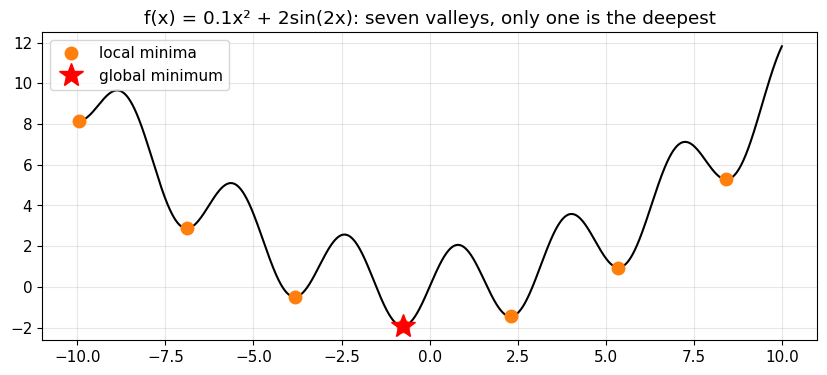

In [5]:
def f_wavy(x):
    x = np.asarray(x, dtype=float)
    return 0.1 * x**2 + 2 * np.sin(2 * x)

W_LO, W_HI = -10.0, 10.0
xx = np.linspace(W_LO, W_HI, 200_001)
yy = f_wavy(xx)

# local minima: grid points lower than both of their neighbours
is_min = (yy[1:-1] < yy[:-2]) & (yy[1:-1] < yy[2:])
loc_x, loc_f = xx[1:-1][is_min], yy[1:-1][is_min]
X_STAR, F_STAR = xx[np.argmin(yy)], yy.min()      # global minimum (our ground truth)

print(f"{len(loc_x)} local minima found:")
for x, v in zip(loc_x, loc_f):
    print(f"  x = {x:6.2f}   f = {v:6.2f}" + ("   <-- GLOBAL" if np.isclose(x, X_STAR) else ""))

plt.figure(figsize=(10, 4))
plt.plot(xx, yy, "k-", lw=1.5)
plt.plot(loc_x, loc_f, "o", color="tab:orange", ms=9, label="local minima")
plt.plot(X_STAR, F_STAR, "r*", ms=18, label="global minimum")
plt.title("f(x) = 0.1x² + 2sin(2x): seven valleys, only one is the deepest"); plt.legend(); plt.show()

#### 🔍 Explanation of the cell above — local vs. global minima

**Concept.** Real objectives usually have many valleys. Three terms describe them:
- A **local minimum** is a point lower than every point in a small region around it. Locally it looks optimal.
- The **global minimum** is the lowest point anywhere in the search space.
- The **basin of attraction** of a minimum is the set of starting points from which "always walk downhill" ends there.

$f(x) = 0.1x^2 + 2\sin(2x)$ is built from two parts: $0.1x^2$ is a wide, shallow bowl that pulls everything toward 0, and $2\sin(2x)$ adds ripples with period $\pi$ (about 3.14). The ripples create valleys, and the bowl makes the valleys nearest the centre deepest. That is why there are 7 valleys but only one global minimum.

To *find* the valleys without calculus, the cell samples the function very densely and uses a simple discrete rule: a sample is a local minimum if it is lower than both of its immediate neighbours. With a spacing of $10^{-4}$, this pins each minimum down to about 4 decimal places. The global minimum found this way (`X_STAR`, `F_STAR`) is used as the "true answer" for every 1-D experiment that follows.

**Diagram.** Each shaded band is one **basin of attraction**: from any start inside it, "always walk downhill" ends at that band's local minimum (orange). The bands are separated by local maxima (grey triangles). Only starts inside the gold band reach the global minimum (red star) by descent alone.

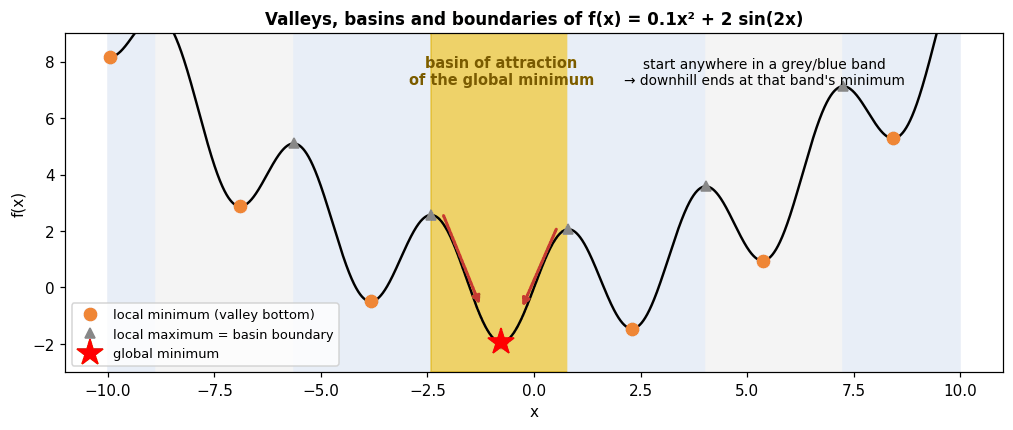

**Line by line.**
- `def f_wavy(x):` / `x = np.asarray(x, dtype=float)` — converts the input to a float array, so the function accepts a plain number, a list or an array.
- `return 0.1 * x**2 + 2 * np.sin(2 * x)` — the formula, applied element-wise.
- `W_LO, W_HI = -10.0, 10.0` — the search interval, reused later by the neighbour function to clip moves.
- `xx = np.linspace(W_LO, W_HI, 200_001)` — 200,001 points (the underscore is just a digit separator). The odd count makes the spacing exactly $20/200000 = 10^{-4}$ and includes 0.
- `yy = f_wavy(xx)` — all function values at once.
- `is_min = (yy[1:-1] < yy[:-2]) & (yy[1:-1] < yy[2:])` — the key line. Three *shifted views* of the same array are compared:
  - `yy[1:-1]` = every interior point (all but the first and last),
  - `yy[:-2]` = the point immediately to the **left** of each of those,
  - `yy[2:]` = the point immediately to the **right**.
  The two comparisons give boolean arrays; `&` keeps positions where **both** are true, i.e. points lower than both neighbours. No loop is needed.
- `loc_x, loc_f = xx[1:-1][is_min], yy[1:-1][is_min]` — boolean indexing selects the x and f values of those local minima. We index `xx[1:-1]` (not `xx`) because `is_min` was computed on interior points only, so the lengths must match.
- `X_STAR, F_STAR = xx[np.argmin(yy)], yy.min()` — `np.argmin` returns the index of the smallest value; this is the global minimum on the fine grid.
- `print(f"{len(loc_x)} local minima found:")` and the loop — print each minimum; `np.isclose(x, X_STAR)` (equality with a floating-point tolerance) marks the global one.
- Plotting: `"k-"` = black line; the orange dots are the local minima; the red star is the global minimum.

**Reading the output.** Seven minima at $x \approx -9.95, -6.89, -3.83, -0.77, 2.30, 5.36, 8.42$. They are spaced about $\pi$ apart, matching the period of $\sin(2x)$. The global one is at $x = -0.77$, $f = -1.94$; the one at $x = 2.30$, $f = -1.46$ is a tempting runner-up. Any method that starts on the right-hand side has to climb out of several valleys to reach the best one.

### 1.4 Why not always use brute force? Combinatorial explosion
Brute force is guaranteed to find the optimum on a finite search space, but the size of that space explodes:

- **Continuous, $d$ dimensions, 100 grid points per axis:** $100^d$ points.
- **Binary, $n$ yes/no decisions** (e.g., knapsack): $2^n$ subsets.
- **TSP with $n$ cities:** $(n-1)!/2$ distinct tours.

Assume a fast computer evaluates **one million solutions per second**:

In [12]:
def human_time(seconds):
    for unit, size in [("years", 3.15e7), ("days", 86400), ("hours", 3600), ("minutes", 60)]:
        if seconds >= size:
            return f"{seconds / size:,.3g} {unit}"
    return f"{seconds:.3g} seconds"

EVALS_PER_SEC = 1e6
print(f"{'Problem':30s}{'# solutions':>16s}   time to try them all")
print("-" * 72)
for d in [1, 2, 3, 5, 10]:
    n = 100.0 ** d
    print(f"{'Grid, ' + str(d) + '-D (100 pts/axis)':30s}{n:16.3g}   {human_time(n / EVALS_PER_SEC)}")
for nb in [10, 20, 40, 64]:
    n = 2.0 ** nb
    print(f"{'Binary, ' + str(nb) + ' bits':30s}{n:16.3g}   {human_time(n / EVALS_PER_SEC)}")
for nc in [5, 10, 15, 20, 30]:
    n = math.factorial(nc - 1) / 2
    print(f"{'TSP, ' + str(nc) + ' cities':30s}{n:16.3g}   {human_time(n / EVALS_PER_SEC)}")
print("\nFor scale: the universe is about 1.4e10 years old.")

Problem                            # solutions   time to try them all
------------------------------------------------------------------------
Grid, 1-D (100 pts/axis)                   100   0.0001 seconds
Grid, 2-D (100 pts/axis)                 1e+04   0.01 seconds
Grid, 3-D (100 pts/axis)                 1e+06   1 seconds
Grid, 5-D (100 pts/axis)                 1e+10   2.78 hours
Grid, 10-D (100 pts/axis)                1e+20   3.17e+06 years
Binary, 10 bits                       1.02e+03   0.00102 seconds
Binary, 20 bits                       1.05e+06   1.05 seconds
Binary, 40 bits                        1.1e+12   12.7 days
Binary, 64 bits                       1.84e+19   5.86e+05 years
TSP, 5 cities                               12   1.2e-05 seconds
TSP, 10 cities                        1.81e+05   0.181 seconds
TSP, 15 cities                        4.36e+10   12.1 hours
TSP, 20 cities                        6.08e+16   1.93e+03 years
TSP, 30 cities                        4.42e+30

#### 🔍 Explanation of the cell above — combinatorial explosion

**Concept.** Brute force is *correct* but *unaffordable* for realistic problem sizes, because the number of candidate solutions grows exponentially (or faster) with problem size. Three common growth laws are tabulated:
- **Continuous grid**: with $m$ points per axis in $d$ dimensions there are $m^d$ grid points. Adding one dimension multiplies the work by $m$.
- **Binary choices**: $n$ independent yes/no decisions give $2^n$ combinations (e.g. knapsack, feature selection).
- **Orderings (TSP)**: $n$ cities have $n!$ orderings. Starting at a different city gives the same closed tour (divide by $n$), and travelling it backwards gives the same tour too (divide by 2), so there are $n!/(2n) = (n-1)!/2$ *distinct* tours. Factorials grow even faster than exponentials.

To make the numbers concrete, the cell assumes a fast machine doing one million evaluations per second and converts the count into wall-clock time.

**Diagram.** The number of candidates (log scale) against problem size. The dashed lines mark how many evaluations fit into a second, a year, and the age of the universe at one million evaluations per second. Exponential and factorial curves cross all of them quickly.

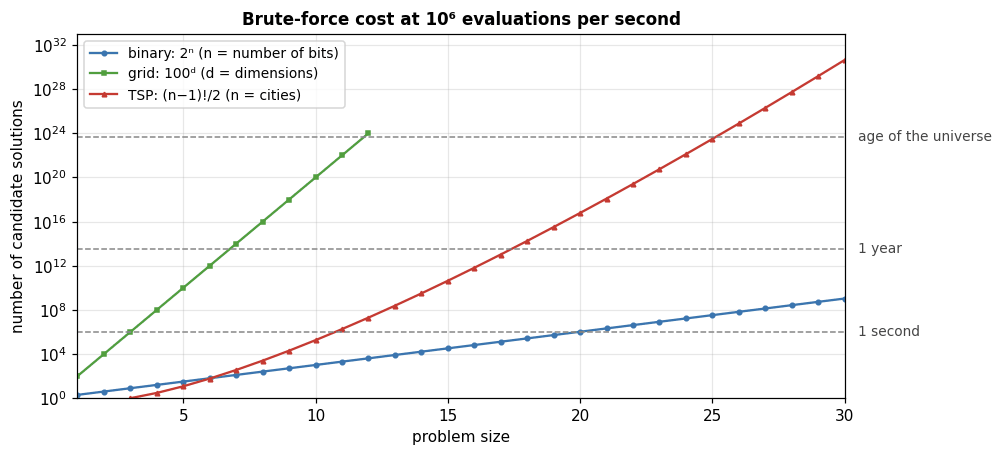

**Line by line.**
- `def human_time(seconds):` — turns a number of seconds into a readable string.
- `for unit, size in [("years", 3.15e7), ("days", 86400), ("hours", 3600), ("minutes", 60)]:` — candidate units with the number of seconds in each (one year ≈ $3.15\times10^7$ s), ordered from largest to smallest.
- `if seconds >= size: return f"{seconds / size:,.3g} {unit}"` — returns the first (largest) unit that fits. The format `,.3g` means 3 significant digits with thousands separators.
- `return f"{seconds:.3g} seconds"` — fallback for durations under one minute.
- `EVALS_PER_SEC = 1e6` — the assumed speed.
- The `print` with `{'Problem':30s}{'# solutions':>16s}` — header; `30s` left-aligns in 30 characters, `>16s` right-aligns in 16.
- `for d in [1, 2, 3, 5, 10]: n = 100.0 ** d` — grid size. Using the float `100.0` avoids gigantic Python integers and prints neatly in scientific notation.
- `for nb in [10, 20, 40, 64]: n = 2.0 ** nb` — binary problem sizes.
- `for nc in [5, 10, 15, 20, 30]: n = math.factorial(nc - 1) / 2` — distinct TSP tours, as explained above.
- Each loop prints the count (`16.3g` = 3 significant digits, 16 wide) and `human_time(n / EVALS_PER_SEC)`.
- The final print gives the age of the universe as a reference point.

**Reading the output.** 3-D at 100 points per axis takes 1 second, but 10-D takes about 3 million years. 40 bits take about 13 days; 64 bits take 586,000 years. 20 cities take about 1,900 years and 30 cities $1.4\times10^{17}$ years, ten million times the age of the universe. This is the motivation for *metaheuristics*: they give up the guarantee of optimality to get good answers in practical time.

**Takeaway:** exhaustive search is only possible for tiny problems. Metaheuristics such as SA and GA give up the *guarantee* of optimality in exchange for finding *very good* solutions in reasonable time.

### 1.5 Tiny problem we can solve exactly
Small problems are valuable because **we can compute the true optimum by brute force** and then check whether SA and GA find it. This is how you test an optimizer before trusting it on problems where the answer is unknown.

**The 0/1 knapsack problem.** You have a bag with a weight limit and items that each have a weight and a value. Choose items (each one in or out) to **maximize total value** without exceeding the weight limit. A solution is a bit string: `1011` means "take items A, C, D".

First, a version small enough to check every subset by hand:

In [7]:
import itertools

items    = ["A", "B", "C", "D"]
weights  = np.array([5, 4, 3, 2])
values   = np.array([10, 7, 5, 3])
CAPACITY = 7

print("bits  items      weight  value  feasible?")
best_bits, best_val = None, -1
for bits in itertools.product([0, 1], repeat=4):       # all 2^4 = 16 subsets
    b = np.array(bits)
    w, v = b @ weights, b @ values
    ok = w <= CAPACITY
    chosen = "".join(i for i, bit in zip(items, bits) if bit) or "-"
    print(f"{''.join(map(str, bits))}  {chosen:9s}  {w:5d}  {v:5d}   {'yes' if ok else 'NO'}")
    if ok and v > best_val:
        best_bits, best_val = b, v
print(f"\nOptimum: take {[i for i, bit in zip(items, best_bits) if bit]} -> value {best_val}")

bits  items      weight  value  feasible?
0000  -              0      0   yes
0001  D              2      3   yes
0010  C              3      5   yes
0011  CD             5      8   yes
0100  B              4      7   yes
0101  BD             6     10   yes
0110  BC             7     12   yes
0111  BCD            9     15   NO
1000  A              5     10   yes
1001  AD             7     13   yes
1010  AC             8     15   NO
1011  ACD           10     18   NO
1100  AB             9     17   NO
1101  ABD           11     20   NO
1110  ABC           12     22   NO
1111  ABCD          14     25   NO

Optimum: take ['A', 'D'] -> value 13


#### 🔍 Explanation of the cell above — exhaustive 4-item knapsack

**Concept.** The **0/1 knapsack problem**: each item is either taken (1) or left (0); maximise total value subject to total weight ≤ capacity. Three concepts appear in their simplest form:
- **Encoding**: a solution is a bit string of length $n$, so the search space has $2^n$ points (here 16).
- **Constraint and feasibility**: some bit strings break the weight limit. They are *infeasible* and cannot be the answer however valuable they are.
- **Exhaustive enumeration**: when $2^n$ is small, simply check every string and keep the best feasible one. The result is guaranteed optimal and serves as ground truth.

The weight and value of a selection are dot products: if $b$ is the 0/1 vector, total weight $= \sum_i b_i w_i = b \cdot w$. Unchosen items contribute 0.

**Diagram.** How a knapsack solution is encoded. Each item gets one bit; the total weight and value are dot products of the bit string with the weight and value vectors. This is the optimal subset {A, D}.

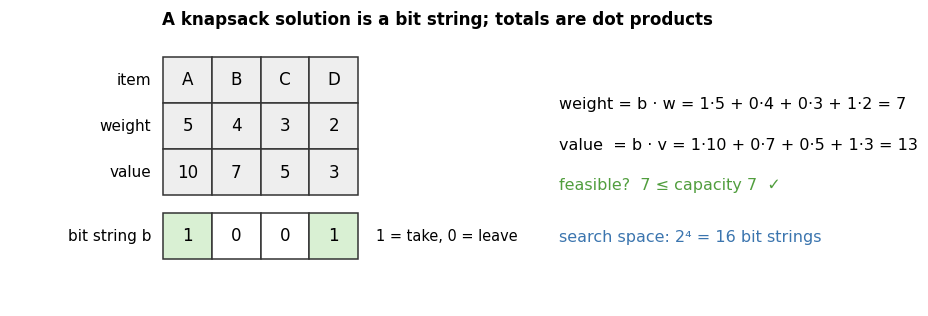

**Line by line.**
- `import itertools` — already imported in the setup cell; repeated here so the cell also works on its own.
- `items`, `weights`, `values`, `CAPACITY` — problem data: four items A–D and a bag limit of 7.
- `print("bits  items ...")` — table header.
- `best_bits, best_val = None, -1` — best feasible solution so far; starting at −1 guarantees that any feasible subset (value ≥ 0) will replace it.
- `for bits in itertools.product([0, 1], repeat=4):` — the Cartesian product of {0, 1} with itself four times: (0,0,0,0), (0,0,0,1), …, (1,1,1,1). This is binary counting, so all 16 subsets appear once each.
- `b = np.array(bits)` — tuple to array so `@` works.
- `w, v = b @ weights, b @ values` — total weight and value via dot products.
- `ok = w <= CAPACITY` — feasibility test.
- `chosen = "".join(i for i, bit in zip(items, bits) if bit) or "-"` — builds a label like `"AD"` from the items whose bit is 1. An empty string is "falsy" in Python, so `or "-"` replaces it with a dash for the empty subset.
- The `print` formats one table row; `''.join(map(str, bits))` turns (1,0,0,1) into `"1001"`.
- `if ok and v > best_val: best_bits, best_val = b, v` — keep the best feasible subset. The strict `>` keeps the first one found if values tie.
- Final print: the list comprehension turns the best bit vector back into item names.

**Reading the output.** The four most valuable subsets are all infeasible (marked NO). The optimum is {A, D}: weight 7, value 13. {B, C} has the same weight but value 12. This pattern, where the most attractive solutions sit just past the constraint, is typical of constrained problems.

### 1.6 Neighbourhoods and local search: the core building block
Both SA and GA (through mutation) rely on making **small changes** to a solution. The set of solutions reachable by one small change is called the **neighbourhood** $N(\mathbf{x})$.

| Representation | Example solution | Typical neighbour move |
|---|---|---|
| Real number(s) | $x = 2.7$ | Add a small random step: $x + \epsilon$ |
| Bit string | `10110` | Flip one bit: `10010` |
| Permutation (tour) | `[0 3 1 2 4]` | Reverse a segment: `[0 2 1 3 4]` |

**Key insight:** "local minimum" is always defined *relative to a neighbourhood*. A point is a local minimum if **no neighbour** is better. Change the neighbourhood (for example, take bigger steps) and some local minima disappear.

In [13]:
rng = np.random.default_rng(0)

def real_neighbour(x, step, rng):
    return float(np.clip(x + rng.normal(0, step), W_LO, W_HI))

def bitflip_neighbour(bits, rng):
    new = bits.copy(); i = rng.integers(len(bits)); new[i] ^= 1
    return new

def reverse_segment_neighbour(tour, rng):
    i, j = sorted(rng.choice(len(tour), 2, replace=False))
    new = tour.copy(); new[i:j + 1] = new[i:j + 1][::-1]
    return new

print("real      :", 2.7, "->", [round(real_neighbour(2.7, 0.3, rng), 2) for _ in range(4)])
b = np.array([1, 0, 1, 1, 0])
print("bit string:", b, "->", [bitflip_neighbour(b, rng).tolist() for _ in range(3)])
t0 = np.array([0, 3, 1, 2, 4])
print("tour      :", t0, "->", [reverse_segment_neighbour(t0, rng).tolist() for _ in range(3)])

real      : 2.7 -> [2.74, 2.66, 2.89, 2.73]
bit string: [1 0 1 1 0] -> [[0, 0, 1, 1, 0], [1, 0, 1, 1, 1], [1, 0, 1, 0, 0]]
tour      : [0 3 1 2 4] -> [[0, 3, 2, 1, 4], [0, 3, 1, 4, 2], [0, 3, 4, 2, 1]]


#### 🔍 Explanation of the cell above — neighbourhood (move) operators

**Concept.** A **neighbourhood** $N(x)$ is the set of solutions you can reach from $x$ with one small change, called a *move*. Local search, SA and GA mutation are all built on moves. The right move depends on the representation:
- **Real numbers**: add a small random step, $x' = x + \varepsilon$ with $\varepsilon \sim \mathcal{N}(0, \sigma^2)$. The step size $\sigma$ sets how far one move can reach.
- **Bit strings**: flip one bit. Every string has exactly $n$ neighbours.
- **Permutations**: you cannot change one entry on its own without creating duplicates, so moves rearrange entries. *Reversing a segment* (2-opt) keeps the result a valid permutation.

A point is a *local* optimum only **with respect to a neighbourhood**. A larger neighbourhood (bigger steps, more bits flipped) means fewer local optima but more candidates to look at.

**Diagram.** The three move types. A real value moves by a random Gaussian step (most neighbours are close; σ sets the reach). A bit string flips one position. A tour reverses a segment, which keeps every city exactly once.

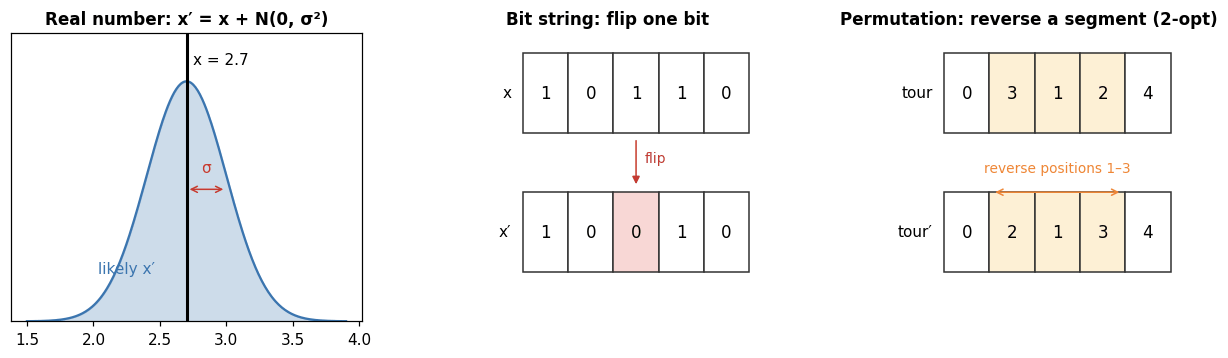

**Line by line.**
- `rng = np.random.default_rng(0)` — seeded generator for the demo.
- `def real_neighbour(x, step, rng):` — `rng.normal(0, step)` draws Gaussian noise with mean 0 and standard deviation `step`; `np.clip(..., W_LO, W_HI)` keeps the result inside [−10, 10]; `float(...)` turns the NumPy scalar into a plain Python float.
- `def bitflip_neighbour(bits, rng):`
  - `new = bits.copy()` — copy first, so the original solution is not modified. (Arrays are passed by reference; changing `bits` in place would silently change the caller's solution.)
  - `i = rng.integers(len(bits))` — a random position 0…n−1.
  - `new[i] ^= 1` — XOR with 1 flips a bit: 0 ^ 1 = 1 and 1 ^ 1 = 0.
- `def reverse_segment_neighbour(tour, rng):`
  - `rng.choice(len(tour), 2, replace=False)` — two *different* positions.
  - `sorted(...)` — order them so that `i < j`.
  - `new = tour.copy(); new[i:j + 1] = new[i:j + 1][::-1]` — copy, then reverse the inclusive slice from i to j (`[::-1]` reverses an array). The result is still a permutation because the same cities are only reordered.
- The three `print` lines show neighbours of 2.7 with step 0.3, of the bit string `10110`, and of the tour `[0 3 1 2 4]`. `.tolist()` prints arrays as clean Python lists.

**Reading the output.** The real-valued neighbours are close to 2.7; each bit-string neighbour differs from the original in exactly one position; each tour neighbour contains the same five cities with one segment reversed.

**Hill climbing (greedy local search)** is the simplest algorithm built on neighbourhoods:
```
x ← starting point
repeat:
    x' ← a random neighbour of x
    if f(x') < f(x):  x ← x'        # only ever move downhill
```
Let's trace it step by step on the wavy function, starting from $x_0 = 6$.

In [17]:
def hill_climb_1d(f, x0, step=0.3, n_iters=200, rng=None, verbose=0):
    rng = rng or np.random.default_rng()
    x, fx = x0, f(x0)
    trace = [(x, fx)]
    if verbose:
        print(f"{'iter':>4} {'x':>7} {'f(x)':>7} | {'cand':>7} {'f(cand)':>8}  decision")
    for k in range(n_iters):
        cand = real_neighbour(x, step, rng)
        fc = f(cand)
        better = fc < fx
        if k < verbose:
            print(f"{k:4d} {x:7.3f} {fx:7.3f} | {cand:7.3f} {fc:8.3f}  {'ACCEPT (better)' if better else 'reject (worse)'}")
        if better:
            x, fx = cand, fc
        trace.append((x, fx))
    return x, fx, np.array(trace)

x_end, f_end, _ = hill_climb_1d(f_wavy, 6.0, rng=np.random.default_rng(1), verbose=12)
print(f"\nAfter 200 iterations: x = {x_end:.3f}, f = {f_end:.3f}   (global minimum is f = {F_STAR:.3f} at x = {X_STAR:.3f})")

iter       x    f(x) |    cand  f(cand)  decision
   0   6.000   2.527 |   6.104    3.023  reject (worse)
   1   6.000   2.527 |   6.246    3.755  reject (worse)
   2   6.000   2.527 |   6.099    3.000  reject (worse)
   3   6.000   2.527 |   5.609    1.195  ACCEPT (better)
   4   5.609   1.195 |   5.881    2.016  reject (worse)
   5   5.609   1.195 |   5.743    1.534  reject (worse)
   6   5.609   1.195 |   5.448    0.978  ACCEPT (better)
   7   5.448   0.978 |   5.622    1.223  reject (worse)
   8   5.448   0.978 |   5.557    1.103  reject (worse)
   9   5.448   0.978 |   5.536    1.071  reject (worse)
  10   5.448   0.978 |   5.456    0.984  reject (worse)
  11   5.448   0.978 |   5.612    1.201  reject (worse)

After 200 iterations: x = 5.359, f = 0.948   (global minimum is f = -1.940 at x = -0.766)


#### 🔍 Explanation of the cell above — hill climbing with a printed trace

**Concept.** **Hill climbing** (here "descending", since we minimise) is the simplest local search: propose a random neighbour and move there *only if it is better*. It is greedy, exploiting information about the current point only. Its fatal flaw is that once every neighbour is worse it cannot move, so it stops at the bottom of whichever valley it started in: a local, not necessarily global, minimum. Printing each decision makes this visible.

This version is *stochastic*: it samples one random neighbour per step rather than checking all neighbours. It also runs for a fixed number of iterations rather than stopping when stuck, so the evaluation budget is known in advance.

**Diagram.** Flowchart of `hill_climb_1d`. The only way to move is the green "yes" branch, which requires strict improvement. That single rule is why hill climbing stops at the first valley bottom it reaches.

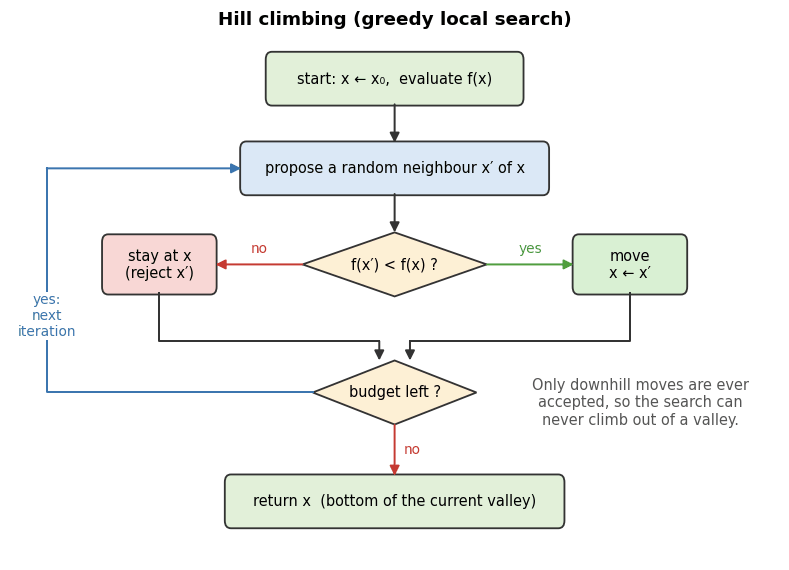

**Line by line.**
- `def hill_climb_1d(f, x0, step=0.3, n_iters=200, rng=None, verbose=0):` — `f` is the objective, `x0` the start, `step` the neighbour size, `n_iters` the budget, `verbose` how many steps to print.
- `rng = rng or np.random.default_rng()` — use the generator passed in; if it is `None`, `or` falls through and creates a fresh, unseeded one.
- `x, fx = x0, f(x0)` — current point and its value. Storing `fx` avoids recomputing it.
- `trace = [(x, fx)]` — history of the current point, starting with the start.
- `if verbose: print(...)` — header for the printed table.
- `for k in range(n_iters):` — main loop.
  - `cand = real_neighbour(x, step, rng)` — propose a random nearby point.
  - `fc = f(cand)` — evaluate it (one function evaluation per iteration).
  - `better = fc < fx` — strict improvement test.
  - `if k < verbose: print(...)` — print only the first `verbose` iterations, labelling each decision ACCEPT or reject.
  - `if better: x, fx = cand, fc` — move only downhill.
  - `trace.append((x, fx))` — record the current point *every* iteration, including when it did not move, so `trace` has `n_iters + 1` rows.
- `return x, fx, np.array(trace)` — final point, value, and a (n_iters+1, 2) array of the path.
- The call starts at $x_0 = 6$ with seed 1, prints 12 steps, then reports the end point against the global optimum.

**Reading the output.** From $x = 6$ the climber moves to 5.609 and then 5.448, rejecting every uphill proposal. After 200 iterations it is at $x = 5.359$, $f = 0.948$: the bottom of the local valley near 5.36. The global minimum ($f = -1.94$ at $x = -0.77$) is three valleys away, and with only downhill moves allowed it is unreachable.

start  -8.5 -> stops at x =  -6.89, f =   2.87
start  -4.5 -> stops at x =  -3.83, f =  -0.50
start  -2.0 -> stops at x =  -0.77, f =  -1.94   (global)
start   1.0 -> stops at x =   2.30, f =  -1.46
start   4.0 -> stops at x =   5.36, f =   0.95
start   7.0 -> stops at x =   5.36, f =   0.95
start   9.5 -> stops at x =   8.42, f =   5.28


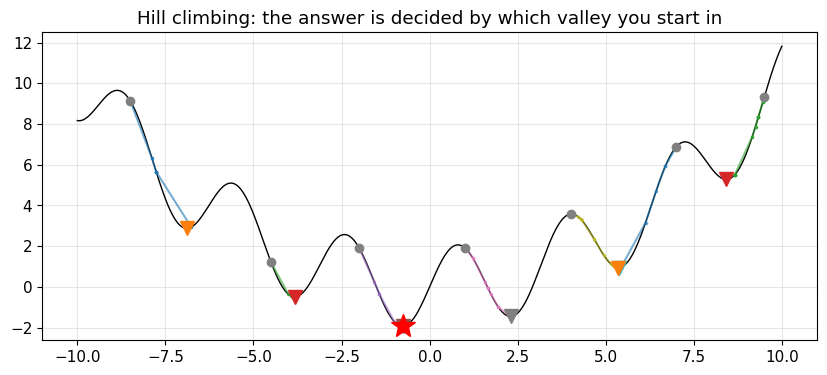

In [18]:
# Where does hill climbing end up from different starting points?
plt.figure(figsize=(10, 4))
xx_plot = np.linspace(W_LO, W_HI, 1000)
plt.plot(xx_plot, f_wavy(xx_plot), "k-", lw=1)
rng = np.random.default_rng(3)
for x0 in [-8.5, -4.5, -2.0, 1.0, 4.0, 7.0, 9.5]:
    xe, fe, tr = hill_climb_1d(f_wavy, x0, rng=rng)
    plt.plot(tr[:, 0], tr[:, 1], ".-", ms=3, alpha=0.6)
    plt.plot(x0, f_wavy(x0), "o", color="gray"); plt.plot(xe, fe, "v", ms=10)
    print(f"start {x0:5.1f} -> stops at x = {xe:6.2f}, f = {fe:6.2f}" + ("   (global)" if abs(xe - X_STAR) < 0.5 else ""))
plt.plot(X_STAR, F_STAR, "r*", ms=18)
plt.title("Hill climbing: the answer is decided by which valley you start in"); plt.show()

#### 🔍 Explanation of the cell above — hill climbing from many starts (basins of attraction)

**Concept.** Since hill climbing always ends at the bottom of the valley it starts in, the answer is decided by the **basin of attraction** containing the start. Running it from many starting points shows this directly: each start slides to its own local minimum. (Restarting from many random points, *random-restart hill climbing*, is in fact a simple way to make hill climbing more global. Its success rate is roughly the fraction of the search space covered by the global basin.)

**Line by line.**
- `plt.figure(figsize=(10, 4))` — new figure.
- `xx_plot = np.linspace(W_LO, W_HI, 1000)` and `plt.plot(xx_plot, f_wavy(xx_plot), "k-", lw=1)` — draw the function as a thin black line. `xx_plot` is reused in later cells.
- `rng = np.random.default_rng(3)` — one generator shared by all seven runs (each run continues the same random stream).
- `for x0 in [-8.5, -4.5, -2.0, 1.0, 4.0, 7.0, 9.5]:` — seven hand-picked starting points spread across the domain.
  - `xe, fe, tr = hill_climb_1d(f_wavy, x0, rng=rng)` — run with the default step 0.3 and 200 iterations.
  - `plt.plot(tr[:, 0], tr[:, 1], ".-", ms=3, alpha=0.6)` — the path: column 0 is x, column 1 is f(x); `".-"` = small dots joined by lines; `alpha` = transparency.
  - `plt.plot(x0, f_wavy(x0), "o", color="gray")` — the start (grey circle); `plt.plot(xe, fe, "v", ms=10)` — the end (triangle).
  - The `print` reports start and end, adding "(global)" when the end lies within 0.5 of the true global minimum.
- `plt.plot(X_STAR, F_STAR, "r*", ms=18)` — the global minimum.

**Reading the output.** Each start ends in the nearest valley: −8.5 → −6.89, −4.5 → −3.83, 1.0 → 2.30, and so on. Only the start at −2.0 lies in the global basin. Starts 4.0 and 7.0 both end at 5.36 because they lie in the same basin.

### 1.7 Randomness 101
SA and GA are **stochastic**: they make random choices. Two ideas are needed.

**1. Seeds make randomness reproducible.** A random number generator created with the same seed produces the same sequence every time. That is essential for debugging and for reproducible papers.

**2. "Do something with probability $p$"** is implemented as `if rng.random() < p:`. Since `rng.random()` is uniform on $[0, 1)$, the condition is true exactly a fraction $p$ of the time. SA uses this to accept bad moves; GA uses it for crossover and mutation.

In [19]:
a = np.random.default_rng(7).random(3)
b = np.random.default_rng(7).random(3)
c = np.random.default_rng(8).random(3)
print("seed 7 :", np.round(a, 4))
print("seed 7 :", np.round(b, 4), " <- identical")
print("seed 8 :", np.round(c, 4), " <- different\n")

rng = np.random.default_rng(0)
for p in [0.1, 0.3, 0.75]:
    hits = sum(rng.random() < p for _ in range(10_000))
    print(f"'accept with probability {p}' -> accepted {hits / 10_000:.3f} of 10,000 trials")

seed 7 : [0.6251 0.8972 0.7757]
seed 7 : [0.6251 0.8972 0.7757]  <- identical
seed 8 : [0.327  0.9873 0.3187]  <- different

'accept with probability 0.1' -> accepted 0.103 of 10,000 trials
'accept with probability 0.3' -> accepted 0.284 of 10,000 trials
'accept with probability 0.75' -> accepted 0.753 of 10,000 trials


#### 🔍 Explanation of the cell above — seeds and "do something with probability p"

**Concept.** Computers generate *pseudo-random* numbers: a deterministic algorithm that produces a sequence which looks random. The **seed** is that algorithm's starting state, so the same seed always gives the same sequence. This is what makes a stochastic experiment reproducible: rerun it with the same seed and you get identical results, which is essential for debugging and for publishing results.

The second idea is how to implement a random event. If $U$ is uniform on $[0, 1)$, then $P(U < p) = p$, because $p$ is exactly the length of the interval $[0, p)$. So `if rng.random() < p:` makes something happen with probability $p$. SA uses this to decide whether to accept a worse move, and GA uses it to decide whether to apply crossover or mutation.

**Line by line.**
- `a = np.random.default_rng(7).random(3)` — make a generator with seed 7 and draw three uniform numbers in [0, 1).
- `b = np.random.default_rng(7).random(3)` — a *fresh* generator with the same seed, so the same three numbers.
- `c = np.random.default_rng(8).random(3)` — a different seed, so different numbers.
- The three prints round to 4 decimals with `np.round` and show that `a` and `b` are identical.
- `rng = np.random.default_rng(0)` — a generator for the probability test.
- `for p in [0.1, 0.3, 0.75]:` — three target probabilities.
  - `hits = sum(rng.random() < p for _ in range(10_000))` — 10,000 trials; each comparison is a boolean, and Python's `sum` counts `True` as 1. The `_` loop variable means "the counter is not used".
  - `print(... hits / 10_000 ...)` — observed fraction.

**Reading the output.** Seed 7 gives `[0.6251 0.8972 0.7757]` twice; seed 8 gives different numbers. The observed acceptance fractions (0.103, 0.284, 0.753) are close to 0.1, 0.3 and 0.75. They are not exact because 10,000 trials is a finite sample; the deviation shrinks roughly like $1/\sqrt{\text{trials}}$. This is also why later experiments report results over *several* seeds.

**Consequence:** a single run of a stochastic algorithm can be lucky or unlucky. **Always evaluate over several seeds** and report the mean, spread, or success rate. We do this throughout.

### 1.8 Exploration vs. exploitation
There are two opposite pure strategies:
- **Exploration (random search):** sample points anywhere. This is good at *finding the right valley* but poor at *finding its exact bottom*.
- **Exploitation (hill climbing):** only improve the current point. This is precise at *finding the bottom* but usually stuck in *the wrong valley*.

We give each strategy the same budget of 30 evaluations and repeat over 100 seeds:

In [22]:
def random_search_1d(f, n_evals, rng):
    xs = rng.uniform(W_LO, W_HI, n_evals)
    i = np.argmin(f(xs))
    return xs[i], f(xs[i])

BUDGET, RUNS = 30, 100
res = {"Random search (explore)": [], "Hill climbing (exploit)": []}
for s in range(RUNS):
    rng = np.random.default_rng(s)
    res["Random search (explore)"].append(random_search_1d(f_wavy, BUDGET, rng))
    xe, fe, _ = hill_climb_1d(f_wavy, rng.uniform(W_LO, W_HI), step=0.3, n_iters=BUDGET - 1, rng=rng)
    res["Hill climbing (exploit)"].append((xe, fe))

print(f"{'Strategy':26s}{'found global valley':>21s}{'avg error when in it':>23s}")
for name, r in res.items():
    r = np.array(r)
    in_basin = np.abs(r[:, 0] - X_STAR) < 0.5
    print(f"{name:26s}{in_basin.mean():>20.0%} {np.mean(r[in_basin, 1] - F_STAR):>22.4f}")

Strategy                    found global valley   avg error when in it
Random search (explore)                    65%                 0.1632
Hill climbing (exploit)                    16%                 0.0018


#### 🔍 Explanation of the cell above — exploration vs. exploitation at an equal budget

**Concept.** Every optimizer balances two activities:
- **Exploration**: looking at new, distant regions to find the right *valley*.
- **Exploitation**: refining the current best point to reach the *bottom* of its valley.

Pure random search is all exploration: it samples anywhere and keeps the best, so it often hits the right valley but rarely lands near the exact bottom. Hill climbing is all exploitation: it reaches the bottom of a valley very precisely, but usually the wrong one.

To compare them **fairly**, both get the *same number of function evaluations* (30) and are repeated over 100 seeds. Two metrics are reported: how often the method ends in the global valley (within 0.5 of $x^*$), and, *for those runs only*, how far above the true minimum it stopped. Separating the two shows the trade-off clearly.

**Diagram.** The same 30-evaluation budget spent two ways. Random search spreads its samples everywhere, so it usually lands in the right valley but not at its bottom. Hill climbing spends all its samples in one place, so it reaches the bottom precisely, but of whichever valley it started in.

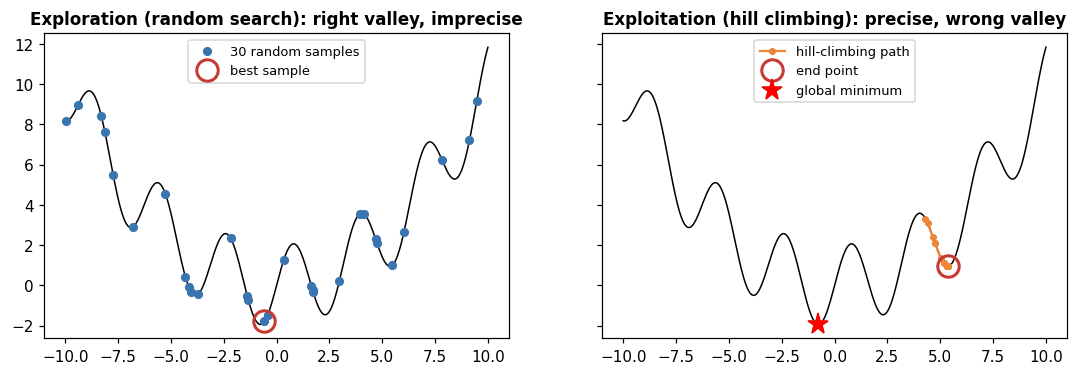

**Line by line.**
- `def random_search_1d(f, n_evals, rng):`
  - `xs = rng.uniform(W_LO, W_HI, n_evals)` — 30 uniform random points in [−10, 10].
  - `i = np.argmin(f(xs))` — evaluate all of them at once and find the best index.
  - `return xs[i], f(xs[i])` — best point and its value.
- `BUDGET, RUNS = 30, 100` — 30 evaluations per method per run, 100 runs.
- `res = {...: [], ...: []}` — a dictionary of result lists, one per strategy.
- `for s in range(RUNS): rng = np.random.default_rng(s)` — one seeded generator per run, used first by random search and then by hill climbing.
- `res["Random search (explore)"].append(random_search_1d(f_wavy, BUDGET, rng))` — store (x, f).
- `xe, fe, _ = hill_climb_1d(f_wavy, rng.uniform(W_LO, W_HI), step=0.3, n_iters=BUDGET - 1, rng=rng)` — a random start (1 evaluation) plus 29 iterations (29 evaluations) = 30 in total, the same as random search. `_` discards the trace.
- Analysis loop:
  - `r = np.array(r)` — shape (100, 2): column 0 is x, column 1 is f.
  - `in_basin = np.abs(r[:, 0] - X_STAR) < 0.5` — boolean per run: did it end in the global valley?
  - `in_basin.mean()` — success fraction, printed with the `%` format.
  - `np.mean(r[in_basin, 1] - F_STAR)` — the average gap to the true minimum, over successful runs only.

**Reading the output.** Random search reaches the global valley in 65% of runs but stops on average 0.16 above the bottom. Hill climbing reaches it in only 16% of runs, but when it does, it is within 0.0018 of the bottom. Each strategy is good at exactly one thing. SA and GA are designed to get both.

**Interpretation.** Random search usually lands in the right valley but stops well above its bottom. Hill climbing is very precise, but usually in the wrong valley. **We want both**, and the two algorithms in this notebook get both in different ways:

| | How it explores | How it exploits |
|---|---|---|
| **Simulated Annealing** | Early on (high temperature), it accepts worse moves | Later (low temperature), it behaves like hill climbing |
| **Genetic Algorithm** | Mutation, crossover, and a diverse population | Selection keeps the fitter solutions |

With these foundations in place, we move to a harder benchmark.

---
## Part 2 — Harder benchmarks (Rastrigin, 8-queens) and the greedy baseline  

The wavy 1-D function had 7 local minima. Real problems are multi-dimensional, and the number of local minima grows **exponentially** with dimension. We want to solve
$$
\mathbf{x}^* = \arg\min_{\mathbf{x} \in \mathcal{S}} f(\mathbf{x})
$$
where $f$ may be **non-convex, non-differentiable, or discrete**, so gradient descent is unavailable or useless.

**Running example 1 — the Rastrigin function** (a classic multimodal benchmark):
$$
f(\mathbf{x}) = A\,d + \sum_{i=1}^{d}\left[x_i^2 - A\cos(2\pi x_i)\right], \quad A=10,\; x_i\in[-5.12,\,5.12]
$$
- Global minimum: $f(\mathbf{0}) = 0$.
- Roughly $11^d$ local minima: about 121 in 2-D and about $2.6\times10^{10}$ in 10-D.

**Running example 2 — the Travelling Salesman Problem (TSP)** (combinatorial; introduced in Part 3).

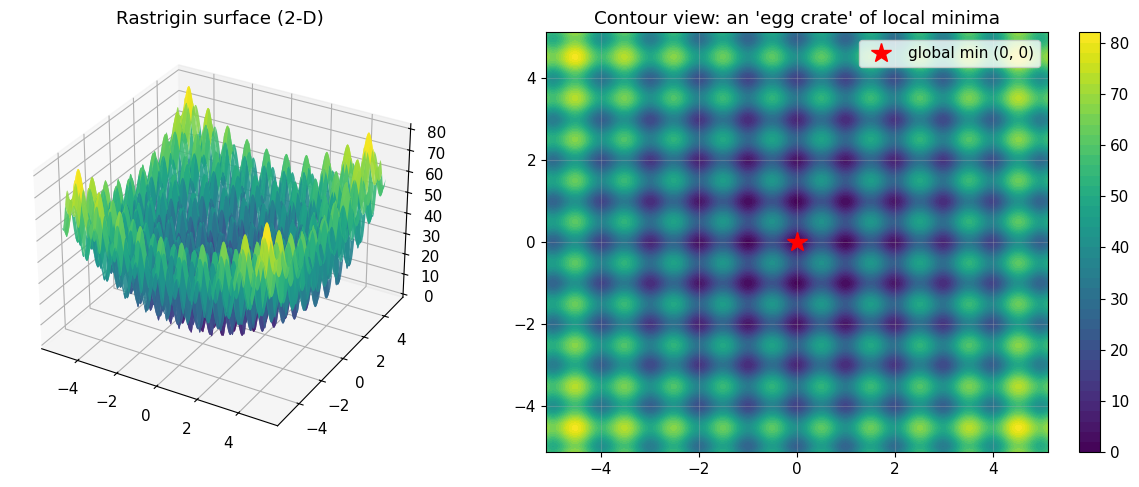

f(0,0) = 0.0 | f(1,1) = 2.0 | f(4,4) = 32.0


In [23]:
def rastrigin(x, A=10.0):
    # Vectorised: accepts a single point of shape (d,) or a population of shape (N, d).
    x = np.asarray(x, dtype=float)
    return A * x.shape[-1] + np.sum(x**2 - A * np.cos(2 * np.pi * x), axis=-1)

BOUNDS = (-5.12, 5.12)

# Visualise the 2-D landscape
g = np.linspace(*BOUNDS, 400)
X, Y = np.meshgrid(g, g)
Z = rastrigin(np.stack([X, Y], axis=-1))

fig = plt.figure(figsize=(13, 5))
ax1 = fig.add_subplot(1, 2, 1, projection="3d")
ax1.plot_surface(X, Y, Z, cmap="viridis", linewidth=0, antialiased=True, alpha=0.9)
ax1.set_title("Rastrigin surface (2-D)")
ax2 = fig.add_subplot(1, 2, 2)
cs = ax2.contourf(X, Y, Z, levels=40, cmap="viridis")
plt.colorbar(cs, ax=ax2)
ax2.plot(0, 0, "r*", ms=15, label="global min (0, 0)")
ax2.set_title("Contour view: an 'egg crate' of local minima")
ax2.legend()
plt.tight_layout(); plt.show()

print("f(0,0) =", rastrigin([0, 0]), "| f(1,1) =", rastrigin([1, 1]), "| f(4,4) =", rastrigin([4, 4]))

#### 🔍 Explanation of the cell above — the Rastrigin benchmark

**Concept.** Benchmark functions are standard test problems whose optimum is known, so different optimizers can be compared on the same ground. **Rastrigin** is a classic *multimodal* benchmark (one with many local minima):
$$f(\mathbf{x}) = A\,d + \sum_{i=1}^{d}\big[x_i^2 - A\cos(2\pi x_i)\big].$$
Each part has a job:
- $x_i^2$ is a bowl centred at 0: the global trend.
- $-A\cos(2\pi x_i)$ adds ripples with period 1, creating a dip near every integer coordinate. With $A = 10$ the ripples are much deeper than the bowl is steep near the centre, so the dips are real local minima.
- $A\,d$ is a constant offset that makes the global minimum exactly $f(\mathbf{0}) = 0$ (since $\cos 0 = 1$).

On $[-5.12, 5.12]$ each coordinate has about 11 dips (near −5, …, 5), and the dips combine independently across coordinates, so there are about $11^d$ local minima: 121 in 2-D and about $2.6\times10^{10}$ in 10-D. The function is also **separable**: it is a sum of 1-D terms, one per coordinate. Part 5 shows that this property can strongly favour some operators.

**Diagram.** Rastrigin in one dimension, built from its parts. The bowl gives the overall trend toward 0; the cosine ripples (period 1) carve a dip near every integer; the constant shifts the global minimum to exactly 0. In $d$ dimensions the dips combine independently, giving about $11^d$ local minima.

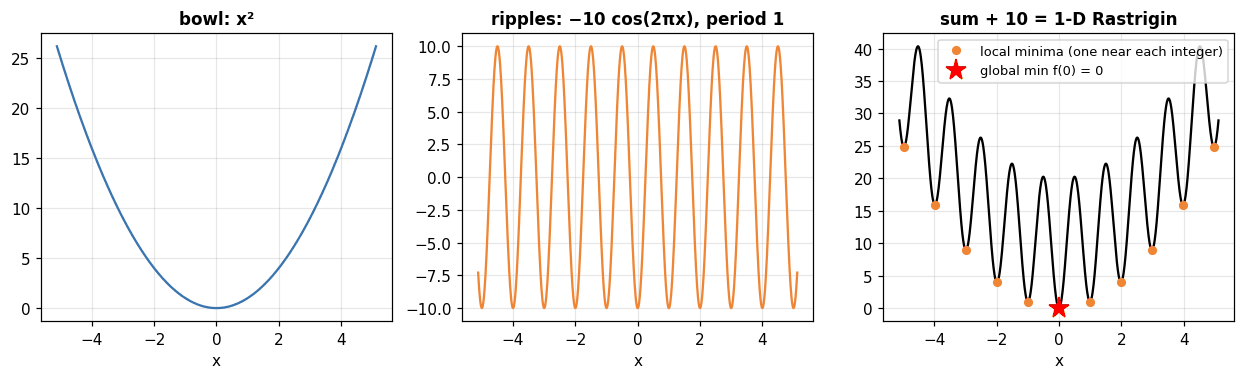

**Line by line.**
- `def rastrigin(x, A=10.0):`
  - `x = np.asarray(x, dtype=float)` — accept lists or arrays.
  - `return A * x.shape[-1] + np.sum(x**2 - A * np.cos(2 * np.pi * x), axis=-1)` — `x.shape[-1]` is the dimension $d$, i.e. the length of the last axis. Summing over `axis=-1` (the last axis) makes the same code work for one point of shape `(d,)` (returns a number), a population of shape `(N, d)` (returns N values) or a plotting grid of shape `(400, 400, 2)` (returns a 400 × 400 map). Vectorising like this is what makes the GA fast later on.
- `BOUNDS = (-5.12, 5.12)` — the standard search box, used by every later function.
- `g = np.linspace(*BOUNDS, 400)` — `*BOUNDS` unpacks the tuple into the two arguments −5.12 and 5.12; 400 points per axis.
- `X, Y = np.meshgrid(g, g)` — two 400 × 400 arrays holding the x and y coordinate of every grid point.
- `Z = rastrigin(np.stack([X, Y], axis=-1))` — `np.stack(..., axis=-1)` combines them into shape (400, 400, 2), where each entry is a 2-D point; `rastrigin` returns the (400, 400) height map.
- `fig = plt.figure(figsize=(13, 5))` — wide figure.
- `ax1 = fig.add_subplot(1, 2, 1, projection="3d")` — left panel as a 3-D axis.
- `ax1.plot_surface(X, Y, Z, cmap="viridis", linewidth=0, antialiased=True, alpha=0.9)` — surface plot, coloured by height.
- `ax2 = fig.add_subplot(1, 2, 2)`; `cs = ax2.contourf(X, Y, Z, levels=40, cmap="viridis")` — filled contour map with 40 colour bands (a top-down view).
- `plt.colorbar(cs, ax=ax2)` — colour scale next to the contour plot.
- `ax2.plot(0, 0, "r*", ...)` — the global minimum.
- `plt.tight_layout(); plt.show()` — tidy spacing and display.
- The final print checks three values.

**Reading the output.** $f(0,0) = 0$ (global minimum), $f(1,1) = 2$ (a nearby local minimum region), $f(4,4) = 32$ (a far-away local minimum). The plots show the "egg crate": a regular grid of dips on top of a bowl.

### Baseline: greedy hill climbing
Propose a small random move and accept it **only if it improves** $f$. This is fast, but it can never climb out of a basin.

start=[ 2.81 -0.63] -> end=[ 2.98 -1.  ], f=9.952
start=[3.67 2.02] -> end=[3.98 1.99], f=19.900
start=[-4.16  4.87] -> end=[-3.98  4.97], f=40.794
start=[2.67 2.93] -> end=[2.98 2.98], f=17.910
start=[-3.81 -0.51] -> end=[-3.98 -0.99], f=16.914
start=[-1.32  4.37] -> end=[-1.    3.98], f=16.914


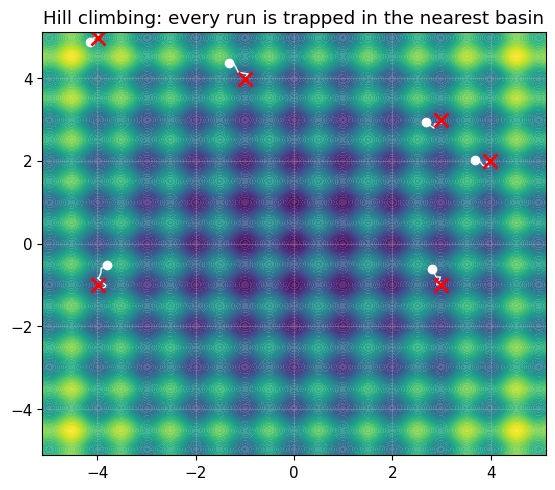

In [24]:
def hill_climb(f, x0, step=0.1, n_iters=3000, bounds=BOUNDS, rng=None):
    rng = rng or np.random.default_rng()
    x, fx = np.array(x0, float), f(x0)
    path, hist = [x.copy()], [fx]
    for _ in range(n_iters):
        cand = np.clip(x + rng.normal(0, step, size=x.shape), *bounds)
        fc = f(cand)
        if fc < fx:              # greedy: only downhill moves
            x, fx = cand, fc
        path.append(x.copy()); hist.append(fx)
    return x, fx, np.array(path), np.array(hist)

rng = np.random.default_rng(SEED)
starts = rng.uniform(*BOUNDS, size=(6, 2))
plt.figure(figsize=(6.5, 5.5))
plt.contourf(X, Y, Z, levels=40, cmap="viridis", alpha=0.85)
for s in starts:
    xb, fb, path, _ = hill_climb(rastrigin, s, rng=rng)
    plt.plot(path[:, 0], path[:, 1], "w-", lw=1)
    plt.plot(*s, "wo"); plt.plot(*xb, "rx", ms=10, mew=2)
    print(f"start={np.round(s, 2)} -> end={np.round(xb, 2)}, f={fb:.3f}")
plt.title("Hill climbing: every run is trapped in the nearest basin")
plt.show()

#### 🔍 Explanation of the cell above — hill climbing on 2-D Rastrigin

**Concept.** This is the hill climber from Part 1, generalised to $d$ dimensions. A move now adds Gaussian noise to *every* coordinate. On Rastrigin the basins are only about 1 unit wide, while a step of 0.1 is far too small to jump the ridge between them, so every run is trapped in the first basin it reaches.

A detail worth knowing: the local minima of Rastrigin are not exactly at integer points. The $x^2$ term pulls them slightly toward the origin, to about $0.995 \times$ the integer. That is why runs end at coordinates like 2.98 or 3.98 rather than 3 or 4.

**Line by line.**
- `def hill_climb(f, x0, step=0.1, n_iters=3000, bounds=BOUNDS, rng=None):`
  - `x, fx = np.array(x0, float), f(x0)` — the current point as a float array (a copy), and its value.
  - `path, hist = [x.copy()], [fx]` — lists recording every position and every value.
  - `for _ in range(n_iters):`
    - `cand = np.clip(x + rng.normal(0, step, size=x.shape), *bounds)` — perturb all coordinates (`size=x.shape` gives one noise value per coordinate) and clip into the box.
    - `fc = f(cand)` — evaluate.
    - `if fc < fx: x, fx = cand, fc` — greedy: accept only improvements.
    - `path.append(x.copy()); hist.append(fx)` — record. `.copy()` is a safety habit so later changes to `x` cannot alter stored history.
  - `return x, fx, np.array(path), np.array(hist)`.
- `rng = np.random.default_rng(SEED)`.
- `starts = rng.uniform(*BOUNDS, size=(6, 2))` — six random 2-D starting points.
- `plt.contourf(X, Y, Z, ...)` — reuses the contour grid from the previous cell as background.
- Loop over starts:
  - `xb, fb, path, _ = hill_climb(rastrigin, s, rng=rng)` — run (all runs share the generator).
  - `plt.plot(path[:, 0], path[:, 1], "w-", lw=1)` — white path line.
  - `plt.plot(*s, "wo")` — the start (`*s` unpacks the 2-D point into x, y).
  - `plt.plot(*xb, "rx", ms=10, mew=2)` — the end as a red cross (`mew` = marker edge width).
  - The print shows start, end and final f, rounded with `np.round`.

**Reading the output.** All six runs end near integer coordinates with $f$ between about 10 and 41. None comes close to 0, and the paths in the figure are short squiggles that never leave their starting basin. This is the failure SA and GA are designed to fix.

> **Key takeaway:** the final answer depends almost entirely on where you start. We need a mechanism to **escape local minima**. SA does this by *occasionally accepting worse moves*; GA does it by *searching with a population* and recombining solutions.

### The running example from the slides: the 8-queens problem
Place 8 queens on a chessboard so that **no two queens attack each other**: no two in the same row, column, or diagonal.

**Encoding used on the slides.** Put exactly one queen in each column, so a state is an 8-character string such as `24748552`: the $i$-th digit is the **row** (1–8, counted from the bottom) of the queen in column $i$. This gives $8^8 \approx 16.8$ million states.

**Two equivalent ways to score a state:**
- **Cost** $h$ = number of pairs of queens that attack each other. *Minimize*; a solution has $h = 0$. This is the natural "energy" for SA.
- **Fitness** = number of **non-attacking** pairs $= 28 - h$, since there are $\binom{8}{2} = 28$ pairs. *Maximize*; a solution has fitness 28. **This is the fitness used in the slides' GA figure** (24, 23, 20, 11).

24748552: attacking pairs h =  4,  fitness = 28 - h = 24
32752411: attacking pairs h =  5,  fitness = 28 - h = 23
24415124: attacking pairs h =  8,  fitness = 28 - h = 20
32543213: attacking pairs h = 17,  fitness = 28 - h = 11


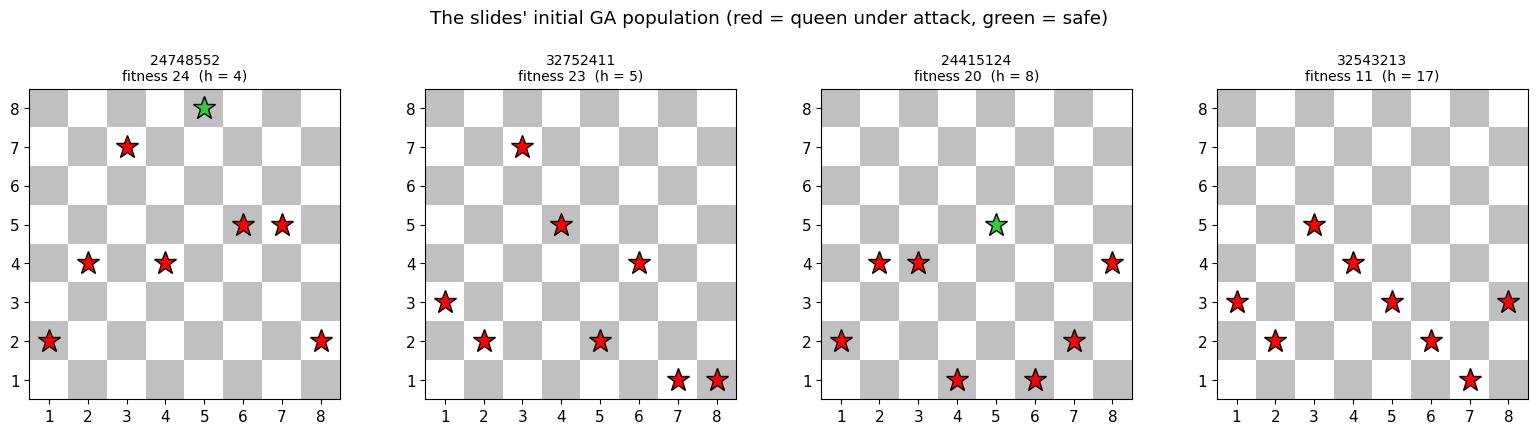

In [26]:
I8, J8 = np.triu_indices(8, 1)          # all 28 (column i, column j) pairs with i < j
D8 = J8 - I8                            # horizontal distance between the two columns

def queens(s):
    # '24748552' -> array([2, 4, 7, 4, 8, 5, 5, 2])
    return np.array([int(c) for c in s]) if isinstance(s, str) else np.asarray(s)

def to_str(state):
    return "".join(map(str, state))

def attacking_pairs(state):
    # Cost h: same row, or same diagonal (|row difference| == column distance).
    # Works for one state (8,) or a whole population (N, 8).
    P = np.atleast_2d(state)
    a, b = P[:, I8], P[:, J8]
    h = ((a == b) | (np.abs(a - b) == D8)).sum(axis=1)
    return h if np.ndim(state) == 2 else int(h[0])

def non_attacking_pairs(state):
    # Fitness used on the slides (max 28).
    return 28 - attacking_pairs(state)

def draw_board(state, ax, title=""):
    s = queens(state)
    ax.imshow(np.add.outer(np.arange(8), np.arange(8)) % 2, cmap="Greys", alpha=0.25,
              origin="lower", extent=(0.5, 8.5, 0.5, 8.5))
    attacked = {k for i, j in zip(I8, J8) if s[i] == s[j] or abs(s[i] - s[j]) == j - i for k in (i, j)}
    for c, r in enumerate(s):
        ax.plot(c + 1, r, marker="*", ms=17, mec="k", color="red" if c in attacked else "limegreen")
    ax.set_xticks(range(1, 9)); ax.set_yticks(range(1, 9)); ax.grid(False)
    ax.set_xlim(0.5, 8.5); ax.set_ylim(0.5, 8.5)
    ax.set_title(title, fontsize=10)

# Verify the fitness values printed on the slides' GA figure
slide_population = ["24748552", "32752411", "24415124", "32543213"]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, st in zip(axes, slide_population):
    print(f"{st}: attacking pairs h = {attacking_pairs(queens(st)):2d},  fitness = 28 - h = {non_attacking_pairs(queens(st))}")
    draw_board(st, ax, f"{st}\nfitness {non_attacking_pairs(queens(st))}  (h = {attacking_pairs(queens(st))})")
plt.suptitle("The slides' initial GA population (red = queen under attack, green = safe)", y=1.03)
plt.tight_layout(); plt.show()

#### 🔍 Explanation of the cell above — the 8-queens problem: encoding, cost, fitness, drawing

**Concept.** **8-queens**: place 8 queens on a chessboard so that none attacks another (no shared row, column or diagonal).

*Encoding.* Putting exactly one queen per column removes column clashes automatically. A state is then 8 numbers, the row (1–8) of the queen in each column; for example `24748552` means column 1 has its queen in row 2, column 2 in row 4, and so on. There are $8^8 \approx 16.8$ million states. A good encoding builds some constraints in, which shrinks the search space.

*Scoring.* There are $\binom{8}{2} = 28$ pairs of queens. Two queens in columns $i < j$ with rows $r_i, r_j$ attack each other if
- they are in the same row: $r_i = r_j$, or
- they are on the same diagonal: $|r_i - r_j| = j - i$. A diagonal rises or falls by one row per column, so the row difference equals the column distance.

**Cost** $h$ = number of attacking pairs (minimise; 0 means solved). **Fitness** $= 28 - h$ = number of non-attacking pairs (maximise; 28 means solved). These carry the same information. SA naturally uses cost ("energy"); the slides' GA uses fitness.

*Vectorisation.* Instead of a double loop over pairs, the code precomputes the 28 column pairs once and checks all pairs of all boards in one array operation. This matters because SA and GA evaluate thousands of boards.

**Diagram.** The two attack rules and the pair list. Left: two queens attack along a row when their row numbers are equal. Middle: they attack along a diagonal when the row difference equals the column distance (here 3 and 3). Right: the upper triangle of an 8 × 8 grid lists each pair of columns exactly once, 28 pairs in total; `attacking_pairs` checks both rules on all 28 at once.

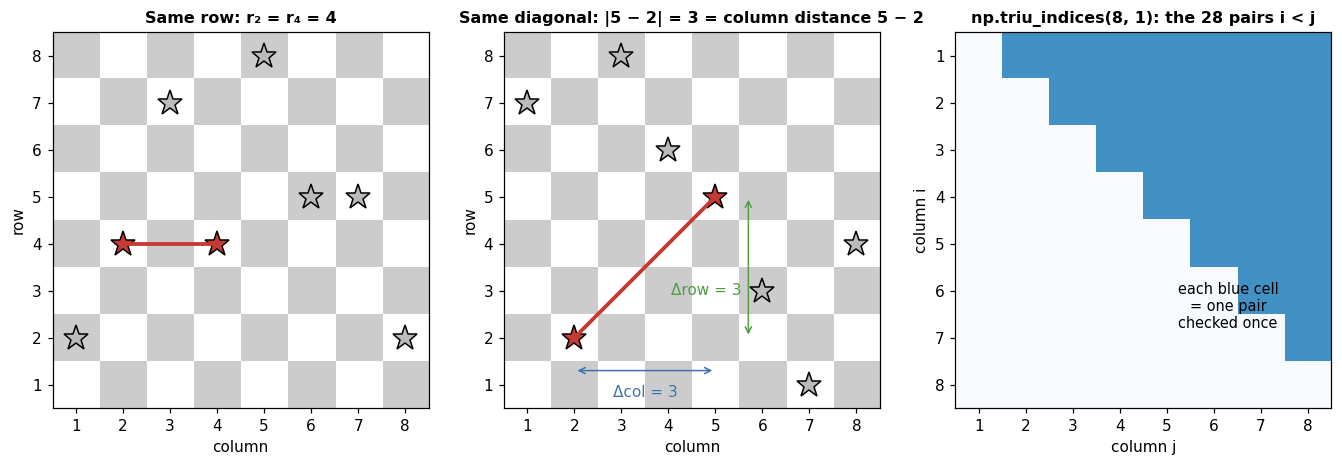

**Line by line.**
- `I8, J8 = np.triu_indices(8, 1)` — `triu_indices(n, k)` returns the (row, column) indices of the upper triangle of an n × n matrix, starting k places above the diagonal. With k = 1 these are exactly the 28 pairs (i, j) with i < j. We reuse them as *column pairs*.
- `D8 = J8 - I8` — column distance for each pair.
- `def queens(s):` — converts `"24748552"` into `array([2,4,7,4,8,5,5,2])`; anything that is already an array is passed through by `np.asarray`.
- `def to_str(state):` — the reverse: array → string (`map(str, …)` converts each number, `join` glues them).
- `def attacking_pairs(state):`
  - `P = np.atleast_2d(state)` — a single board of shape (8,) becomes (1, 8), so one code path handles one board or a population (N, 8).
  - `a, b = P[:, I8], P[:, J8]` — for every board, the rows of the first and second queen in each of the 28 pairs; both have shape (N, 28).
  - `h = ((a == b) | (np.abs(a - b) == D8)).sum(axis=1)` — same-row test OR same-diagonal test (`|` is element-wise OR on booleans), then count `True`s per board.
  - `return h if np.ndim(state) == 2 else int(h[0])` — an array for a population, a plain int for a single board.
- `def non_attacking_pairs(state): return 28 - attacking_pairs(state)` — the slides' fitness.
- `def draw_board(state, ax, title=""):`
  - `s = queens(state)` — accept a string or an array.
  - `ax.imshow(np.add.outer(np.arange(8), np.arange(8)) % 2, ...)` — `np.add.outer` builds the 8 × 8 table of row + column; `% 2` alternates 0/1, giving the checkerboard. `origin="lower"` puts row 1 at the bottom (as on the slides); `extent` aligns squares with coordinates 1–8.
  - `attacked = {k for i, j in zip(I8, J8) if s[i] == s[j] or abs(s[i] - s[j]) == j - i for k in (i, j)}` — a set comprehension: for every attacking pair, add both column indices. The result is the set of queens under attack.
  - `for c, r in enumerate(s): ax.plot(c + 1, r, marker="*", ..., color="red" if c in attacked else "limegreen")` — draw each queen at (column, row), red if attacked, green if safe.
  - Ticks, limits and title.
- `slide_population = [...]` — the four boards from the slides' GA figure.
- `fig, axes = plt.subplots(1, 4, figsize=(16, 4))` — four board panels.
- The loop prints h and fitness for each board and draws it.
- `plt.suptitle(..., y=1.03)` — a title above all panels; `y` lifts it slightly so it does not overlap.

**Reading the output.** The boards have $h$ = 4, 5, 8, 17, so fitness = 24, 23, 20, 11, exactly the numbers on the slide. This confirms the encoding and fitness match the lecture.

The computed fitness values **24, 23, 20, 11** match the slide exactly, confirming that we use the same encoding and fitness.

**Baseline on 8-queens: hill climbing.** A *successor* moves one queen to a different row within its column, so each state has $8 \times 7 = 56$ successors. We compare two versions:
- **Steepest-ascent hill climbing:** move to the best successor; stop when none is better.
- **Stochastic hill climbing:** move to a *randomly chosen* better successor. The slides describe SA as a variant of this algorithm.

In [ ]:
def queens_successors(s):
    # All 56 states that differ from s by moving one queen within its column.
    out = []
    for col in range(8):
        for row in range(1, 9):
            if row != s[col]:
                n = s.copy(); n[col] = row; out.append(n)
    return np.array(out)

def queens_random_successor(s, rng):
    # One successor chosen uniformly at random (used by SA).
    n = s.copy(); col = rng.integers(8)
    n[col] = rng.choice([r for r in range(1, 9) if r != s[col]])
    return n

def steepest_hill_climb_queens(s):
    while True:
        succ = queens_successors(s); h = attacking_pairs(succ)
        if h.min() >= attacking_pairs(s):
            return s
        s = succ[np.argmin(h)]

def stochastic_hill_climb_queens(s, rng):
    while True:
        succ = queens_successors(s); h = attacking_pairs(succ)
        better = succ[h < attacking_pairs(s)]
        if len(better) == 0:
            return s
        s = better[rng.integers(len(better))]

RUNS = 200
solved = {"steepest": 0, "stochastic": 0}
for seed in range(RUNS):
    rng = np.random.default_rng(seed)
    start = rng.integers(1, 9, 8)
    solved["steepest"] += attacking_pairs(steepest_hill_climb_queens(start)) == 0
    solved["stochastic"] += attacking_pairs(stochastic_hill_climb_queens(start, rng)) == 0
for k, v in solved.items():
    print(f"{k:>10s} hill climbing solved {v}/{RUNS} random boards ({v / RUNS:.0%}); the rest got stuck at a local optimum")

  steepest hill climbing solved 21/200 random boards (10%); the rest got stuck at a local optimum
stochastic hill climbing solved 22/200 random boards (11%); the rest got stuck at a local optimum


#### 🔍 Explanation of the cell above — successors and two hill climbers on 8-queens

**Concept.** For 8-queens, a natural move is: pick one column and move its queen to a different row. Each state therefore has $8 \times 7 = 56$ **successors**. Two hill-climbing variants are compared:
- **Steepest-ascent** hill climbing checks *all* 56 successors and moves to the best one. It stops when the best successor is not strictly better. It is deterministic: the same start always gives the same result.
- **Stochastic** hill climbing also checks all successors but moves to a *random* one among those that are strictly better. The slides describe SA as a variant of this.

Neither allows *sideways* moves (to an equally good state), so both stop on plateaus as well as at true local minima. That is a major reason they fail on 8-queens, whose landscape has many flat regions.

**Diagram.** A simplified picture of the 8-queens cost landscape. Steepest-ascent and stochastic hill climbing both require a *strictly* better successor, so they stop on plateaus and at local minima. These traps are common enough that only about 10% of random boards are solved.

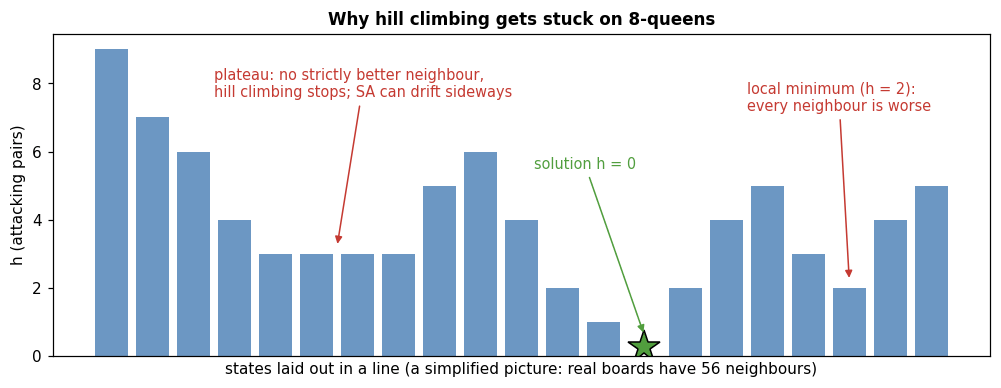

**Line by line.**
- `def queens_successors(s):` — two nested loops over columns and rows; `if row != s[col]` skips the queen's current row; `n = s.copy(); n[col] = row` creates the successor. It returns a (56, 8) array, so all successors can be scored in one vectorised call.
- `def queens_random_successor(s, rng):` — one random successor: `col = rng.integers(8)` picks a column, then `rng.choice([r for r in range(1, 9) if r != s[col]])` picks a new row different from the current one. SA uses this.
- `def steepest_hill_climb_queens(s):`
  - `while True:` — repeat until stuck.
  - `succ = queens_successors(s); h = attacking_pairs(succ)` — all 56 successors and their costs.
  - `if h.min() >= attacking_pairs(s): return s` — if even the best successor is not strictly better, stop.
  - `s = succ[np.argmin(h)]` — move to the best successor (`argmin` takes the first one if several tie).
- `def stochastic_hill_climb_queens(s, rng):`
  - `better = succ[h < attacking_pairs(s)]` — boolean indexing keeps only strictly better successors.
  - `if len(better) == 0: return s` — stuck.
  - `s = better[rng.integers(len(better))]` — move to a random improving successor.
- `RUNS = 200`; `solved = {"steepest": 0, "stochastic": 0}`.
- For each seed: `start = rng.integers(1, 9, 8)` — a random board with rows 1–8. Both climbers start from this same board.
- `solved["steepest"] += attacking_pairs(...) == 0` — the comparison is `True`/`False`, and adding a boolean to an int adds 1 or 0, so this counts successes.
- The final loop prints the counts and percentages.

**Reading the output.** Steepest ascent solves 21/200 boards (10%) and stochastic hill climbing 22/200 (11%). The other ~90% end at a local optimum or plateau with some queens still attacking. This is close to the ~14% Russell and Norvig report and is the baseline SA must beat.

Hill climbing gets stuck on most boards. Russell & Norvig report about 14% for steepest ascent, which is in the same range as our estimate. **This is the problem SA and GA are designed to address.**

---
## Part 3 — Simulated Annealing

### 3.1 What is annealing?  *(slide: "What Is Annealing?")*
**Annealing** is a heat-treatment process in metallurgy, used mostly to increase ductility and reduce the hardness of a material. A metal whose grain structure has been deformed (for example by pressure treatment) is heated, the grains **recrystallize and grow**, and it is then cooled **slowly**.

- At high temperature, atoms have enough energy to move around freely, even into temporarily *worse* (higher-energy) arrangements.
- As the metal cools slowly, the atoms settle into a **low-energy, well-ordered** structure.
- Cooling too fast (*quenching*) freezes defects in place, which corresponds to getting stuck in a local optimum.

| Physics | Optimization |
|---|---|
| Energy $E$ | Objective value (cost to minimize, or negative of value to maximize) |
| Arrangement of atoms | Candidate solution (state) |
| Temperature $T$ | How willing we are to accept a worse move |
| Slow cooling | Cooling schedule: $T$ decreases with time $t$ |

### 3.2 The core idea  *(slide: "Simulated Annealing" bullets)*
The slide summarises SA in four points:

1. **"Allow random moves (downhill) to jump out of local maxima; gradually reducing the frequency of such actions."** Hill climbing only ever moves uphill, so it stops at the first peak (Part 2). SA occasionally takes a *bad* move to escape.
2. **"A variant of stochastic hill climbing."** Stochastic hill climbing picks a random *better* successor. SA picks a random successor of *any* kind: it always takes it if it is better, and *sometimes* takes it if it is worse.
3. **"A mapping of temperature to time."** A schedule $T = \text{schedule}(t)$ starts high, so bad moves are frequently accepted, and decreases toward 0, so bad moves become rare.
4. **"Probability to move downhill: $e^{\Delta E/T}$."** In the slide's *maximization* view, $\Delta E = \text{VALUE}(next) - \text{VALUE}(current)$. For a bad (downhill) move $\Delta E < 0$, so $e^{\Delta E/T}$ is between 0 and 1.
   - The *bigger* the drop $|\Delta E|$, the *smaller* the probability.
   - The *higher* the temperature $T$, the *larger* the probability.

⚠️ **A note on sign conventions, because this confuses many students.** The same rule can be written in three equivalent ways. Only the bookkeeping differs:

| Where | Goal | $\Delta$ is defined as | A bad move has | Accept a bad move with probability |
|---|---|---|---|---|
| Slide 2 (bullets) | maximize VALUE | VALUE(next) − VALUE(current) | $\Delta E < 0$ | $e^{\Delta E/T}$ |
| Slide 3 (pseudocode, as written) | **minimize** VALUE (VALUE acts as energy/cost) | VALUE(current) − VALUE(next) | $\Delta E < 0$ | $e^{\Delta E/T}$ |
| This notebook's code (Parts 3.5, 3.7+) | minimize $f$ | $f(x') - f(x)$ | $\Delta > 0$ | $e^{-\Delta/T}$ |

In every row, the rule is the same: **always accept improvements, and accept a worsening of size $d > 0$ with probability $e^{-d/T}$.** The slide pseudocode's test "if $\Delta E > 0$ then accept" means VALUE(next) < VALUE(current), so as written it *minimizes* VALUE even though the bullets talk about maxima. For 8-queens we therefore use VALUE = number of attacking pairs $h$ with the pseudocode exactly as written.

**Theory (beyond the slides):** if $T$ is lowered slowly enough (logarithmically), SA finds a global optimum with probability approaching 1 (Geman & Geman, 1984; Hajek, 1988). That schedule is far too slow in practice, so exponential/geometric cooling is the usual choice.

### 3.3 The pseudocode from the slides, line by line
```
function SIMULATED-ANNEALING(problem, schedule) returns a solution state
    current ← problem.INITIAL
    for t = 1 to ∞ do
        T ← schedule(t)
        if T = 0 then return current
        next ← a randomly selected successor of current
        ΔE ← VALUE(current) − VALUE(next)
        if ΔE > 0 then current ← next
        else current ← next only with probability e^{ΔE/T}
```

| Line | Meaning |
|---|---|
| `current ← problem.INITIAL` | Start anywhere, often a random state |
| `for t = 1 to ∞` | Time step; there is no fixed iteration count, and the **schedule** decides when to stop |
| `T ← schedule(t)` | The temperature at time $t$ (temperature mapped to time) |
| `if T = 0 then return current` | Frozen: return the current state. The schedule must eventually reach exactly 0 |
| `next ← random successor` | Pick **one** random neighbour, not the best one (unlike steepest-ascent hill climbing) |
| `ΔE ← VALUE(current) − VALUE(next)` | Positive means next has a lower VALUE, i.e. it is better when minimizing |
| `if ΔE > 0 then current ← next` | Always accept an improvement |
| `else … with probability e^{ΔE/T}` | Accept a worse (or equal) move with probability $e^{\Delta E/T} \le 1$ |

Two practical remarks:
- The slide algorithm returns the **current** state, which may be slightly worse than the best state seen during the run. Practical implementations usually also track the **best-so-far**; our generic engine in Section 3.7 does.
- A common schedule, used in the textbook's companion code, is exponential: $T(t) = k\,e^{-\lambda t}$ for $t < \text{limit}$, and $0$ after that.

Below is a **line-for-line Python translation** of the slide.

In [ ]:
def exp_schedule(k=20.0, lam=0.005, limit=2000):
    # T(t) = k * exp(-lam * t) until `limit`, then exactly 0 (which stops SA).
    return lambda t: k * math.exp(-lam * t) if t < limit else 0

def simulated_annealing_slides(initial, value, random_successor, schedule, rng, trace=False):
    # Faithful translation of the slide pseudocode. VALUE is MINIMISED, as the pseudocode is written.
    current = initial
    log = []
    for t in itertools.count(1):                     # for t = 1 to infinity
        T = schedule(t)                              # T <- schedule(t)
        if T == 0:                                   # if T = 0 then return current
            return (current, np.array(log)) if trace else current
        nxt = random_successor(current, rng)         # next <- a randomly selected successor
        dE = value(current) - value(nxt)             # dE <- VALUE(current) - VALUE(next)
        if dE > 0:                                   # if dE > 0 then current <- next
            current = nxt
        elif rng.random() < math.exp(dE / T):        # else with probability e^(dE/T)
            current = nxt
        if trace:
            log.append((t, T, value(current)))

# Quick sanity check on the 1-D wavy function from Part 1, minimised from x = 7
x_final = simulated_annealing_slides(7.0, f_wavy, lambda x, rng: real_neighbour(x, 0.6, rng),
                                     exp_schedule(k=5, lam=0.003, limit=2000), np.random.default_rng(0))
print(f"slide-faithful SA on the wavy function: x = {x_final:.3f}, f = {f_wavy(x_final):.3f} "
      f"(global min f = {F_STAR:.3f} at x = {X_STAR:.3f})")

slide-faithful SA on the wavy function: x = -0.787, f = -1.938 (global min f = -1.940 at x = -0.766)


#### 🔍 Explanation of the cell above — the slide pseudocode of Simulated Annealing in Python

**Concept.** Simulated Annealing (SA) is stochastic hill climbing with one change: a **worse** move is not always rejected. It is accepted with probability $e^{\Delta E/T}$, where $\Delta E \le 0$ measures how much worse it is and $T$ is the current **temperature**. Two consequences:
- The worse the move (more negative $\Delta E$), the smaller the probability.
- The higher the temperature, the larger the probability.

The **schedule** maps time $t$ to temperature $T$. Starting hot lets the search wander between valleys (exploration). Cooling gradually makes it behave like hill climbing (exploitation). When the schedule returns exactly 0, the algorithm stops and returns the current state.

The common **exponential schedule** is $T(t) = k e^{-\lambda t}$: $k$ is the starting temperature and $\lambda$ the cooling rate. Since an exponential never reaches 0 on its own, a `limit` is added after which $T$ is set to exactly 0.

*Sign convention.* The slide pseudocode computes $\Delta E = \text{VALUE}(current) - \text{VALUE}(next)$ and accepts if $\Delta E > 0$. That means *next has a smaller VALUE*, so as written it **minimises** VALUE. A worse move has $\Delta E < 0$ and $e^{\Delta E/T} < 1$.

*Sideways moves.* If $\Delta E = 0$ (an equally good move), the `else` branch runs with probability $e^{0} = 1$, so equal moves are always accepted. This lets SA drift across flat plateaus, where hill climbing gets stuck.

**Diagram.** The slide pseudocode as a flowchart. Compared with hill climbing there is one extra branch: when the move is not an improvement, SA still accepts it if a uniform random number falls below $e^{\Delta E/T}$. The schedule decides when to stop (the first diamond).

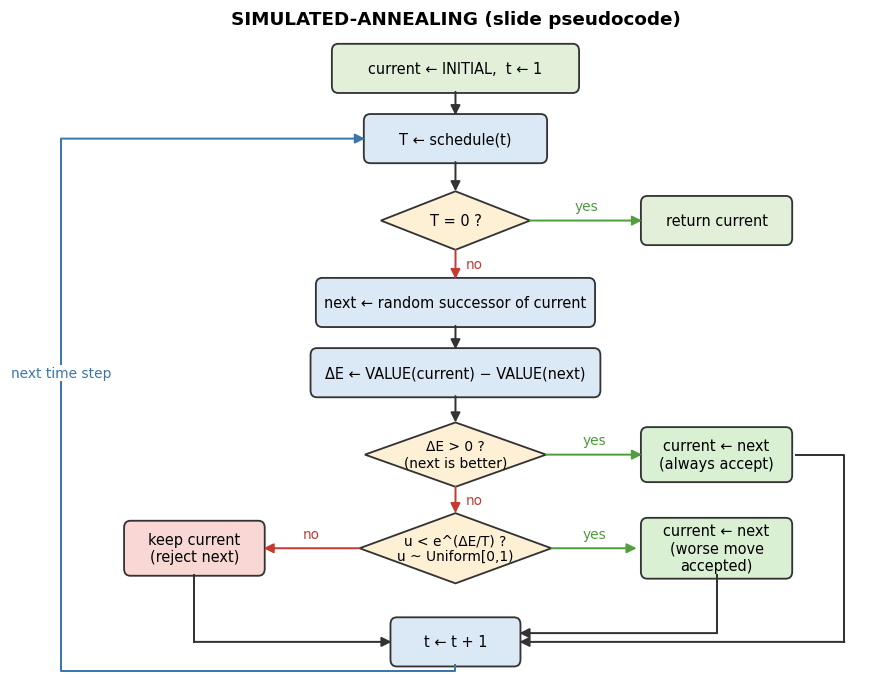

**Line by line.**
- `def exp_schedule(k=20.0, lam=0.005, limit=2000):` — a *factory*: it returns a function.
  - `return lambda t: k * math.exp(-lam * t) if t < limit else 0` — the returned function remembers `k`, `lam` and `limit` (a *closure*) and computes $T(t)$, or exactly 0 once $t \ge$ `limit`.
- `def simulated_annealing_slides(initial, value, random_successor, schedule, rng, trace=False):` — the problem-specific parts (VALUE, the successor function, the schedule) are passed in, so the same code works for any problem.
  - `current = initial` — `current ← problem.INITIAL`.
  - `log = []` — optional history.
  - `for t in itertools.count(1):` — `for t = 1 to ∞`; `count(1)` yields 1, 2, 3, … forever.
  - `T = schedule(t)` — `T ← schedule(t)`.
  - `if T == 0: return (current, np.array(log)) if trace else current` — `if T = 0 then return current`; also returns the log when tracing.
  - `nxt = random_successor(current, rng)` — `next ← a randomly selected successor of current`. (`next` is a Python built-in, hence the name `nxt`.)
  - `dE = value(current) - value(nxt)` — `ΔE ← VALUE(current) − VALUE(next)`.
  - `if dE > 0: current = nxt` — always accept an improvement.
  - `elif rng.random() < math.exp(dE / T): current = nxt` — otherwise accept with probability $e^{\Delta E/T}$, using the "uniform number below p" trick from Section 1.7.
  - `if trace: log.append((t, T, value(current)))` — record time, temperature and current value.
- Sanity check: minimise `f_wavy` from $x = 7$. `lambda x, rng: real_neighbour(x, 0.6, rng)` adapts the neighbour function to the `(state, rng)` signature that SA expects. The schedule is `k=5, lam=0.003, limit=2000`.

**Reading the output.** SA ends at $x = -0.787$, $f = -1.938$, essentially the global minimum, starting from a point three valleys away where hill climbing failed.

> ⚠️ *Note:* this faithful version calls `value(current)` again on every step instead of storing it, so it uses about two evaluations per step. That is harmless for 8-queens, but the generic engine in Section 3.7 stores the current value and is more efficient.

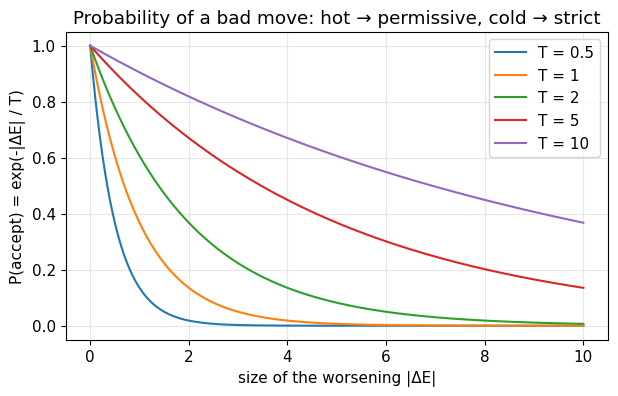

In [ ]:
# How temperature shapes acceptance of a worse move
deltas = np.linspace(0, 10, 200)
plt.figure(figsize=(7, 4))
for T in [0.5, 1, 2, 5, 10]:
    plt.plot(deltas, np.exp(-deltas / T), label=f"T = {T}")
plt.xlabel("size of the worsening |ΔE|")
plt.ylabel("P(accept) = exp(-|ΔE| / T)")
plt.title("Probability of a bad move: hot → permissive, cold → strict")
plt.legend(); plt.show()

#### 🔍 Explanation of the cell above — how temperature shapes the acceptance probability

**Concept.** The **Metropolis acceptance rule** accepts a move that is worse by $|\Delta E|$ with probability $P = e^{-|\Delta E|/T}$. Plotting $P$ against $|\Delta E|$ for several temperatures shows three things:
- At $|\Delta E| = 0$ every curve starts at 1: equal moves are always accepted.
- Every curve decreases: larger worsenings are less likely to be accepted.
- Higher $T$ gives flatter curves: a hot system tolerates large worsenings, a cold one almost none.

$T$ sets the *scale* of tolerated worsening: at $|\Delta E| = T$, the probability is always $e^{-1} \approx 0.37$. So $T$ must be chosen relative to typical $\Delta E$ values of the problem. This is why Section 3.7 calibrates $T_0$ from sampled moves rather than guessing.

**Diagram.** The annealing analogy. A hot system has enough energy to climb over the barriers between valleys; as it cools, the moves shrink to small adjustments inside one valley. Cooling slowly gives the system time to find a deep valley before it freezes.

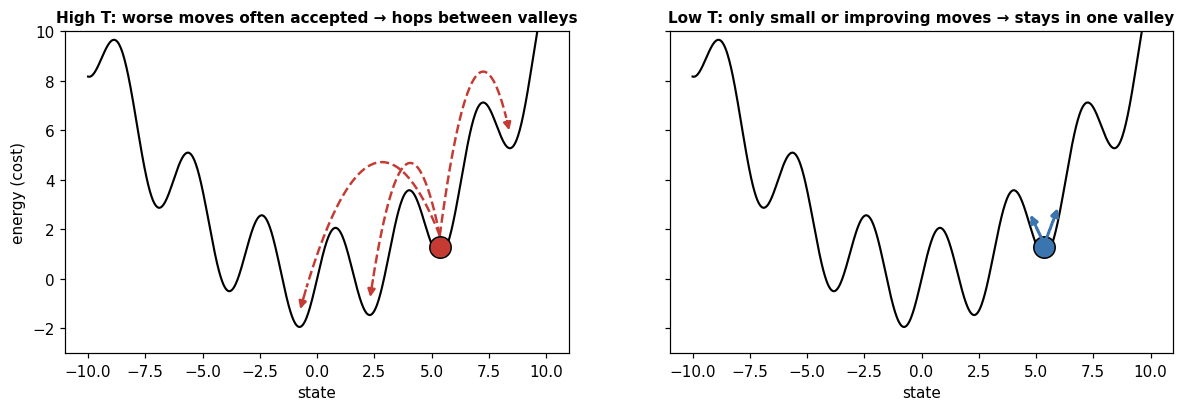

**Line by line.**
- `deltas = np.linspace(0, 10, 200)` — worsening sizes from 0 to 10.
- `plt.figure(figsize=(7, 4))`.
- `for T in [0.5, 1, 2, 5, 10]: plt.plot(deltas, np.exp(-deltas / T), label=f"T = {T}")` — one curve per temperature, using the vectorised `np.exp`.
- Axis labels, title, legend, show.

**Reading the output.** At $T = 10$ the curve is still above 0.35 at $|\Delta E| = 10$, so almost anything is accepted. At $T = 0.5$ it drops to near 0 by $|\Delta E| \approx 2$, so the search is almost greedy.

### 3.4 The acceptance probability with actual numbers  *(slide: $e^{\Delta E/T}$)*
Compute the probability of accepting a worse move for a few concrete cases. Here $\Delta$ is how much *worse* the new solution is, so in the slide's notation $\Delta E = -\Delta$ and the probability is $e^{\Delta E/T} = e^{-\Delta/T}$.

In [ ]:
print(f"{'':12s}" + "".join(f"{'T = ' + str(T):>12s}" for T in [10, 1, 0.1]))
for delta in [0.1, 1.0, 5.0]:
    row = "".join(f"{math.exp(-delta / T):12.4f}" for T in [10, 1, 0.1])
    print(f"Δ = {delta:<8}" + row)

                  T = 10       T = 1     T = 0.1
Δ = 0.1           0.9900      0.9048      0.3679
Δ = 1.0           0.9048      0.3679      0.0000
Δ = 5.0           0.6065      0.0067      0.0000


#### 🔍 Explanation of the cell above — acceptance probabilities as numbers

**Concept.** The same rule, $P = e^{-\Delta/T}$, evaluated at specific values to build intuition. Here $\Delta > 0$ means "how much worse"; in the slide's notation $\Delta E = -\Delta$.

**Line by line.**
- First `print` — header row; `f"{'T = ' + str(T):>12s}"` right-aligns each label in 12 characters, and `"".join(...)` glues the three column headers together.
- `for delta in [0.1, 1.0, 5.0]:` — three worsening sizes.
  - `row = "".join(f"{math.exp(-delta / T):12.4f}" for T in [10, 1, 0.1])` — the three probabilities, 4 decimals each.
  - `print(f"Δ = {delta:<8}" + row)` — `<8` left-aligns the row label.

**Reading the output.**
- Δ = 0.1: 0.990 (hot), 0.905, 0.368 (cold). Tiny worsenings are accepted often even when cold.
- Δ = 1.0: 0.905, 0.368, about 0.00005 (prints as 0.0000).
- Δ = 5.0: 0.607, 0.0067, about $10^{-22}$.

As $T$ falls, large worsenings are effectively forbidden first, while small ones remain possible longer. This is why late SA behaves like a slightly noisy hill climber.

**Read the table row by row:**
- A *slightly* worse move ($\Delta = 0.1$) is accepted 99% of the time when hot, and 37% of the time even when cold.
- A *much* worse move ($\Delta = 5$) is accepted 61% of the time when hot, and essentially never when cold ($e^{-50} \approx 10^{-22}$).

So temperature acts as a **tolerance for bad moves** that we gradually reduce.

### 3.5 SA by hand on the 1-D wavy function
Here is SA in its most minimal form, with no generality, so every line maps to the pseudocode. We start at $x_0 = 7$, in a poor valley near $x \approx 5.4$, and print the first steps so you can follow each decision.

Settings: $T_0 = 5$; each step multiplies $T$ by $\alpha = 0.997$ (*geometric cooling*); step size 0.6; 1,500 iterations.

In [27]:
def sa_1d(f, x0, T0=5.0, alpha=0.997, step=0.6, n_iters=1500, rng=None, verbose=0):
    rng = rng or np.random.default_rng()
    x, fx = x0, f(x0)
    best_x, best_f = x, fx
    T = T0
    trace = []
    if verbose:
        print(f"{'k':>3} {'T':>6} {'x':>7} {'f(x)':>7} | {'cand':>7} {'Δ':>7} {'P(acc)':>7} {'rand':>6}  decision")
    for k in range(n_iters):
        cand = real_neighbour(x, step, rng)           # 1. propose a neighbour
        delta = f(cand) - fx                          # 2. how much worse is it?
        p = 1.0 if delta <= 0 else math.exp(-delta / T)   # 3. Metropolis probability
        u = rng.random()
        accept = u < p                                # 4. accept with probability p
        if k < verbose:
            why = "better -> accept" if delta <= 0 else ("worse, but ACCEPT" if accept else "worse -> reject")
            print(f"{k:3d} {T:6.3f} {x:7.3f} {fx:7.3f} | {cand:7.3f} {delta:7.3f} {p:7.3f} {u:6.3f}  {why}")
        if accept:
            x, fx = cand, fx + delta
            if fx < best_f:                           # 5. remember the best ever seen
                best_x, best_f = x, fx
        trace.append((x, fx, T))
        T *= alpha                                    # 6. cool down
    return best_x, best_f, np.array(trace)

bx, bf, tr = sa_1d(f_wavy, 7.0, rng=np.random.default_rng(4), verbose=15)
print(f"\nSA result: x = {bx:.4f}, f = {bf:.4f}   (global: x = {X_STAR:.4f}, f = {F_STAR:.4f})")

  k      T       x    f(x) |    cand       Δ  P(acc)   rand  decision
  0  5.000   7.000   6.881 |   6.609  -1.301   1.000  0.511  better -> accept
  1  4.985   6.609   5.581 |   7.607   1.154   0.793  0.081  worse, but ACCEPT
  2  4.970   7.607   6.735 |   6.622  -1.094   1.000  0.376  better -> accept
  3  4.955   6.622   5.640 |   6.248  -1.876   1.000  0.175  better -> accept
  4  4.940   6.248   3.764 |   5.283  -2.792   1.000  0.544  better -> accept
  5  4.925   5.283   0.973 |   5.425  -0.009   1.000  0.477  better -> accept
  6  4.911   5.425   0.964 |   5.615   0.243   0.952  0.789  worse, but ACCEPT
  7  4.896   5.615   1.207 |   4.719   0.995   0.816  0.370  worse, but ACCEPT
  8  4.881   4.719   2.201 |   3.569   0.582   0.888  0.929  worse -> reject
  9  4.867   4.719   2.201 |   4.521   0.590   0.886  0.609  worse, but ACCEPT
 10  4.852   4.521   2.792 |   4.127   0.754   0.856  0.943  worse -> reject
 11  4.837   4.521   2.792 |   4.749  -0.682   1.000  0.133  better ->

#### 🔍 Explanation of the cell above — a minimal SA on the 1-D wavy function, with a decision trace

**Concept.** This is SA in its smallest form, written so that each step is visible. It differs from the slide version in two practical ways:
- **Geometric cooling**: $T_{k+1} = \alpha T_k$ with $\alpha$ slightly below 1 (here 0.997), so $T_k = T_0 \alpha^k$. Each step shrinks $T$ by the same *percentage*. After 1,500 steps, $T = 5 \times 0.997^{1500} \approx 5 \times 0.011 \approx 0.055$, so the run ends nearly frozen. The stopping rule is a fixed iteration budget rather than $T = 0$.
- **Best-so-far tracking**: the *current* state can get worse when bad moves are accepted, so we separately remember the best state ever visited and return that.

The *Metropolis criterion* is written in the minimisation form: $\Delta = f(\text{cand}) - f(x)$; if $\Delta \le 0$, accept; otherwise accept with probability $e^{-\Delta/T}$.

**Diagram.** How "accept with probability $p$" works, using two rows of the trace printed above. The unit interval is split at $p$; a uniform random number $u$ lands left of $p$ (accept) a fraction $p$ of the time. In row 1, $u = 0.081$ falls in the green part, so the worse move is accepted; in row 8, $u = 0.929$ falls in the red part, so it is rejected.

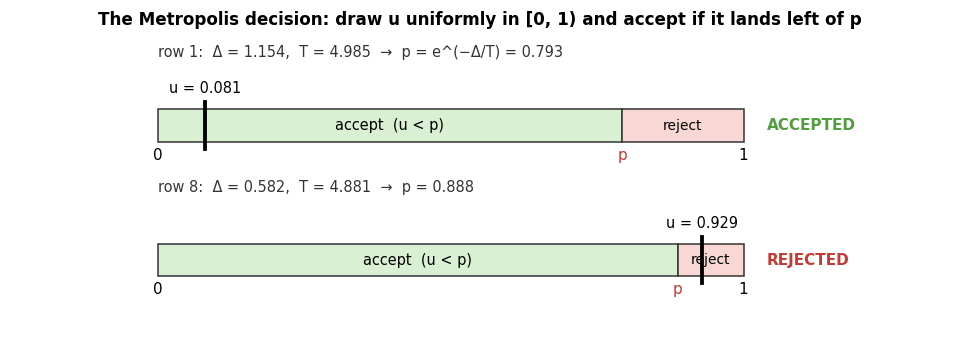

**Line by line.**
- `def sa_1d(f, x0, T0=5.0, alpha=0.997, step=0.6, n_iters=1500, rng=None, verbose=0):` — start temperature, cooling factor, neighbour size and budget are all parameters.
- `x, fx = x0, f(x0)`; `best_x, best_f = x, fx` — current and best start out equal.
- `T = T0`; `trace = []`.
- `if verbose: print(...)` — table header.
- `for k in range(n_iters):`
  - `cand = real_neighbour(x, step, rng)` — **(1)** propose a random neighbour.
  - `delta = f(cand) - fx` — **(2)** how much worse is it? (negative means better).
  - `p = 1.0 if delta <= 0 else math.exp(-delta / T)` — **(3)** Metropolis probability.
  - `u = rng.random()`; `accept = u < p` — **(4)** accept with probability p. The draw happens even when p = 1, so the printed table can show `u` on every row.
  - `if k < verbose:` — print the first `verbose` decisions with a reason string.
  - `if accept: x, fx = cand, fx + delta` — move. `fx + delta` equals `f(cand)`, so no extra evaluation is needed.
  - `if fx < best_f: best_x, best_f = x, fx` — **(5)** remember the best ever seen.
  - `trace.append((x, fx, T))` — record position, value and temperature.
  - `T *= alpha` — **(6)** cool down.
- `return best_x, best_f, np.array(trace)` — best solution and an (n_iters, 3) history.
- The call starts at $x_0 = 7$ with seed 4 and prints 15 rows.

**Reading the output (how to read a row).** Row 1: the candidate 7.607 is worse by Δ = 1.154; at T = 4.985 the probability is $e^{-1.154/4.985} = 0.793$; the random draw is 0.081 < 0.793, so the worse move is **accepted**. Row 8: p = 0.888 but u = 0.929 > p, so it is **rejected**. These accepted uphill moves let SA leave the starting valley. The final result is $x = -0.7667$, $f = -1.9398$, matching the global minimum to four decimals.

In the trace, look for rows marked **"worse, but ACCEPT"**. Those uphill moves are what let SA climb out of the starting valley. Hill climbing would reject every one of them.

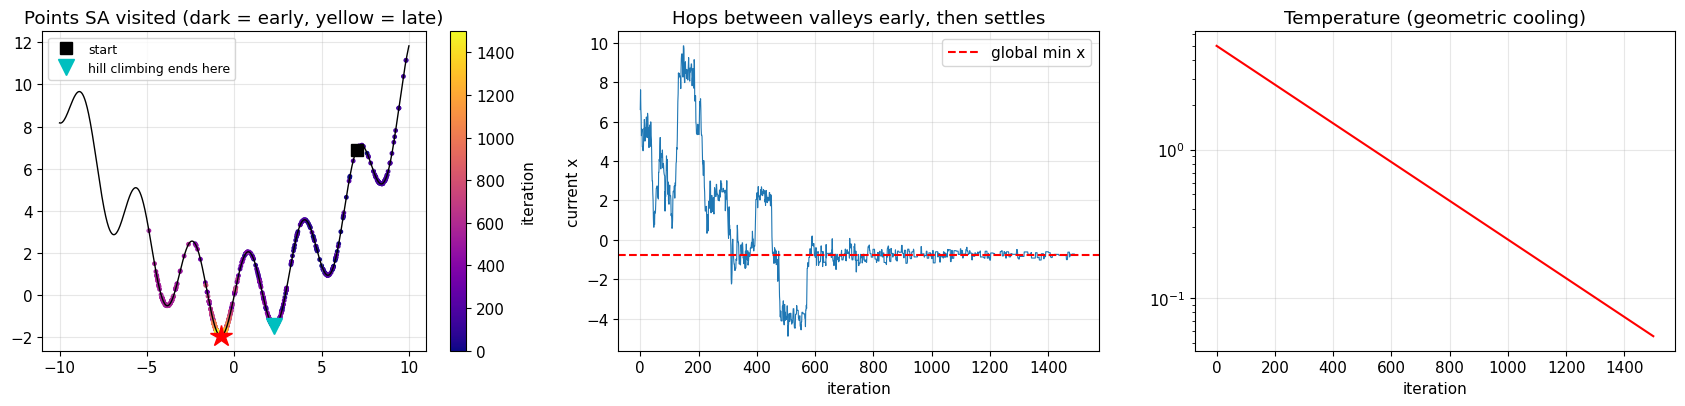

Reached the global valley from x0 = 7 (50 seeds):  SA 96%   hill climbing 0%


In [ ]:
hx, hf, htr = hill_climb_1d(f_wavy, 7.0, step=0.6, n_iters=1500, rng=np.random.default_rng(4))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
ax[0].plot(xx_plot, f_wavy(xx_plot), "k-", lw=1)
sc = ax[0].scatter(tr[:, 0], tr[:, 1], c=np.arange(len(tr)), cmap="plasma", s=6)
plt.colorbar(sc, ax=ax[0], label="iteration")
ax[0].plot(7.0, f_wavy(7.0), "ks", ms=9, label="start"); ax[0].plot(X_STAR, F_STAR, "r*", ms=16)
ax[0].plot(hx, hf, "cv", ms=12, label="hill climbing ends here"); ax[0].legend(fontsize=9)
ax[0].set_title("Points SA visited (dark = early, yellow = late)")

ax[1].plot(tr[:, 0], lw=0.8); ax[1].axhline(X_STAR, color="r", ls="--", label="global min x")
ax[1].set_xlabel("iteration"); ax[1].set_ylabel("current x"); ax[1].legend()
ax[1].set_title("Hops between valleys early, then settles")

ax[2].plot(tr[:, 2], "r"); ax[2].set_yscale("log")
ax[2].set_xlabel("iteration"); ax[2].set_title("Temperature (geometric cooling)")
plt.tight_layout(); plt.show()

# Is this luck? Repeat over 50 seeds with an identical start and step size.
sa_ok = [abs(sa_1d(f_wavy, 7.0, rng=np.random.default_rng(s))[0] - X_STAR) < 0.5 for s in range(50)]
hc_ok = [abs(hill_climb_1d(f_wavy, 7.0, step=0.6, n_iters=1500, rng=np.random.default_rng(s))[0] - X_STAR) < 0.5 for s in range(50)]
print(f"Reached the global valley from x0 = 7 (50 seeds):  SA {np.mean(sa_ok):.0%}   hill climbing {np.mean(hc_ok):.0%}")

#### 🔍 Explanation of the cell above — visualising the SA run and checking whether it was luck

**Concept.** One successful run proves little, because SA is random. This cell does two things. First, it *visualises* the run from the previous cell to show SA's typical behaviour: wide jumps between valleys while hot, then settling while cold. Second, it repeats SA and hill climbing over **50 seeds** with identical settings, turning an anecdote into a success rate.

**Line by line.**
- `hx, hf, htr = hill_climb_1d(f_wavy, 7.0, step=0.6, n_iters=1500, rng=np.random.default_rng(4))` — hill climbing with the *same* start, step size, budget and seed as SA, so only the acceptance rule differs.
- `fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))` — three panels.
- Panel 0 (where SA went):
  - `ax[0].plot(xx_plot, f_wavy(xx_plot), "k-", lw=1)` — the function.
  - `sc = ax[0].scatter(tr[:, 0], tr[:, 1], c=np.arange(len(tr)), cmap="plasma", s=6)` — every visited point (x = column 0, f = column 1), coloured by iteration number (`c=` sets colour values, `cmap` the palette); `s` is the dot size.
  - `plt.colorbar(sc, ax=ax[0], label="iteration")` — colour legend.
  - Markers for the start (black square), global minimum (red star) and hill climbing's end point (cyan triangle, `"cv"`).
- Panel 1 (x over time): `ax[1].plot(tr[:, 0], lw=0.8)` and a dashed red line at `X_STAR` via `axhline`.
- Panel 2 (temperature): `ax[2].plot(tr[:, 2], "r")` with `set_yscale("log")`. On a log scale geometric cooling is a straight line, because $\log T_k = \log T_0 + k \log\alpha$.
- `sa_ok = [abs(sa_1d(f_wavy, 7.0, rng=np.random.default_rng(s))[0] - X_STAR) < 0.5 for s in range(50)]` — 50 SA runs; `[0]` takes `best_x`; success means it ended within 0.5 of the global minimum.
- `hc_ok = [...]` — the same for hill climbing.
- `np.mean(sa_ok)` — the mean of booleans is the success rate.

**Reading the output.** In the plots, early points are spread over several valleys and late points cluster in the global valley; x jumps around early and then flattens; temperature falls in a straight line on the log scale. Over 50 seeds, SA reaches the global valley in 96% of runs and hill climbing in 0%, with identical starts and moves. The acceptance rule alone makes that difference.

**Experiment to try live:** set `T0=0.01` (nearly frozen from the start). SA then behaves exactly like hill climbing. Set `alpha=0.98` (cooling about 7× faster): SA freezes before it has time to explore, which is called *quenching*.

### 3.6 SA on the slides' running example: 8-queens
We now run the **slide-faithful** `simulated_annealing_slides` with:
- VALUE = number of attacking pairs $h$, minimized exactly as the pseudocode is written;
- *randomly selected successor* = move one random queen to a different random row;
- *schedule* = exponential cooling $T(t) = k\,e^{-\lambda t}$, then 0.

First, one traced run, so you can watch the temperature drop and $h$ settle at 0.

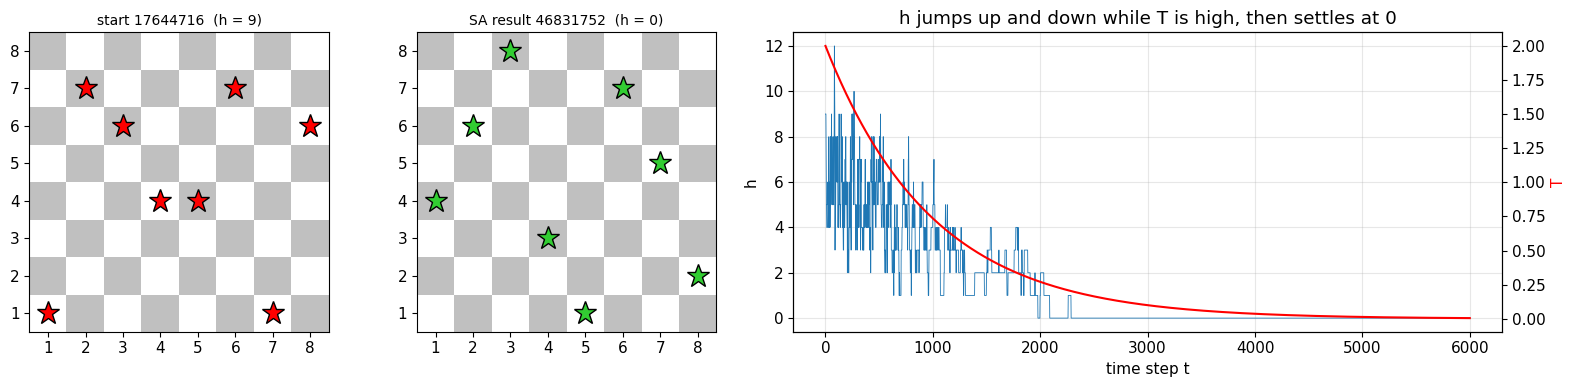

In [ ]:
rng = np.random.default_rng(SEED)
start = rng.integers(1, 9, 8)
final, log = simulated_annealing_slides(start, attacking_pairs, queens_random_successor,
                                        exp_schedule(k=2.0, lam=0.001, limit=6000), rng, trace=True)

fig = plt.figure(figsize=(16, 4))
ax1 = fig.add_subplot(1, 4, 1); draw_board(start, ax1, f"start {to_str(start)}  (h = {attacking_pairs(start)})")
ax2 = fig.add_subplot(1, 4, 2); draw_board(final, ax2, f"SA result {to_str(final)}  (h = {attacking_pairs(final)})")
ax3 = fig.add_subplot(1, 4, (3, 4))
ax3.plot(log[:, 0], log[:, 2], lw=0.6, label="h (attacking pairs) of current")
ax3.set_xlabel("time step t"); ax3.set_ylabel("h")
ax4 = ax3.twinx(); ax4.plot(log[:, 0], log[:, 1], "r-", label="temperature T"); ax4.set_ylabel("T", color="r"); ax4.grid(False)
ax3.set_title("h jumps up and down while T is high, then settles at 0")
plt.tight_layout(); plt.show()

#### 🔍 Explanation of the cell above — one traced SA run on 8-queens

**Concept.** The slide-faithful SA is now applied to the lecture's running example. VALUE is the number of attacking pairs $h$, minimised as the pseudocode is written. The successor moves one random queen to a different row. The schedule is $T(t) = 2e^{-0.001t}$ until $t = 6000$. Plotting $h$ and $T$ together shows SA's characteristic picture: $h$ fluctuates while $T$ is high (bad moves are accepted) and settles as $T$ drops. Plateaus are crossed by sideways moves, which are always accepted.

**Line by line.**
- `rng = np.random.default_rng(SEED)`.
- `start = rng.integers(1, 9, 8)` — a random board: 8 rows, each from 1 to 8.
- `final, log = simulated_annealing_slides(start, attacking_pairs, queens_random_successor, exp_schedule(k=2.0, lam=0.001, limit=6000), rng, trace=True)` — run with tracing; `log` has columns (t, T, h).
- `fig = plt.figure(figsize=(16, 4))`.
- `ax1 = fig.add_subplot(1, 4, 1); draw_board(start, ...)` — the starting board.
- `ax2 = fig.add_subplot(1, 4, 2); draw_board(final, ...)` — the final board.
- `ax3 = fig.add_subplot(1, 4, (3, 4))` — a tuple `(3, 4)` makes this axis span slots 3 *and* 4 of the 1 × 4 grid, giving a wide time plot.
- `ax3.plot(log[:, 0], log[:, 2], ...)` — h against time.
- `ax4 = ax3.twinx()` — a second y-axis sharing the same x-axis, with its scale on the right; used for $T$, which has different units.
- `ax4.plot(log[:, 0], log[:, 1], "r-")` — the temperature curve; `ax4.grid(False)` avoids drawing two overlapping grids.

**Reading the output.** The start board has several red (attacked) queens; the SA result is usually all green ($h = 0$). In the time plot, $h$ jumps between small values while $T$ is around 1–2, then locks at 0 as $T$ approaches 0.

**How often does it work, and how does that compare with hill climbing?** We use 50 random starting boards, the same for every method. We also try a **hotter, faster** schedule to show that the schedule matters.

Steepest hill climbing             solved  5/50  ( 10%)   [0.0s]
Stochastic hill climbing           solved  4/50  (  8%)   [0.0s]
SA, hot & fast (k=20, λ=0.005)     solved 38/50  ( 76%)   [5.1s]
SA, cool & slow (k=2, λ=0.001)     solved 49/50  ( 98%)   [14.0s]


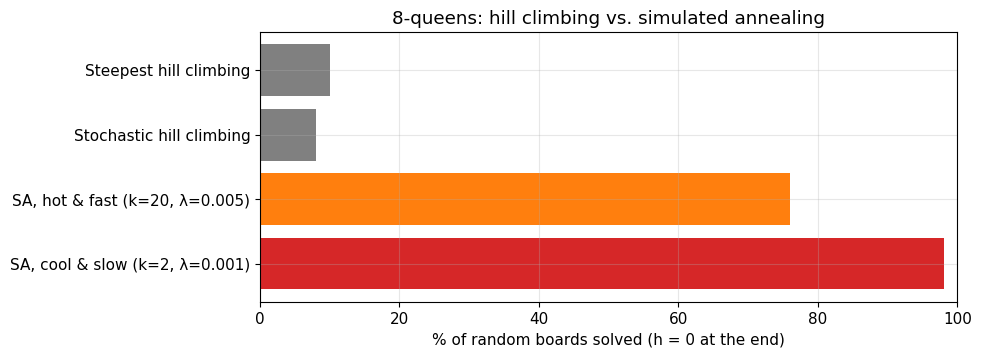

In [ ]:
RUNS = 50
methods = {
    "Steepest hill climbing":           lambda s, rng: steepest_hill_climb_queens(s),
    "Stochastic hill climbing":         stochastic_hill_climb_queens,
    "SA, hot & fast (k=20, λ=0.005)":   lambda s, rng: simulated_annealing_slides(
                                            s, attacking_pairs, queens_random_successor, exp_schedule(20, 0.005, 2000), rng),
    "SA, cool & slow (k=2, λ=0.001)":   lambda s, rng: simulated_annealing_slides(
                                            s, attacking_pairs, queens_random_successor, exp_schedule(2, 0.001, 6000), rng),
}
rates = {}
for name, fn in methods.items():
    t = time.perf_counter()
    ok = sum(attacking_pairs(fn(np.random.default_rng(s).integers(1, 9, 8), np.random.default_rng(1000 + s))) == 0
             for s in range(RUNS))
    rates[name] = ok / RUNS
    print(f"{name:34s} solved {ok:2d}/{RUNS}  ({ok / RUNS:4.0%})   [{time.perf_counter() - t:.1f}s]")

plt.figure(figsize=(9, 3.5))
plt.barh(list(rates.keys()), [100 * v for v in rates.values()], color=["gray", "gray", "tab:orange", "tab:red"])
plt.xlabel("% of random boards solved (h = 0 at the end)"); plt.xlim(0, 100); plt.gca().invert_yaxis()
plt.title("8-queens: hill climbing vs. simulated annealing"); plt.show()

#### 🔍 Explanation of the cell above — success rates: hill climbing vs. two SA schedules

**Concept.** A fair comparison of stochastic methods needs (i) **the same test cases** for every method and (ii) **many repetitions**. Here all four methods face the same 50 random boards. Two SA schedules are compared to show that the **schedule is a design choice that matters**:
- *Hot and fast* ($k = 20$, $\lambda = 0.005$, 2,000 steps): the starting temperature is far above typical $\Delta E$ values on 8-queens (a few units), so the first several hundred steps are essentially a random walk, and only a short cold phase remains for settling.
- *Cool and slow* ($k = 2$, $\lambda = 0.001$, 6,000 steps): moderate from the start, with a long, gradual cool-down.

**Line by line.**
- `RUNS = 50`.
- `methods = {...}` — a dictionary from name to a function with the common signature `(start_board, rng)`.
  - Steepest ascent is deterministic, so its lambda ignores `rng`.
  - `stochastic_hill_climb_queens` already has the right signature and is stored directly.
  - The two SA entries are lambdas that call `simulated_annealing_slides` with their own schedule.
- `rates = {}` — success rate per method.
- `for name, fn in methods.items():`
  - `t = time.perf_counter()` — start the timer.
  - `ok = sum(attacking_pairs(fn(np.random.default_rng(s).integers(1, 9, 8), np.random.default_rng(1000 + s))) == 0 for s in range(RUNS))` — for each seed `s`: build the starting board from seed `s` (identical for all methods), give the method its own generator seeded `1000 + s`, run it, and count it as solved if $h = 0$.
  - `rates[name] = ok / RUNS` and print the count, percentage and elapsed time.
- `plt.barh(...)` — horizontal bar chart of success percentages; the two SA bars are coloured differently. `invert_yaxis()` lists the first method at the top.

**Reading the output.** Steepest 10%, stochastic 8%, SA hot and fast 76%, SA cool and slow 98% (49/50). SA is far stronger than either hill climber, and the cool and slow schedule beats the hot and fast one. The cost is time: 14 s versus 5 s, since it runs 6,000 steps instead of 2,000.

**What to take away:**
- Both hill climbers usually stop at a local optimum. SA, which is "stochastic hill climbing that sometimes accepts bad moves", solves most or all boards.
- The **schedule matters.** With $k = 20$, the first steps accept almost any move, and with only 2,000 steps there is less time to settle. Starting cooler and cooling more slowly works better here. Choosing the starting temperature systematically is shown in Section 3.7 (`estimate_T0`).
- Because the slide's version returns `current` rather than the best state seen, a run can in principle visit a solution and then wander off it while $T$ is still above 0. Tracking the best-so-far, or stopping as soon as $h = 0$, removes that risk.

Next we generalise this into a reusable engine with an iteration budget and best-so-far tracking, and apply it to other problems.

### 3.7 A generic SA implementation
The SA engine is **problem-agnostic**: it needs only `f` (objective), `neighbour` (move operator), and `schedule` (temperature at step `k`). The same function will later solve the TSP.

We define two continuous neighbourhoods. `gaussian_neighbour` moves all coordinates at once, and `coordinate_neighbour` moves a single coordinate. The choice turns out to matter enormously, as Part 5 will show.

Two practical details that matter a lot:
- **Initial temperature $T_0$:** choose it so that roughly 80% of uphill moves are accepted at the start. If $\bar\Delta^+$ is the mean uphill delta, then $T_0 = -\bar\Delta^+ / \ln(0.8)$.
- **Final temperature:** low enough that uphill moves are essentially never accepted.

In [ ]:
# ---------- cooling schedules (each returns a function T(k)) ----------
def geometric_schedule(T0, n_iters, T_end_ratio=1e-4):
    alpha = T_end_ratio ** (1.0 / n_iters)     # chosen so T(n_iters) = T0 * T_end_ratio
    return lambda k: T0 * alpha**k

def linear_schedule(T0, n_iters, T_end_ratio=1e-4):
    T_end = T0 * T_end_ratio
    return lambda k: T0 - (T0 - T_end) * k / n_iters

def logarithmic_schedule(T0):
    return lambda k: T0 / math.log(k + 2)

# ---------- neighbours for continuous problems ----------
def gaussian_neighbour(sigma, bounds=BOUNDS):
    # Perturb ALL coordinates at once (isotropic move).
    lo, hi = bounds
    return lambda x, rng: np.clip(x + rng.normal(0, sigma, size=x.shape), lo, hi)

def coordinate_neighbour(sigma, bounds=BOUNDS):
    # Perturb ONE randomly chosen coordinate (axis-aligned move).
    lo, hi = bounds
    def move(x, rng):
        y = x.copy()
        i = rng.integers(len(x))
        y[i] = np.clip(y[i] + rng.normal(0, sigma), lo, hi)
        return y
    return move

# ---------- T0 calibration ----------
def estimate_T0(f, x0, neighbour, rng, n_samples=300, target_accept=0.8):
    # Pick T0 so a typical uphill move is accepted with probability target_accept.
    fx = f(x0)
    ups = [d for d in (f(neighbour(x0, rng)) - fx for _ in range(n_samples)) if d > 0]
    return -np.mean(ups) / math.log(target_accept) if ups else 1.0

# ---------- the SA engine ----------
def simulated_annealing(f, x0, neighbour, schedule, n_iters=5000, rng=None, record_path=False):
    rng = rng or np.random.default_rng()
    x, fx = np.array(x0), f(x0)
    best_x, best_f = x.copy(), fx
    log = {"current": np.empty(n_iters), "best": np.empty(n_iters),
           "T": np.empty(n_iters), "accepted": np.zeros(n_iters, bool)}
    path = [x.copy()] if record_path else None

    for k in range(n_iters):
        T = schedule(k)
        cand = neighbour(x, rng)
        fc = f(cand)
        delta = fc - fx
        # Metropolis criterion
        if delta <= 0 or rng.random() < math.exp(-delta / max(T, 1e-300)):
            x, fx = cand, fc
            log["accepted"][k] = True
            if fx < best_f:
                best_x, best_f = x.copy(), fx
        log["current"][k], log["best"][k], log["T"][k] = fx, best_f, T
        if record_path:
            path.append(x.copy())

    if record_path:
        log["path"] = np.array(path)
    return best_x, best_f, log

#### 🔍 Explanation of the cell above — the generic SA toolkit (schedules, neighbours, T₀ calibration, engine)

**Concept.** This cell turns SA into a **reusable, problem-agnostic engine**. SA needs only three problem-specific ingredients: an objective `f`, a move `neighbour`, and a `schedule`. Everything else is generic. Four building blocks are defined.

*1. Cooling schedules* (each a function of iteration $k$):
- **Geometric** $T_k = T_0 \alpha^k$. Here $\alpha$ is computed from the budget so that $T$ reaches $T_0 \times 10^{-4}$ exactly at the end: $\alpha = (10^{-4})^{1/n}$. The same function therefore cools faster for short runs and slower for long ones.
- **Linear** $T_k = T_0 - (T_0 - T_{end})\,k/n$: a straight line down to the same end temperature.
- **Logarithmic** $T_k = T_0/\ln(k+2)$: the theoretically convergent schedule (Hajek, 1988), but it cools extremely slowly.

*2. Continuous neighbours:*
- **Gaussian (full-vector)**: add noise to *all* coordinates at once.
- **Coordinate**: add noise to *one* random coordinate. This turns out to matter enormously on separable functions (Part 5).

*3. Calibrating $T_0$.* A good starting temperature accepts most, but not all, uphill moves (about 80% is a common rule). Setting $e^{-\bar\Delta^+/T_0} = 0.8$ and solving gives $T_0 = -\bar\Delta^+/\ln 0.8 \approx 4.48\,\bar\Delta^+$, where $\bar\Delta^+$ is the average uphill move size estimated by sampling. The same code then adapts automatically to any problem's scale: tour lengths in hundreds, Rastrigin values in tens, and so on.

*4. The engine.* The generic version of the algorithm, with a fixed iteration budget, best-so-far tracking, and logging of current value, best value, temperature and acceptance.

**Diagram.** Left: the three cooling schedules in this cell. Geometric cooling is a straight line on a log axis and spends its budget across exploring, settling and refining; logarithmic cooling stays hot almost to the end. Right: `estimate_T0` samples uphill moves (illustrative distribution), takes their mean, and chooses $T_0$ so that a move of that average size is accepted with probability 0.8.

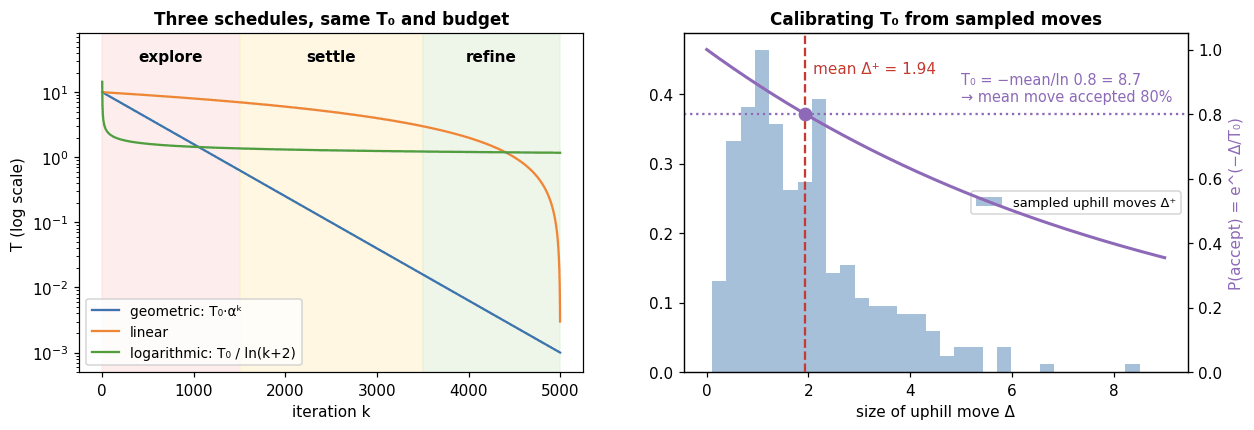

**Line by line — schedules.**
- `def geometric_schedule(T0, n_iters, T_end_ratio=1e-4):`
  - `alpha = T_end_ratio ** (1.0 / n_iters)` — chosen so $\alpha^{n} = 10^{-4}$.
  - `return lambda k: T0 * alpha**k` — the schedule as a closure.
- `def linear_schedule(...)`: `T_end = T0 * T_end_ratio`; `return lambda k: T0 - (T0 - T_end) * k / n_iters`.
- `def logarithmic_schedule(T0): return lambda k: T0 / math.log(k + 2)` — the `+ 2` avoids $\ln 1 = 0$ (division by zero) at $k = 0$.

**Line by line — neighbours.**
- `def gaussian_neighbour(sigma, bounds=BOUNDS):` — `lo, hi = bounds`; returns `lambda x, rng: np.clip(x + rng.normal(0, sigma, size=x.shape), lo, hi)`, i.e. noise on every coordinate, then clipping. This is a factory: `sigma` and the bounds are fixed now, and the engine later calls `neighbour(x, rng)`.
- `def coordinate_neighbour(sigma, bounds=BOUNDS):`
  - inner `def move(x, rng):` — `y = x.copy()` (never modify the current solution in place); `i = rng.integers(len(x))` picks a coordinate; `y[i] = np.clip(y[i] + rng.normal(0, sigma), lo, hi)` perturbs and clips that coordinate only.
  - `return move`.

**Line by line — `estimate_T0`.**
- `fx = f(x0)` — value at the start.
- `ups = [d for d in (f(neighbour(x0, rng)) - fx for _ in range(n_samples)) if d > 0]` — sample 300 neighbours of `x0`, compute each $\Delta$, and keep only the uphill ones ($d > 0$). (The inner parentheses are a generator expression that yields the deltas; the outer list comprehension filters them.)
- `return -np.mean(ups) / math.log(target_accept) if ups else 1.0` — the formula above; since $\ln 0.8 < 0$, the minus sign makes $T_0$ positive. Falls back to 1.0 if no uphill move was found.

**Line by line — `simulated_annealing` (the engine).**
- `rng = rng or np.random.default_rng()`.
- `x, fx = np.array(x0), f(x0)` — `np.array` makes a copy, so the caller's `x0` is never changed.
- `best_x, best_f = x.copy(), fx`.
- `log = {...}` — arrays pre-allocated with `np.empty`/`np.zeros` (faster than appending to lists); `"accepted"` is a boolean array.
- `path = [x.copy()] if record_path else None` — optional trajectory, used for plotting.
- `for k in range(n_iters):`
  - `T = schedule(k)` — current temperature.
  - `cand = neighbour(x, rng)`; `fc = f(cand)`; `delta = fc - fx`.
  - `if delta <= 0 or rng.random() < math.exp(-delta / max(T, 1e-300)):` — the Metropolis criterion. Because Python's `or` *short-circuits*, a random number is drawn only for worse moves. `max(T, 1e-300)` guards against division by zero if a schedule ever returns 0.
    - `x, fx = cand, fc`; `log["accepted"][k] = True`.
    - `if fx < best_f: best_x, best_f = x.copy(), fx` — best-so-far. The `.copy()` is essential for array states: otherwise `best_x` could refer to the same array object as `x` and change along with it.
  - `log["current"][k], log["best"][k], log["T"][k] = fx, best_f, T` — record this iteration.
  - `if record_path: path.append(x.copy())`.
- `if record_path: log["path"] = np.array(path)`.
- `return best_x, best_f, log` — note that the *best*, not the final, state is returned.

There is no output; this cell only defines functions used in the following cells and in Part 5.

### 3.9 SA vs. hill climbing on 2-D Rastrigin
Both methods start from the same point, $(4, 4)$, which sits deep in a local basin with $f=32$, and both use the **same move size** (σ = 0.2). The only difference is the acceptance rule.

Calibrated T0 = 47.70
Hill climbing : x = [3.981 3.977], f = 31.8400
Sim. annealing: x = [-0.975  0.066], f = 1.9329


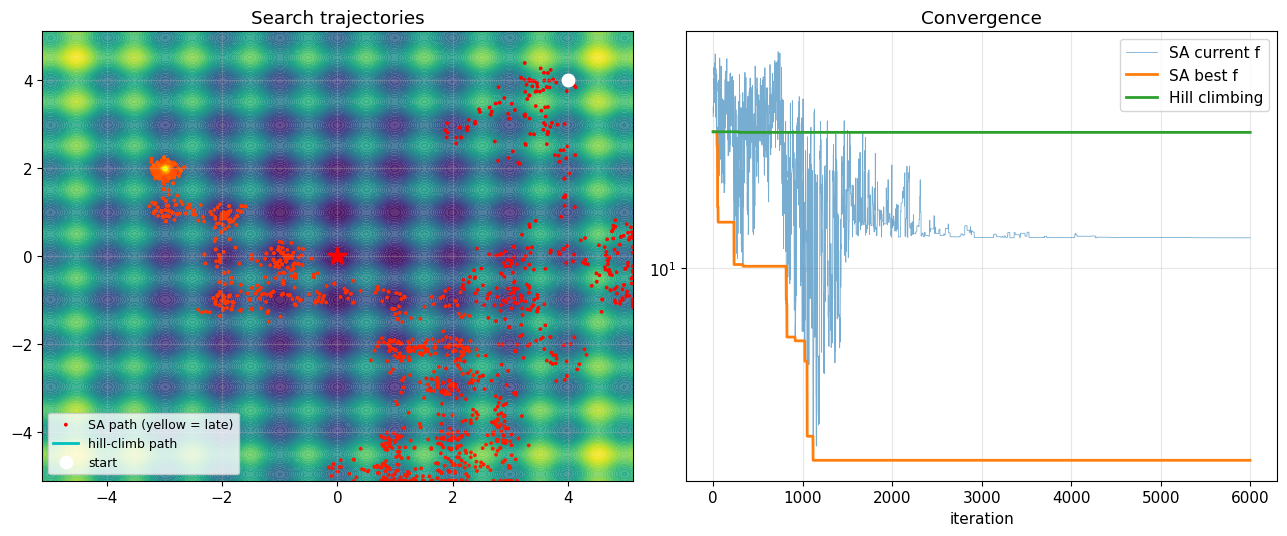

In [ ]:
x0 = np.array([4.0, 4.0]); N = 6000
neigh = gaussian_neighbour(sigma=0.2)   # identical move size for both methods

rng = np.random.default_rng(SEED)
T0 = estimate_T0(rastrigin, x0, neigh, rng)
print(f"Calibrated T0 = {T0:.2f}")

sa_x, sa_f, sa_log = simulated_annealing(rastrigin, x0, neigh, geometric_schedule(T0, N),
                                         n_iters=N, rng=rng, record_path=True)
hc_x, hc_f, hc_path, hc_hist = hill_climb(rastrigin, x0, step=0.2, n_iters=N, rng=rng)
print(f"Hill climbing : x = {np.round(hc_x, 3)}, f = {hc_f:.4f}")
print(f"Sim. annealing: x = {np.round(sa_x, 3)}, f = {sa_f:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
ax[0].contourf(X, Y, Z, levels=40, cmap="viridis", alpha=0.85)
p = sa_log["path"]
ax[0].scatter(p[:, 0], p[:, 1], c=np.arange(len(p)), cmap="autumn", s=3, label="SA path (yellow = late)")
ax[0].plot(hc_path[:, 0], hc_path[:, 1], "c-", lw=2, label="hill-climb path")
ax[0].plot(*x0, "wo", ms=9, label="start"); ax[0].plot(0, 0, "r*", ms=15)
ax[0].legend(loc="lower left", fontsize=9); ax[0].set_title("Search trajectories")

ax[1].plot(sa_log["current"], lw=0.6, alpha=0.6, label="SA current f")
ax[1].plot(sa_log["best"], lw=2, label="SA best f")
ax[1].plot(hc_hist, lw=2, label="Hill climbing")
ax[1].set_yscale("symlog", linthresh=1e-2); ax[1].set_xlabel("iteration")
ax[1].set_title("Convergence"); ax[1].legend()
plt.tight_layout(); plt.show()

#### 🔍 Explanation of the cell above — SA vs. hill climbing on 2-D Rastrigin from the same start

**Concept.** A controlled experiment: both methods start at (4, 4), a local minimum region with $f = 32$, and use **exactly the same move** (Gaussian, σ = 0.2) and **the same budget** (6,000 iterations). The *only* difference is the acceptance rule: greedy versus Metropolis. Any difference in outcome is therefore caused by accepting worse moves.

**Line by line.**
- `x0 = np.array([4.0, 4.0]); N = 6000`.
- `neigh = gaussian_neighbour(sigma=0.2)` — the shared move.
- `rng = np.random.default_rng(SEED)`.
- `T0 = estimate_T0(rastrigin, x0, neigh, rng)` — calibrated starting temperature (47.7 here).
- `sa_x, sa_f, sa_log = simulated_annealing(rastrigin, x0, neigh, geometric_schedule(T0, N), n_iters=N, rng=rng, record_path=True)` — SA, recording the path.
- `hc_x, hc_f, hc_path, hc_hist = hill_climb(rastrigin, x0, step=0.2, n_iters=N, rng=rng)` — hill climbing with the same step.
- Two prints compare the end points.
- Left panel: contour background; `p = sa_log["path"]`; `ax[0].scatter(p[:, 0], p[:, 1], c=np.arange(len(p)), cmap="autumn", s=3)` draws SA's path coloured red (early) to yellow (late); `ax[0].plot(hc_path[:, 0], hc_path[:, 1], "c-", lw=2)` draws hill climbing's path in cyan; the start and global minimum are marked.
- Right panel: SA current f (noisy), SA best f, and the hill-climbing history.
- `ax[1].set_yscale("symlog", linthresh=1e-2)` — a *symmetric log* scale: logarithmic for values above 0.01 and linear below, so values near 0 can still be shown (an ordinary log scale cannot display 0).

**Reading the output.** Hill climbing ends at (3.98, 3.98) with $f = 31.84$: it never left the starting basin. SA ends at (−0.975, 0.066) with $f = 1.93$, having crossed most of the domain. Note that SA did **not** reach exactly $f = 0$; it settled in a basin next to the global one. SA greatly improves the odds but does not guarantee the global optimum in a single run.

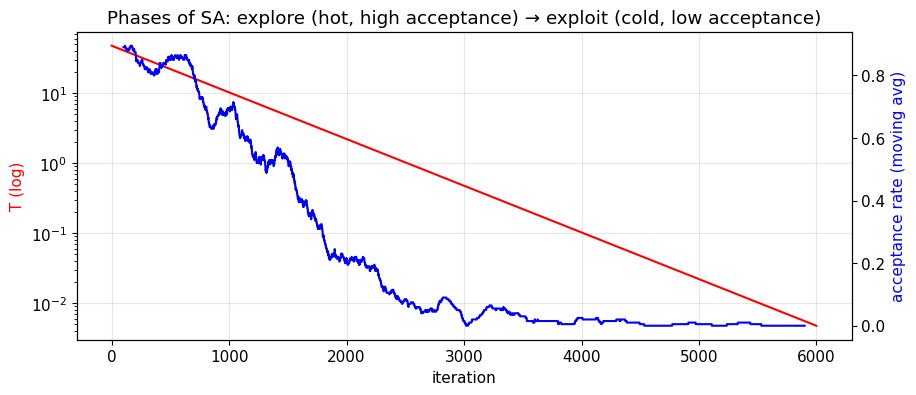

In [ ]:
# Look inside SA: temperature vs. acceptance rate
window = 200
acc_rate = np.convolve(sa_log["accepted"], np.ones(window) / window, mode="valid")

fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.plot(sa_log["T"], "r-", label="Temperature T")
ax1.set_yscale("log"); ax1.set_ylabel("T (log)", color="r"); ax1.set_xlabel("iteration")
ax2 = ax1.twinx()
ax2.plot(np.arange(len(acc_rate)) + window // 2, acc_rate, "b-", label="acceptance rate")
ax2.set_ylabel("acceptance rate (moving avg)", color="b"); ax2.grid(False)
plt.title("Phases of SA: explore (hot, high acceptance) → exploit (cold, low acceptance)")
plt.show()

#### 🔍 Explanation of the cell above — temperature vs. acceptance rate

**Concept.** The **acceptance rate** (fraction of proposed moves accepted) is the best diagnostic for an SA run. Plotted against temperature, it reveals the phases:
1. **Hot** — high acceptance (above about 50%): the search is close to a random walk (exploration).
2. **Cooling** — acceptance falls as large worsenings get rejected: the search commits to a region.
3. **Cold** — low acceptance: mostly improvements are accepted (exploitation).

If acceptance is already low at the start, $T_0$ is too small (the run "quenches"). If it is still high at the end, the schedule never cooled enough.

**Line by line.**
- `window = 200`.
- `acc_rate = np.convolve(sa_log["accepted"], np.ones(window) / window, mode="valid")` — a **moving average**: convolving with a box of 200 values, each 1/200, averages each stretch of 200 consecutive accept flags (True = 1). `mode="valid"` keeps only positions where the box fits entirely inside the data, so the result is `window − 1` shorter.
- `fig, ax1 = plt.subplots(figsize=(10, 4))`.
- `ax1.plot(sa_log["T"], "r-")`; `ax1.set_yscale("log")` — temperature on a log scale (a straight line for geometric cooling).
- `ax2 = ax1.twinx()` — a second y-axis for the acceptance rate.
- `ax2.plot(np.arange(len(acc_rate)) + window // 2, acc_rate, "b-")` — shift by half a window so each average is plotted at the centre of the iterations it covers.
- `ax2.grid(False)` — avoid a second overlapping grid.

**Reading the output.** The acceptance rate starts high, falls steadily as $T$ drops, and ends near zero. The two curves move together, which shows that temperature directly controls exploration.

**Discussion points:**
- Early on, SA wanders across many basins: the "current f" curve is noisy and frequently goes *up*.
- As $T$ drops, the acceptance rate falls and SA settles into one basin, then refines within it.
- Always track **best-so-far** separately; the *current* state is allowed to get worse.
- Hill climbing never leaves the starting basin. SA travels most of the way to the global optimum, but a single run does not guarantee reaching $f=0$ exactly; it may settle in a neighbouring basin.
- Results vary from run to run. Change `SEED` and rerun, which leads directly into the next experiment.

### 3.10 Effect of the cooling schedule
Besides the neighbourhood, the schedule is the most important SA design choice. We compare three schedules on **5-D Rastrigin** using 15 independent seeds each, with an identical budget, starting temperature, and neighbourhood (single-coordinate moves).

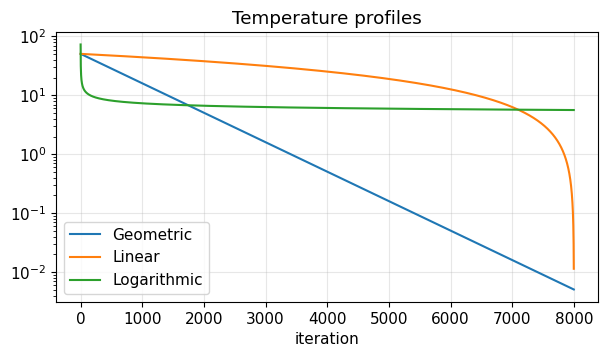

Geometric   : mean best f =  0.013 ± 0.010   (min 0.004)
Linear      : mean best f =  3.656 ± 2.405   (min 1.102)
Logarithmic : mean best f =  4.461 ± 1.128   (min 1.974)


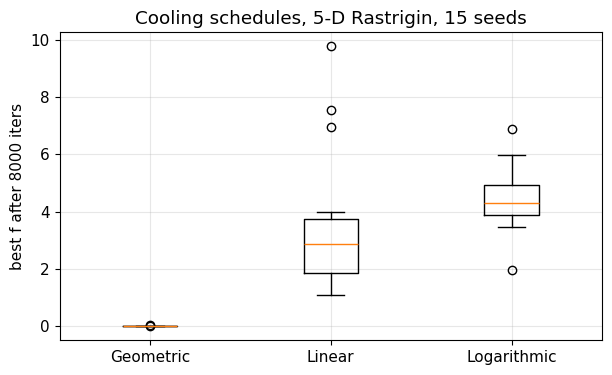

In [ ]:
D, N, RUNS = 5, 8000, 15
neigh = coordinate_neighbour(sigma=0.5)
T0 = estimate_T0(rastrigin, np.full(D, 3.0), neigh, np.random.default_rng(0))
schedules = {
    "Geometric":   geometric_schedule(T0, N),
    "Linear":      linear_schedule(T0, N),
    "Logarithmic": logarithmic_schedule(T0),
}

plt.figure(figsize=(7, 3.5))
ks = np.arange(N)
for name, s in schedules.items():
    plt.plot(ks, [s(k) for k in ks], label=name)
plt.yscale("log"); plt.title("Temperature profiles"); plt.xlabel("iteration"); plt.legend(); plt.show()

results = {}
for name, s in schedules.items():
    finals = []
    for r in range(RUNS):
        rng = np.random.default_rng(1000 + r)
        _, fb, _ = simulated_annealing(rastrigin, rng.uniform(*BOUNDS, D), neigh, s, N, rng)
        finals.append(fb)
    results[name] = np.array(finals)
    print(f"{name:12s}: mean best f = {results[name].mean():6.3f} ± {results[name].std():5.3f}   "
          f"(min {results[name].min():.3f})")

plt.figure(figsize=(7, 4))
plt.boxplot(list(results.values())); plt.xticks(range(1, len(results) + 1), list(results.keys()))
plt.ylabel("best f after %d iters" % N); plt.title(f"Cooling schedules, {D}-D Rastrigin, {RUNS} seeds")
plt.show()

#### 🔍 Explanation of the cell above — comparing cooling schedules on 5-D Rastrigin

**Concept.** After the neighbourhood, the **schedule** is SA's most important design choice. To isolate its effect, everything else is held fixed: the same $T_0$, the same move (one coordinate, σ = 0.5), the same budget (8,000 iterations) and the same 15 random starts. Only the shape of $T(k)$ changes.

The point is the gap between *theory* and *practice*. Logarithmic cooling has a convergence guarantee, but only in the limit of infinitely many steps. With a finite budget it barely cools: $T_0/\ln(8001) \approx T_0/9$ at the end. The search is still hot when time runs out, so it never refines.

**Line by line.**
- `D, N, RUNS = 5, 8000, 15`.
- `neigh = coordinate_neighbour(sigma=0.5)`.
- `T0 = estimate_T0(rastrigin, np.full(D, 3.0), neigh, np.random.default_rng(0))` — calibrated once at the point (3, 3, 3, 3, 3) and shared by all schedules. `np.full(D, 3.0)` creates an array of five 3.0s.
- `schedules = {...}` — the three schedule functions.
- First plot: `ks = np.arange(N)`; for each schedule, `[s(k) for k in ks]` evaluates the temperature at every iteration; log y-axis.
- `results = {}`; for each schedule and each of 15 runs:
  - `rng = np.random.default_rng(1000 + r)` — the same seeds for every schedule, so all schedules get the same starting points (a *paired* comparison).
  - `_, fb, _ = simulated_annealing(rastrigin, rng.uniform(*BOUNDS, D), neigh, s, N, rng)` — a random start in the box, keeping only the best value (positional arguments: f, x0, neighbour, schedule, n_iters, rng).
  - `results[name] = np.array(finals)`, then print the mean ± standard deviation and the minimum.
- `plt.boxplot(list(results.values()))` — one box per schedule (the box spans the middle 50% of runs, the line inside is the median, whiskers show the spread); `plt.xticks` labels them.

**Reading the output.** Geometric: mean 0.013 ± 0.010, which is essentially the global minimum every time. Linear: 3.66 ± 2.41. Logarithmic: 4.46 ± 1.13. Geometric wins clearly because it spends most of the budget at moderate-to-low temperatures, where useful refinement happens.

**Interpretation:**
- **Logarithmic** cooling has the theoretical guarantee, but $T$ barely drops within a finite budget ($T_0/\ln 8000 \approx T_0/9$), so the search never stops exploring.
- **Linear** cooling stays hot for most of the run and drops sharply only at the end, leaving little time to refine.
- **Geometric** cooling spends a large share of the budget at moderate-to-low temperature, where the search settles into a good basin and refines within it. In this experiment it is clearly the best of the three.
- Lesson: an asymptotic guarantee is not the same as good finite-budget performance.

---
## Part 4 — Genetic Algorithms
### 4.1 Evolutionary algorithms
**Evolution** is a change in the genetic composition of a *population* over successive generations. Evolutionary algorithms borrow this idea:
- Keep a **population** of candidate solutions rather than a single one (unlike hill climbing and SA).
- Fitter individuals are more likely to pass their "genes" to the next generation.
- Offspring **combine** traits of their parents and occasionally receive random changes.

**A real-world success (from the slides):** the antenna on NASA's **Space Technology 5 (ST5)** spacecraft, launched in 2006, was *designed by an evolutionary algorithm*. Its unusual bent-wire shape is not what a human engineer would draw, but it met the mission's demanding requirements and flew in space.

### 4.2 The Genetic Algorithm and its three operators  *(slides: "Genetic Algorithm (GA)")*
A GA is based on **natural selection and genetics**, and is known for robust search in complex spaces. Following Goldberg (1989), as on the slides, it is composed of **three operators**:

| Operator | What the slide says | In plain words |
|---|---|---|
| **Reproduction** | Strings are copied according to their objective (fitness) values; the higher the value, the higher the probability of contributing offspring. *Survival of the fittest.* | **Selection:** build a *mating pool* by fitness-proportionate sampling (the roulette wheel) |
| **Crossover** | Strings in the mating pool are mated at random; a position $k$ is chosen uniformly in $[1, L-1]$; the characters in positions $k+1 \dots L$ are swapped | **Recombination:** children get a head from one parent and a tail from the other |
| **Mutation** | Occasional (small-probability) random alteration of the value of a string position; restores genetic material that reproduction and crossover may lose | **Diversity:** change one character at random |

**Terminology trap.** In Goldberg's terms (slides 7–8), *reproduction* means **fitness-based copying (selection)**. In the textbook pseudocode (slide 15), the function `REPRODUCE(parent1, parent2)` performs **crossover**. Same word, different operator; always check which one is meant.

In [30]:
# The three operators, written for strings over any finite alphabet (as on the slides)

def reproduction(population, fitness_values, rng):
    # Goldberg's 'reproduction' = fitness-proportionate selection (roulette wheel).
    f = np.asarray(fitness_values, dtype=float)
    idx = rng.choice(len(population), size=len(population), p=f / f.sum())
    return [population[i] for i in idx]

def crossover(parent1, parent2, k):
    # Slide definition: swap all characters in positions k+1..L (1-based), with k in [1, L-1].
    return parent1[:k] + parent2[k:], parent2[:k] + parent1[k:]

def mutation(string, position, new_symbol):
    # Change the character at a 1-based position.
    return string[:position - 1] + new_symbol + string[position:]

# Crossover demo in the style of Goldberg's figure ("square wave" x "triangle wave")
s1, s2 = "⊓⊓⊓⊓⊓⊓⊓⊓", "∧∧∧∧∧∧∧∧"
c1, c2 = crossover(s1, s2, k=3)
print("Crossover at k = 3 (crossing site after the 3rd character):")
print(f"   {s1[:3]}|{s1[3:]}   ->   {c1[:3]}|{c1[3:]}")
print(f"   {s2[:3]}|{s2[3:]}   ->   {c2[:3]}|{c2[3:]}")

print("\nMutation at position 6:", "32748552", "->", mutation("32748552", 6, "1"))

# Reproduction is random: check the roulette frequencies using the fitness values
rng = np.random.default_rng(0)
pool_counts = np.zeros(4)
for _ in range(10_000):
    picks = reproduction([0, 1, 2, 3], [24, 23, 20, 11], rng)
    pool_counts += np.bincount(picks, minlength=4)
print("\nShare of mating-pool slots over 10,000 roulette rounds (slide says 31%, 29%, 26%, 14%):")
print("  ", np.round(100 * pool_counts / pool_counts.sum(), 1))

Crossover at k = 3 (crossing site after the 3rd character):
   ⊓⊓⊓|⊓⊓⊓⊓⊓   ->   ⊓⊓⊓|∧∧∧∧∧
   ∧∧∧|∧∧∧∧∧   ->   ∧∧∧|⊓⊓⊓⊓⊓

Mutation at position 6: 32748552 -> 32748152

Share of mating-pool slots over 10,000 roulette rounds (slide says 31%, 29%, 26%, 14%):
   [30.2 29.9 26.2 13.8]


#### 🔍 Explanation of the cell above — Goldberg's three GA operators

**Concept.** A Genetic Algorithm keeps a **population** of candidate solutions, encoded as strings ("chromosomes"), and improves it over generations with three operators (Goldberg, 1989):

1. **Reproduction (selection).** Build a *mating pool* by copying strings with probability proportional to fitness: $p_i = f_i / \sum_j f_j$. This is the **roulette wheel**: each individual gets a slice of the wheel proportional to its fitness, and the wheel is spun $N$ times. Fit individuals tend to get several copies and weak ones none, which is "survival of the fittest". It is *probabilistic*: a weak individual can still be picked, and a strong one can be missed.
2. **Crossover (recombination).** Pair strings up, choose a crossing site $k$ uniformly in $[1, L-1]$, and swap everything after position $k$. Children inherit a "head" from one parent and a "tail" from the other. This lets good partial solutions from different parents be combined.
3. **Mutation.** Occasionally, with small probability, change one position at random. Selection and crossover only rearrange existing material, so if every individual has the same value at some position, only mutation can change it. Mutation keeps the population diverse.

**Diagram.** The generational loop. Selection decides *who* gets to reproduce (biased toward fitness), crossover *combines* parents, and mutation adds *new* variation. The optional elitism shortcut carries the best individuals straight into the next generation.

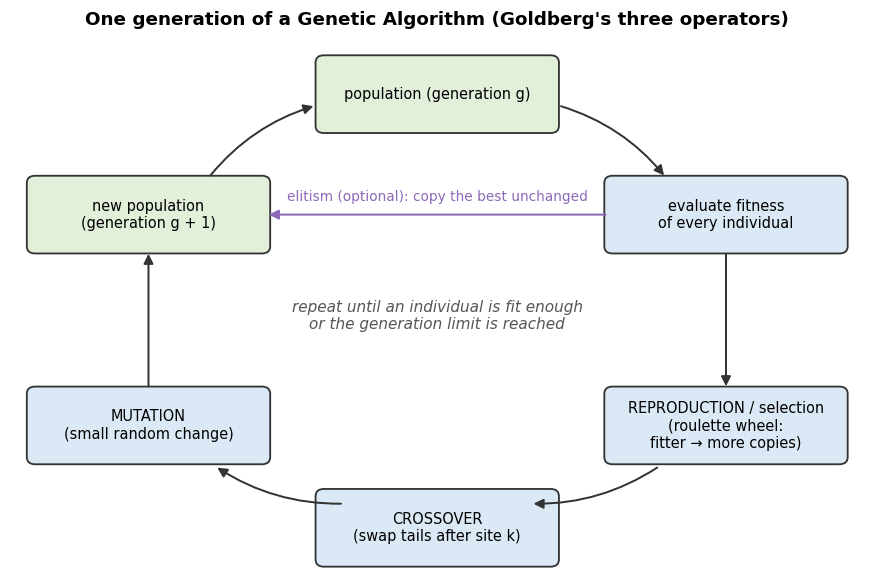

**Line by line.**
- `def reproduction(population, fitness_values, rng):`
  - `f = np.asarray(fitness_values, dtype=float)`.
  - `idx = rng.choice(len(population), size=len(population), p=f / f.sum())` — draws N indices **with replacement**, each with probability $f_i/\sum f$: N spins of the roulette wheel. Roulette requires non-negative fitness, which holds here.
  - `return [population[i] for i in idx]` — the mating pool.
- `def crossover(parent1, parent2, k): return parent1[:k] + parent2[k:], parent2[:k] + parent1[k:]` — string slicing: the first k characters from one parent, the rest from the other, and the mirror image. Slicing is 0-based, so `[:k]` is positions 1…k in the slides' 1-based numbering, and positions k+1…L are swapped, exactly the slide definition.
- `def mutation(string, position, new_symbol): return string[:position - 1] + new_symbol + string[position:]` — replace the character at a **1-based** position, hence `position − 1`.
- Crossover demo: two 8-symbol strings ("square wave" ⊓ and "triangle wave" ∧) crossed at k = 3. The prints insert a `|` at the crossing site.
- Mutation demo: position 6 of `32748552` becomes `1`.
- Roulette check: `pool_counts = np.zeros(4)`; 10,000 times, run `reproduction([0, 1, 2, 3], [24, 23, 20, 11], rng)` (selecting *indices* so they can be counted) and add `np.bincount(picks, minlength=4)`, which counts how many times each index was picked. Finally convert to percentages.

**Reading the output.** The crossover produces `⊓⊓⊓|∧∧∧∧∧` and `∧∧∧|⊓⊓⊓⊓⊓`. The mutation gives `32748552 → 32748152`. The observed roulette shares (30.2%, 29.9%, 26.2%, 13.8%) match the theoretical 24/78, 23/78, 20/78 and 11/78, i.e. 31%, 29%, 26% and 14%.

### 4.3 The slides' 8-queens example, reproduced step by step
The slide figure shows one GA generation on 8-queens with a population of 4: **(a)** initial population → **(b)** fitness → **(c)** selection → **(d)** crossover → **(e)** mutation. We recompute every number in that figure.

(a) INITIAL POPULATION   (b) FITNESS = non-attacking pairs, and selection probability
    24748552    fitness 24    P(selected) = 24/78 = 31%
    32752411    fitness 23    P(selected) = 23/78 = 29%
    24415124    fitness 20    P(selected) = 20/78 = 26%
    32543213    fitness 11    P(selected) = 11/78 = 14%

(c) SELECTION: four roulette spins. The slide shows this outcome:
    32752411   (fitness 23)
    24748552   (fitness 24)
    32752411   (fitness 23)
    24415124   (fitness 20)
    Note: 32543213 (fitness 11) was not selected, and 32752411 was selected twice.
    Probability of this exact sequence of spins = 0.0069; it is one random outcome among many.

(d) CROSSOVER: pairs (1,2) and (3,4), crossing sites k = 3 and k = 5 (as on the slide)
    327|52411 x 247|48552  ->  32748552  and  24752411
    32752|411 x 24415|124  ->  32752124  and  24415411

(e) MUTATION: the slide changes position 6 of child 1, position 3 of child 3, position 8 of child 4
    32748552 -> 32748152   (positi

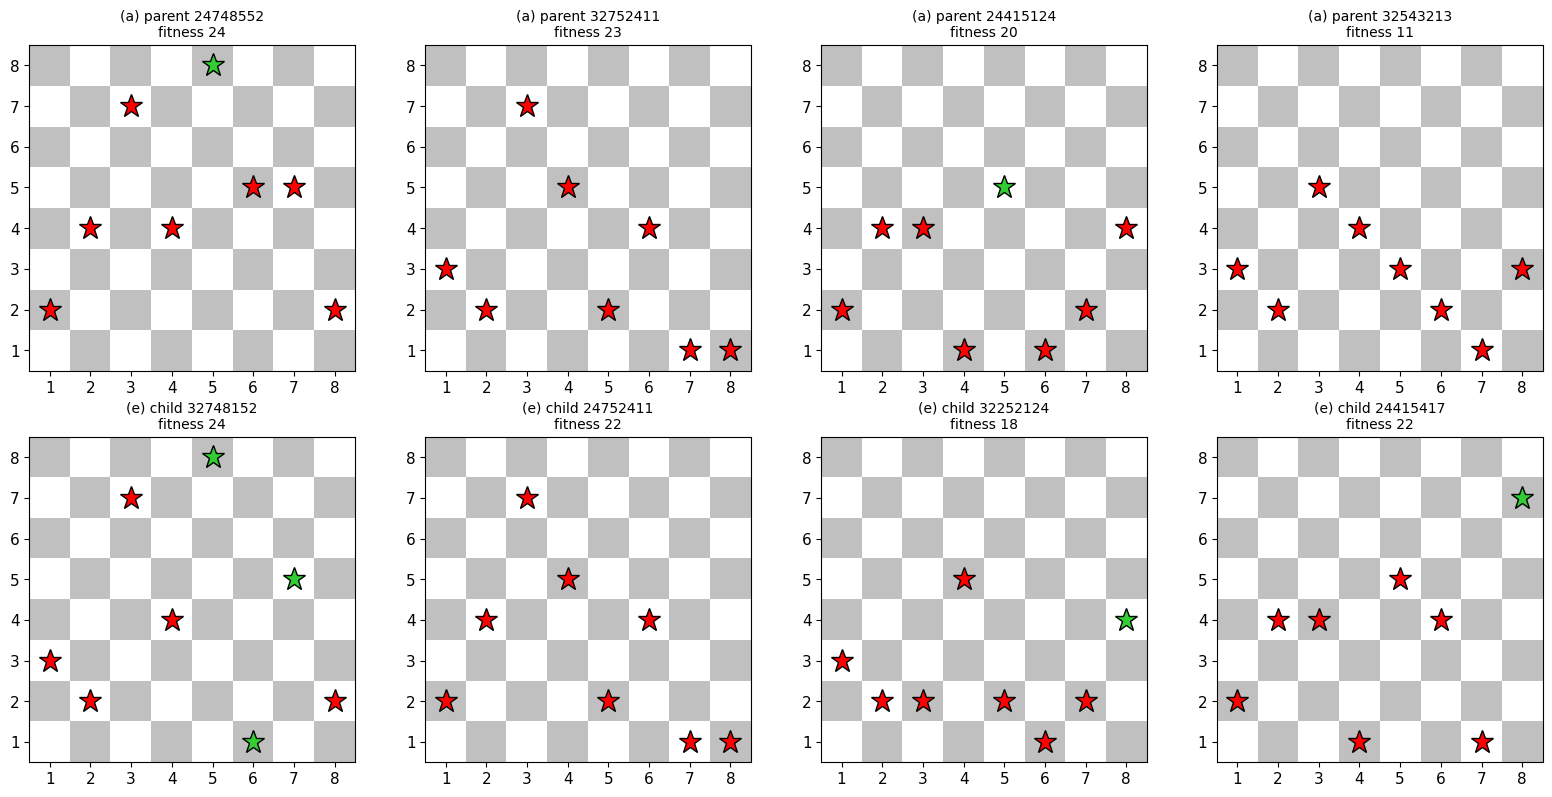

In [ ]:
pop_a = ["24748552", "32752411", "24415124", "32543213"]

print("(a) INITIAL POPULATION   (b) FITNESS = non-attacking pairs, and selection probability")
fit_b = np.array([non_attacking_pairs(queens(s)) for s in pop_a])
p_b = fit_b / fit_b.sum()
for s, fv, p in zip(pop_a, fit_b, p_b):
    print(f"    {s}    fitness {fv:2d}    P(selected) = {fv}/{fit_b.sum()} = {p:.0%}")

print("\n(c) SELECTION: four roulette spins. The slide shows this outcome:")
pool_c = ["32752411", "24748552", "32752411", "24415124"]
for s in pool_c:
    print(f"    {s}   (fitness {non_attacking_pairs(queens(s))})")
prob_of_this_pool = np.prod([p_b[pop_a.index(s)] for s in pool_c])
print(f"    Note: 32543213 (fitness 11) was not selected, and 32752411 was selected twice.")
print(f"    Probability of this exact sequence of spins = {prob_of_this_pool:.4f}; it is one random outcome among many.")

print("\n(d) CROSSOVER: pairs (1,2) and (3,4), crossing sites k = 3 and k = 5 (as on the slide)")
pool_d = []
for (p1, p2), k in zip([(pool_c[0], pool_c[1]), (pool_c[2], pool_c[3])], [3, 5]):
    c1, c2 = crossover(p1, p2, k)
    pool_d += [c1, c2]
    print(f"    {p1[:k]}|{p1[k:]} x {p2[:k]}|{p2[k:]}  ->  {c1}  and  {c2}")

print("\n(e) MUTATION: the slide changes position 6 of child 1, position 3 of child 3, position 8 of child 4")
mutations = [(6, "1"), None, (3, "2"), (8, "7")]
pop_e = []
for c, m in zip(pool_d, mutations):
    new = mutation(c, *m) if m else c
    pop_e.append(new)
    note = f"position {m[0]}: '{c[m[0] - 1]}' -> '{m[1]}'" if m else "no mutation"
    print(f"    {c} -> {new}   ({note})   fitness {non_attacking_pairs(queens(c))} -> {non_attacking_pairs(queens(new))}")

fit_e = np.array([non_attacking_pairs(queens(s)) for s in pop_e])
print(f"\nGeneration summary: average fitness {fit_b.mean():.2f} -> {fit_e.mean():.2f},  best {fit_b.max()} -> {fit_e.max()}")

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, s in zip(axes[0], pop_a):
    draw_board(s, ax, f"(a) parent {s}\nfitness {non_attacking_pairs(queens(s))}")
for ax, s in zip(axes[1], pop_e):
    draw_board(s, ax, f"(e) child {s}\nfitness {non_attacking_pairs(queens(s))}")
plt.tight_layout(); plt.show()

#### 🔍 Explanation of the cell above — the slides' 8-queens generation, step by step

**Concept.** The slide figure shows one generation of a GA on 8-queens with population 4, in five stages: (a) initial population, (b) fitness, (c) selection, (d) crossover, (e) mutation. This cell recomputes every number so that each stage can be checked. Selection, crossing sites and mutations are set to **the specific outcomes shown on the slide** rather than drawn at random, so the output matches the figure exactly.

Two lessons come out of it. Selection is random, so the slide's outcome is just one possibility among many (its probability is computed explicitly). And a single generation raises the *average* fitness without necessarily producing a better *best* individual.

**Diagram.** Crossover and mutation on the first pair from the slide. The children keep the first three digits (queens in columns 1–3) of one parent and the remaining five of the other. Mutation then changes one digit, here moving the queen in column 6 to row 1.

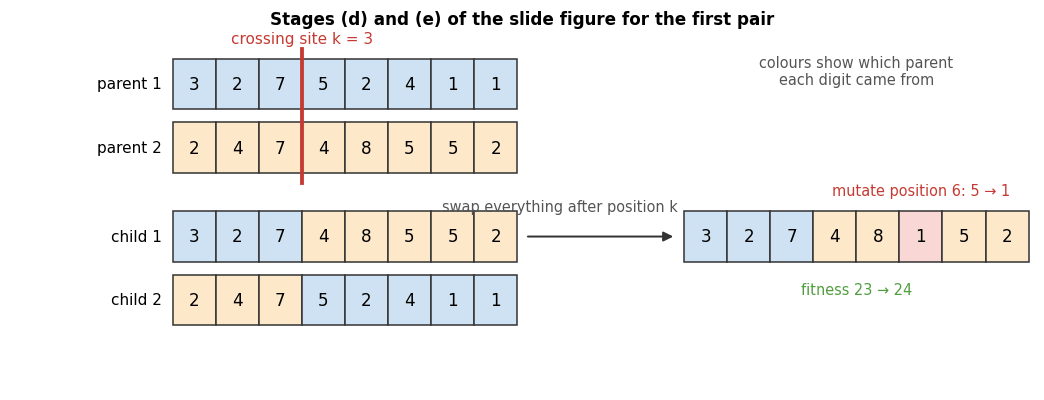

**Line by line.**
- `pop_a = [...]` — (a) the four initial boards as strings.
- `fit_b = np.array([non_attacking_pairs(queens(s)) for s in pop_a])` — (b) fitness of each: 24, 23, 20, 11.
- `p_b = fit_b / fit_b.sum()` — roulette probabilities (the sum is 78).
- The loop prints each board's fitness and probability; `{p:.0%}` formats as a whole-number percentage.
- `pool_c = [...]` — (c) the mating pool shown on the slide: board 2 twice, boards 1 and 3 once, board 4 not at all.
- `prob_of_this_pool = np.prod([p_b[pop_a.index(s)] for s in pool_c])` — for each pool member, `pop_a.index(s)` finds which parent it is; multiplying the four probabilities gives the chance of this exact sequence of spins: $0.295 \times 0.308 \times 0.295 \times 0.256 \approx 0.0069$.
- (d) crossover: `zip([(pool_c[0], pool_c[1]), (pool_c[2], pool_c[3])], [3, 5])` pairs members 1–2 with crossing site 3 and members 3–4 with site 5; `crossover(p1, p2, k)` makes two children per pair; `pool_d += [c1, c2]` collects them.
- (e) mutation: `mutations = [(6, "1"), None, (3, "2"), (8, "7")]` lists (position, new symbol) per child, with `None` meaning no mutation.
  - `new = mutation(c, *m) if m else c` — `*m` unpacks the tuple into the two arguments.
  - `c[m[0] - 1]` is the old symbol (converting the 1-based position to a 0-based index), used in the note.
  - The print shows each child's fitness before and after mutation.
- `fit_e` — fitness of the new generation; the summary prints average and best before and after.
- The figure draws the four parents (top row) and four children (bottom row) as boards.

**Reading the output.** The crossovers give `32748552`, `24752411`, `32752124`, `24415411`. The mutations change fitness 23 → 24 (helped), 21 → 18 (hurt) and 20 → 22 (helped). The average fitness rises from 19.5 to 21.5, but the best stays at 24 and no child is a solution yet. A GA improves the population gradually over many generations.

**Discussion points for this slide:**
- The weakest individual (fitness 11) was *not* selected: survival of the fittest. But selection is only **probabilistic**: it had a 14% chance per spin.
- After one generation, the **average** fitness improved from 19.5 to 21.5, but **no child is a solution yet**, and the best fitness did not exceed the best parent's (24). A GA improves the population gradually, over many generations.
- Mutation can help or hurt: one mutation raised a child's fitness from 23 to 24; another lowered a child's fitness from 21 to 18. It is a source of diversity, not of guaranteed improvement.
- On 8-queens, crossover is meaningful because each digit has a fixed meaning (the row of the queen in that column). A child inherits a correct placement of columns 1..k from one parent and k+1..8 from the other.

### 4.4 Design components of a GA  *(slide: "Each individual is a string over a finite alphabet…")*
The slide lists the choices that define a particular GA:

| Component | Meaning | In the 8-queens example |
|---|---|---|
| **Representation** | Each individual is a string over a finite alphabet, like DNA | 8 characters from the alphabet {1,…,8} |
| **Selection** | How parents of the next generation are chosen | Fitness-proportionate (roulette) |
| **Recombination** | How parents are combined | One-point crossover |
| **Mutation rate** | How often offspring receive random mutations | A small probability per child |
| **Elitism** | Copy the top individuals unchanged into the next generation | Guarantees the best solution is never lost |
| **Culling** | Discard all individuals below a threshold before selection | Increases selection pressure |

Other representations are possible when the problem demands them (later sections use these):

| Encoding | Chromosome example | Meaning | Used for |
|---|---|---|---|
| Binary | `1 0 1 1 0 0 1` | item in/out, feature on/off | Knapsack, feature selection |
| Integer string | `2 4 7 4 8 5 5 2` | value per position | 8-queens (this part) |
| Real-valued | `[0.31, -2.4, 1.07]` | coordinates directly | Continuous optimization, weights |
| Permutation | `[2, 0, 4, 1, 3]` | an ordering | TSP, scheduling |

**The central tension: selection pressure vs. diversity.**
- **Too much pressure** (heavy culling, no mutation) causes *premature convergence*: the population becomes near-clones stuck in one region.
- **Too little pressure** (lots of mutation, weak selection) turns the GA into random search.
Elitism, culling, and the mutation rate are the knobs that set this balance; Section 4.6 measures their effect.

### 4.5 The slides' pseudocode, line by line
```
function GENETIC-ALGORITHM(population, fitness) returns an individual
    repeat
        weights ← WEIGHTED-BY(population, fitness)
        population2 ← empty list
        for i = 1 to SIZE(population) do
            parent1, parent2 ← WEIGHTED-RANDOM-CHOICES(population, weights, 2)
            child ← REPRODUCE(parent1, parent2)
            if (small random probability) then child ← MUTATE(child)
            add child to population2
        population ← population2
    until some individual is fit enough, or enough time has elapsed
    return the best individual in population, according to fitness

function REPRODUCE(parent1, parent2) returns an individual
    n ← LENGTH(parent1)
    c ← random number from 1 to n
    return APPEND(SUBSTRING(parent1, 1, c), SUBSTRING(parent2, c+1, n))
```

| Line | Meaning |
|---|---|
| `weights ← WEIGHTED-BY(...)` | Selection weights proportional to fitness, i.e. the roulette wheel (*reproduction* in Goldberg's terms) |
| `WEIGHTED-RANDOM-CHOICES(..., 2)` | Draw two parents at random according to those weights |
| `child ← REPRODUCE(p1, p2)` | **Crossover**: the head of parent 1 joined to the tail of parent 2 |
| `if (small random probability) MUTATE` | **Mutation** with a small probability per child |
| `until fit enough, or enough time` | **Stopping criteria:** a target fitness (28 for 8-queens) *or* a maximum number of generations |
| `return the best individual` | The answer is the fittest member of the final population |

Differences from the operator slides, worth pointing out:
- This pseudocode makes **one child per pair of parents**; Goldberg's version (Section 4.3) makes **two**.
- `REPRODUCE` picks $c$ from 1 to $n$. With $c = n$, the child is simply a copy of parent 1. The crossover slide uses $k \in [1, L-1]$, which always mixes both parents; we follow the slide.
- The pseudocode has no elitism or culling; the components slide adds them as options. Our implementation includes both as switches, which are off by default.

Best individual 12768354 with fitness 25/28 after 300 generations -> not solved within the generation limit


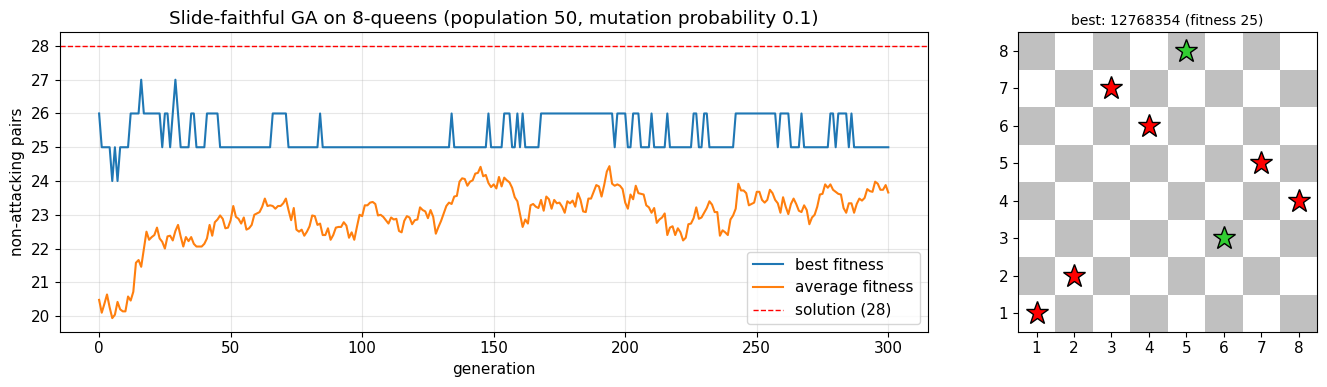

In [ ]:
def reproduce(parent1, parent2, rng):
    # REPRODUCE (= crossover): head of parent1 + tail of parent2, crossing site c in [1, n-1].
    n = len(parent1)
    c = rng.integers(1, n)
    return np.concatenate([parent1[:c], parent2[c:]])

def mutate(child, alphabet, rng):
    # MUTATE: replace one random position with a random symbol from the alphabet.
    child = child.copy()
    child[rng.integers(len(child))] = rng.choice(alphabet)
    return child

def genetic_algorithm_slides(population, fitness, alphabet, mutation_prob=0.1, fit_enough=None,
                             max_gens=300, elite=0, cull=0.0, rng=None):
    # Faithful translation of the slide pseudocode, plus optional elitism and culling (both off by default).
    # population: (N, L) integer array; fitness: function returning an array of fitness values (higher is better).
    rng = rng or np.random.default_rng()
    N = len(population)
    history = []
    for gen in range(max_gens + 1):
        f = fitness(population).astype(float)
        history.append((f.max(), f.mean()))
        if (fit_enough is not None and f.max() >= fit_enough) or gen == max_gens:
            break                                          # until fit enough, or enough time has elapsed
        weights = f.copy()                                 # weights <- WEIGHTED-BY(population, fitness)
        if cull > 0:                                       # culling: discard individuals below a threshold
            weights[f < np.quantile(f, cull)] = 0
        if weights.sum() == 0:
            weights[:] = 1
        population2 = [population[i].copy() for i in np.argsort(-f)[:elite]]   # elitism: keep the best
        parents = rng.choice(N, size=(N - elite, 2), p=weights / weights.sum())  # WEIGHTED-RANDOM-CHOICES
        for i, j in parents:                               # for i = 1 to SIZE(population)
            child = reproduce(population[i], population[j], rng)
            if rng.random() < mutation_prob:               # if (small random probability)
                child = mutate(child, alphabet, rng)
            population2.append(child)                      # add child to population2
        population = np.array(population2)                 # population <- population2
    f = fitness(population)
    best = np.argmax(f)
    return population[best], f[best], gen, np.array(history)

# One run on 8-queens, exactly as in the pseudocode (no elitism, no culling)
ALPHABET_8Q = np.arange(1, 9)
rng = np.random.default_rng(SEED)
init_pop = rng.integers(1, 9, size=(50, 8))
best, best_fit, gens, hist = genetic_algorithm_slides(init_pop, non_attacking_pairs, ALPHABET_8Q,
                                                      mutation_prob=0.1, fit_enough=28, max_gens=300, rng=rng)
status = "SOLVED" if best_fit == 28 else "not solved within the generation limit"
print(f"Best individual {to_str(best)} with fitness {best_fit}/28 after {gens} generations -> {status}")

fig = plt.figure(figsize=(14, 4))
ax1 = fig.add_subplot(1, 3, (1, 2))
ax1.plot(hist[:, 0], label="best fitness"); ax1.plot(hist[:, 1], label="average fitness")
ax1.axhline(28, color="r", ls="--", lw=1, label="solution (28)")
ax1.set_xlabel("generation"); ax1.set_ylabel("non-attacking pairs"); ax1.legend()
ax1.set_title("Slide-faithful GA on 8-queens (population 50, mutation probability 0.1)")
draw_board(best, fig.add_subplot(1, 3, 3), f"best: {to_str(best)} (fitness {best_fit})")
plt.tight_layout(); plt.show()

#### 🔍 Explanation of the cell above — the slide GA pseudocode as working code

**Concept.** This implements the textbook pseudocode `GENETIC-ALGORITHM(population, fitness)`:
- Compute selection weights proportional to fitness (`WEIGHTED-BY`).
- For each slot in the new population: draw two parents by weighted random choice, produce **one** child with `REPRODUCE` (which is crossover, despite the name), mutate it with a small probability, and add it.
- Replace the population and repeat **until** an individual is fit enough (fitness 28) **or** enough time has passed (a generation limit).
- Return the best individual.

Two optional extensions from the "design components" slide are included, both off by default:
- **Elitism** (`elite > 0`): copy the top individuals unchanged into the next generation, so the best solution can never be lost.
- **Culling** (`cull > 0`): before selection, give zero weight to individuals below a fitness quantile (e.g. the bottom half). This increases *selection pressure*.

**Diagram.** The two optional switches in `genetic_algorithm_slides`. Elitism copies the top individuals (purple) into the next generation untouched. Culling sets the selection weight of everyone below a fitness quantile (grey) to zero, so all parents come from the stronger half; this raises selection pressure.

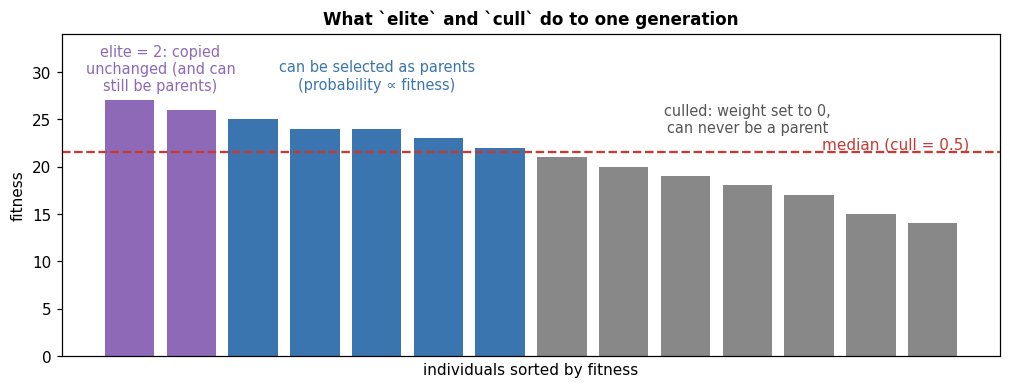

**Line by line — operators.**
- `def reproduce(parent1, parent2, rng):` — `c = rng.integers(1, n)` draws the crossing site from 1 to n−1 (the upper bound is exclusive), so the child always contains material from both parents. `np.concatenate([parent1[:c], parent2[c:]])` joins the head of parent 1 to the tail of parent 2.
- `def mutate(child, alphabet, rng):` — copy, then `child[rng.integers(len(child))] = rng.choice(alphabet)` sets one random position to a random symbol.

**Line by line — `genetic_algorithm_slides`.**
- Parameters: initial `population` (an N × L integer array), a vectorised `fitness` function, the `alphabet`, `mutation_prob`, the target `fit_enough`, the limit `max_gens`, and `elite`/`cull`.
- `N = len(population)`; `history = []`.
- `for gen in range(max_gens + 1):` — generation 0 is the initial population, so there are `max_gens + 1` evaluations and at most `max_gens` rounds of breeding.
  - `f = fitness(population).astype(float)` — evaluate everyone at once.
  - `history.append((f.max(), f.mean()))` — record best and mean.
  - `if (fit_enough is not None and f.max() >= fit_enough) or gen == max_gens: break` — the `until` condition: fit enough or out of time.
  - `weights = f.copy()` — `WEIGHTED-BY`: weights equal to fitness.
  - `if cull > 0: weights[f < np.quantile(f, cull)] = 0` — culling: `np.quantile(f, 0.5)` is the median fitness, and everyone below it gets zero weight.
  - `if weights.sum() == 0: weights[:] = 1` — safety net: if all weights are zero, fall back to uniform selection instead of dividing by zero.
  - `population2 = [population[i].copy() for i in np.argsort(-f)[:elite]]` — elitism: `np.argsort(-f)` orders indices from highest to lowest fitness, and the first `elite` are copied. With `elite = 0` the list starts empty, exactly as in the pseudocode.
  - `parents = rng.choice(N, size=(N - elite, 2), p=weights / weights.sum())` — `WEIGHTED-RANDOM-CHOICES` for all remaining slots at once: each row is a (parent 1, parent 2) pair of indices, drawn with replacement.
  - `for i, j in parents:` — `for i = 1 to SIZE(population)`:
    - `child = reproduce(population[i], population[j], rng)`.
    - `if rng.random() < mutation_prob: child = mutate(child, alphabet, rng)`.
    - `population2.append(child)`.
  - `population = np.array(population2)` — `population ← population2`.
- After the loop: `best = np.argmax(f)` on the final population; return the best individual, its fitness, the generation reached, and the history array.

**Line by line — the demo run.**
- `ALPHABET_8Q = np.arange(1, 9)` — symbols 1–8.
- `init_pop = rng.integers(1, 9, size=(50, 8))` — 50 random boards.
- The call uses mutation probability 0.1, target 28 and at most 300 generations, with no elitism or culling (pure pseudocode).
- The plot shows best and average fitness per generation, a dashed line at 28, and the best board.

**Reading the output.** This run reaches 25/28 after 300 generations without solving. The average fitness rises quickly and then plateaus: the population converges before finding a solution (*premature convergence*). The next experiment checks whether this is bad luck or a real weakness.

> ⚠️ *Notes:* (1) Parent pairs are drawn with replacement, so an individual can occasionally be paired with itself, which produces a copy. (2) `mutate` can draw the symbol that is already there (probability 1/8), so the effective mutation rate is about 7/8 of `mutation_prob`. Both behaviours are faithful to the pseudocode.

### 4.6 Elitism, culling, and mutation rate: an experiment  *(slide: "mutation rate… elitism and culling")*
The single run above stopped at fitness 25/28 after 300 generations. Was that bad luck, or is the plain pseudocode genuinely weak on this problem? A single run cannot tell us, so we repeat over many seeds.

How much do the components from Section 4.4 actually matter? Same GA, same 8-queens problem, 30 random seeds per setting, at most 300 generations, population 50. We try every combination of:
- mutation probability **0.1** (low) vs. **0.6** (high);
- **plain** (exactly the pseudocode), **+ elitism** (keep the top 2), **+ culling** (discard the bottom half before selection), **+ both**.

(ran 240 GA runs in 33s)

 mutation prob.      variant   solved   median generations (solved runs)
            0.1        plain      37%                                190
            0.1    + elitism      37%                                 63
            0.1    + culling      30%                                 43
            0.1       + both      40%                                 25
            0.6        plain      17%                                206
            0.6    + elitism      47%                                 82
            0.6    + culling      90%                                 58
            0.6       + both      83%                                 45


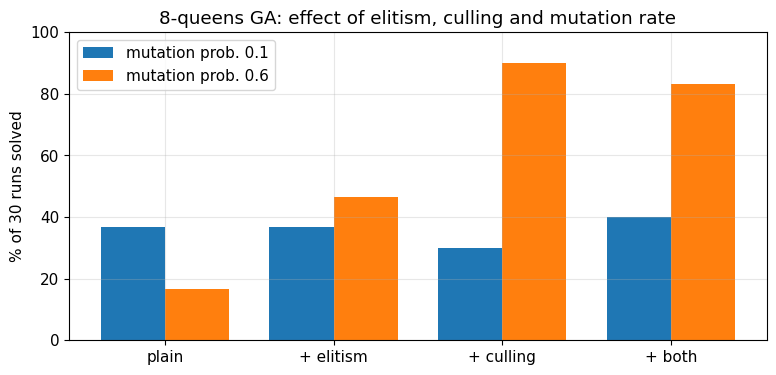

In [ ]:
RUNS = 30
variants = {"plain": {}, "+ elitism": dict(elite=2), "+ culling": dict(cull=0.5), "+ both": dict(elite=2, cull=0.5)}
table = {}
t0 = time.perf_counter()
for pm in [0.1, 0.6]:
    for name, kw in variants.items():
        res = [genetic_algorithm_slides(np.random.default_rng(s).integers(1, 9, (50, 8)), non_attacking_pairs,
                                        ALPHABET_8Q, mutation_prob=pm, fit_enough=28, max_gens=300,
                                        rng=np.random.default_rng(500 + s), **kw) for s in range(RUNS)]
        solved = [g for _, fb, g, _ in res if fb == 28]
        table[(pm, name)] = (len(solved) / RUNS, np.median(solved) if solved else np.nan)
print(f"(ran {8 * RUNS} GA runs in {time.perf_counter() - t0:.0f}s)\n")
print(f"{'mutation prob.':>15s} {'variant':>12s} {'solved':>8s} {'median generations (solved runs)':>34s}")
for (pm, name), (rate, med) in table.items():
    print(f"{pm:15.1f} {name:>12s} {rate:8.0%} {med:34.0f}")

fig, ax = plt.subplots(figsize=(9, 4))
xs = np.arange(len(variants)); w = 0.38
for k, (pm, color) in enumerate([(0.1, "tab:blue"), (0.6, "tab:orange")]):
    ax.bar(xs + (k - 0.5) * w, [100 * table[(pm, v)][0] for v in variants], w, color=color, label=f"mutation prob. {pm}")
ax.set_xticks(xs, list(variants)); ax.set_ylabel(f"% of {RUNS} runs solved"); ax.set_ylim(0, 100); ax.legend()
ax.set_title("8-queens GA: effect of elitism, culling and mutation rate")
plt.show()

#### 🔍 Explanation of the cell above — elitism, culling and mutation rate: an experiment

**Concept.** A GA has to balance two forces:
- **Selection pressure**: how strongly fitter individuals are favoured. Too little and the GA becomes random search; too much and it causes *premature convergence*, where the population collapses into near-copies of one individual.
- **Diversity**: provided mainly by mutation. Too little and the search stalls; too much and good individuals are destroyed before they can be exploited.

Elitism and culling add pressure (or protection); the mutation rate adds diversity. This cell measures their **interaction** with a full grid: 2 mutation rates × 4 variants × 30 seeds = 240 runs. Every setting uses the **same 30 initial populations** (a paired design), so differences come from the settings, not from luck in initialisation.

**Diagram.** The central GA trade-off. Mutation pushes the population toward diversity; elitism and culling push it toward exploitation. Either extreme fails, which is why the experiment found that high mutation works only *together with* culling.

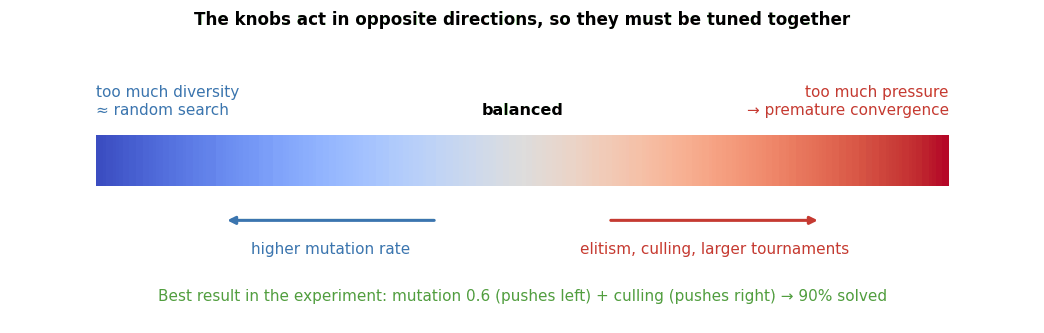

**Line by line.**
- `RUNS = 30`.
- `variants = {...}` — keyword arguments per variant: `{}` (plain), `elite=2`, `cull=0.5` (discard the bottom half), or both.
- `table = {}`; `t0 = time.perf_counter()`.
- `for pm in [0.1, 0.6]: for name, kw in variants.items():`
  - The list comprehension runs the GA for seeds 0–29: initial population from `default_rng(s)` (identical across settings), evolution randomness from `default_rng(500 + s)`, and `**kw` unpacking the variant's options into keyword arguments.
  - `solved = [g for _, fb, g, _ in res if fb == 28]` — for solved runs only, the generation at which they solved.
  - `table[(pm, name)] = (len(solved) / RUNS, np.median(solved) if solved else np.nan)` — success rate and median generations (NaN, "not a number", if no run solved).
- Prints: total runtime, then one row per setting.
- Grouped bar chart: `xs = np.arange(len(variants)); w = 0.38`; for each mutation rate, bars are shifted by `(k − 0.5) * w`, i.e. half a bar width left or right, so the two rates sit side by side above each variant.

**Reading the output.** At p = 0.1 all variants solve 30–40% of runs: diversity runs out, and extra pressure cannot fix that. At p = 0.6, plain drops to 17% (heavy mutation destroys good boards and nothing protects them), elitism alone gives 47%, culling gives 90%, and both give 83%. High mutation (diversity) combined with culling (pressure) is clearly best. The parameters must be tuned *together*.

> ⚠️ *Two things to keep in mind:* (1) With 30 runs per bar, a success rate is uncertain by about ±9 percentage points (one standard error, $\sqrt{0.5 \cdot 0.5 / 30} \approx 0.09$), so only large differences are meaningful. (2) The "median generations" column uses *solved runs only*. A setting that solves 30% of runs quickly is not "faster" than one that solves 90% more slowly; the median ignores every run that failed (survivorship bias).

**How to read this experiment.** With 30 runs per bar, a success rate is uncertain by roughly ±9 percentage points (one standard error). Only differences much larger than that should be trusted.

- **Low mutation (0.1):** all four variants land in a similar range. The population tends to converge to near-identical individuals (premature convergence); once diversity is gone, extra selection pressure from elitism or culling cannot help.
- **High mutation (0.6) without elitism or culling:** performance gets clearly *worse*. Heavy mutation keeps destroying good individuals, and nothing protects them, which matches the slide's warning that the operators must be balanced.
- **High mutation (0.6) with culling (with or without elitism):** this is clearly the best setting here. Mutation supplies diversity, while culling supplies enough selection pressure to keep and exploit good individuals. Elitism alone helps less: it protects only the top 2, while roulette selection over fitness values between roughly 15 and 27 still gives weak individuals nearly as many offspring as strong ones.
- The lesson matches the slide: the **mutation rate, elitism, and culling interact**. A good setting balances exploration (mutation) against exploitation (selection pressure). Tune them together, not one at a time.

Compare this with SA in Section 3.6: on 8-queens, the slowly cooled SA solved 49 of 50 boards with a single state and no population. On this problem, a well-tuned SA is the stronger and simpler choice. Different problems favour different algorithms; Part 5 returns to this question.

The remaining sections of Part 4 go beyond the slides: another by-hand example with a binary alphabet, binary GAs with a known optimum, real-valued GAs, and permutation GAs.

### 4.7 One generation by hand: the classic $x^2$ example (Goldberg, 1989)
This is the same procedure as Section 4.3, but with a **binary alphabet** and a step-by-step roulette, crossover, and mutation driven by a random number generator rather than fixed choices.

**Problem:** *maximize* $f(x) = x^2$ for integer $x \in \{0, \dots, 31\}$. Each $x$ is encoded with 5 bits; for example, `01101` is $13$.

The answer is obviously $x = 31$ (`11111`). The point is to watch **every step** of one GA generation with a population of only 4.

**Roulette-wheel selection** (fitness-proportionate) gives individual $i$ a slice of a wheel proportional to its fitness:
$$p_i = \frac{f_i}{\sum_j f_j}$$

STEP 1 - Evaluate the initial population
 #  chromosome    x   f=x²  P(select)  expected copies
 0       01101   13    169      0.144             0.58
 1       11000   24    576      0.492             1.97
 2       01000    8     64      0.055             0.22
 3       10011   19    361      0.309             1.23
   sum f = 1170,  avg f = 292.5,  max f = 576


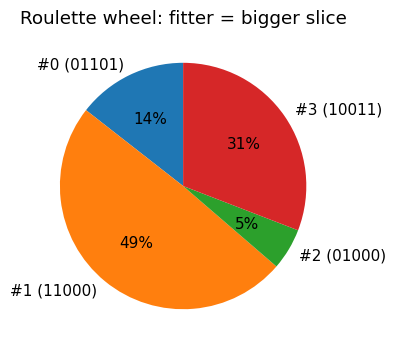

In [ ]:
def decode(bits):
    return int("".join(map(str, bits)), 2)

pop = np.array([[0, 1, 1, 0, 1],
                [1, 1, 0, 0, 0],
                [0, 1, 0, 0, 0],
                [1, 0, 0, 1, 1]])
xs = np.array([decode(b) for b in pop])
fit = xs.astype(float) ** 2
p_sel = fit / fit.sum()

print("STEP 1 - Evaluate the initial population")
print(f"{'#':>2} {'chromosome':>11} {'x':>4} {'f=x²':>6} {'P(select)':>10} {'expected copies':>16}")
for i, (b, x, fv, p) in enumerate(zip(pop, xs, fit, p_sel)):
    print(f"{i:2d} {''.join(map(str, b)):>11} {x:4d} {fv:6.0f} {p:10.3f} {4 * p:16.2f}")
print(f"   sum f = {fit.sum():.0f},  avg f = {fit.mean():.1f},  max f = {fit.max():.0f}")

plt.figure(figsize=(4, 4))
plt.pie(p_sel, labels=[f"#{i} ({''.join(map(str, b))})" for i, b in enumerate(pop)], autopct="%1.0f%%", startangle=90)
plt.title("Roulette wheel: fitter = bigger slice"); plt.show()

#### 🔍 Explanation of the cell above — the classic $x^2$ example: setup and roulette wheel

**Concept.** Goldberg's textbook example: maximise $f(x) = x^2$ for integer $x \in \{0, \dots, 31\}$, encoded as a 5-bit binary string (`01101` = 13). The answer (31 = `11111`) is obvious; the point is to watch one GA generation in full detail with a population of only 4.

**Roulette-wheel selection** gives individual $i$ selection probability $p_i = f_i / \sum_j f_j$. With $N$ spins, the **expected number of copies** of individual $i$ in the mating pool is $N p_i = f_i / \bar f$: an individual twice as fit as the average expects two copies.

**Diagram.** Two views of roulette-wheel selection. Lay the slices end to end on [0, 1]; each spin draws a uniform $u$ and picks the slice it lands in. The slice widths are $f_i/\sum f$, so $x = 24$ (49%) is picked about twice as often as the average individual.

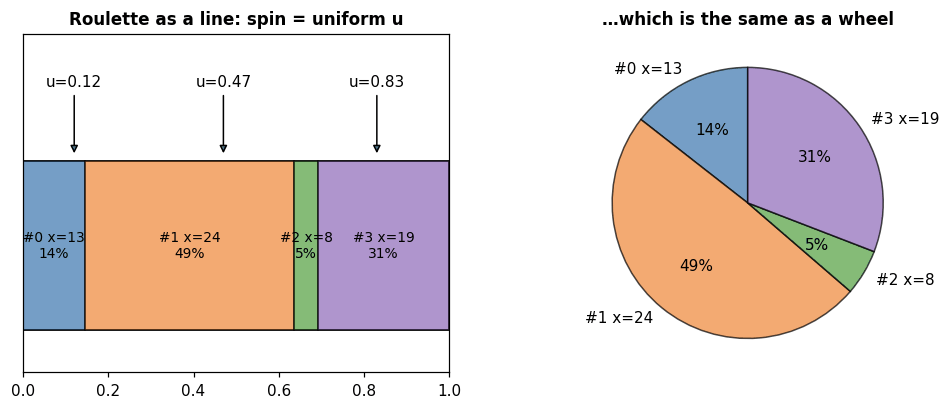

**Line by line.**
- `def decode(bits): return int("".join(map(str, bits)), 2)` — join the bits into a string such as `"01101"`, then parse it in base 2 to get 13.
- `pop = np.array([...])` — the four 5-bit chromosomes (the classic textbook population).
- `xs = np.array([decode(b) for b in pop])` — decoded values: 13, 24, 8, 19.
- `fit = xs.astype(float) ** 2` — fitness $x^2$ (converted to float so later divisions are clean).
- `p_sel = fit / fit.sum()` — roulette probabilities.
- The print loop shows each chromosome, $x$, $f$, $p$, and expected copies `4 * p`.
- The summary line shows the sum, average and maximum fitness.
- `plt.pie(p_sel, labels=..., autopct="%1.0f%%", startangle=90)` — the roulette wheel as a pie chart; `autopct` prints the percentage on each slice.

**Reading the output.** $x = 24$ has fitness 576 out of 1170 (49%) and expects about 2 copies; $x = 8$ has 5.5% and expects only 0.22 copies, so it will probably be lost. The average fitness is 292.5 and the best is 576.

In [ ]:
rng = np.random.default_rng(1)

print("STEP 2 - Selection: spin the roulette wheel 4 times")
picks = rng.choice(len(pop), size=len(pop), p=p_sel)
mating_pool = pop[picks].copy()
for slot, i in enumerate(picks):
    print(f"   spin {slot}: picked #{i}  {''.join(map(str, pop[i]))}  (x = {xs[i]})")

print("\nSTEP 3 - Crossover: pair them up, cut at a random point, swap tails")
children = mating_pool.copy()
for a in (0, 2):
    cut = rng.integers(1, 5)                          # cut point between bit positions 1..4
    p1, p2 = mating_pool[a], mating_pool[a + 1]
    c1 = np.concatenate([p1[:cut], p2[cut:]]); c2 = np.concatenate([p2[:cut], p1[cut:]])
    children[a], children[a + 1] = c1, c2
    s = lambda v: "".join(map(str, v[:cut])) + "|" + "".join(map(str, v[cut:]))
    print(f"   cut after bit {cut}:  {s(p1)} x {s(p2)}  ->  {s(c1)}  and  {s(c2)}")

print("\nSTEP 4 - Mutation: flip each bit with probability 0.05")
flips = rng.random(children.shape) < 0.05
for i in range(len(children)):
    before = "".join(map(str, children[i]))
    children[i] = children[i] ^ flips[i]
    after = "".join(map(str, children[i]))
    print(f"   {before} -> {after}" + (f"   (bit {np.flatnonzero(flips[i]).tolist()} flipped)" if flips[i].any() else ""))

new_x = np.array([decode(b) for b in children]); new_f = new_x.astype(float) ** 2
print("\nSTEP 5 - The new generation replaces the old one")
print(f"   x values: {xs.tolist()} -> {new_x.tolist()}")
print(f"   avg fitness: {fit.mean():.1f} -> {new_f.mean():.1f}     max fitness: {fit.max():.0f} -> {new_f.max():.0f}")

STEP 2 - Selection: spin the roulette wheel 4 times
   spin 0: picked #1  11000  (x = 24)
   spin 1: picked #3  10011  (x = 19)
   spin 2: picked #0  01101  (x = 13)
   spin 3: picked #3  10011  (x = 19)

STEP 3 - Crossover: pair them up, cut at a random point, swap tails
   cut after bit 1:  1|1000 x 1|0011  ->  1|0011  and  1|1000
   cut after bit 2:  01|101 x 10|011  ->  01|011  and  10|101

STEP 4 - Mutation: flip each bit with probability 0.05
   10011 -> 10010   (bit [4] flipped)
   11000 -> 11000
   01011 -> 01011
   10101 -> 10101

STEP 5 - The new generation replaces the old one
   x values: [13, 24, 8, 19] -> [18, 24, 11, 21]
   avg fitness: 292.5 -> 365.5     max fitness: 576 -> 576


#### 🔍 Explanation of the cell above — one full generation of the $x^2$ GA, driven by random numbers

**Concept.** The same steps as the 8-queens example, but now every random choice is actually random:
1. **Selection** — spin the roulette wheel N times to fill the mating pool.
2. **Crossover** — pair the pool as (0, 1) and (2, 3), choose a random cut, swap tails.
3. **Mutation** — flip *each bit independently* with a small probability (0.05). This is the standard bit-string mutation; it differs from the slide version, which changes exactly one position per mutated child.
4. **Replacement** — the children become the new generation.

**Line by line.**
- `rng = np.random.default_rng(1)`.
- **Step 2 (selection):**
  - `picks = rng.choice(len(pop), size=len(pop), p=p_sel)` — four roulette spins (indices drawn with replacement).
  - `mating_pool = pop[picks].copy()` — the selected chromosomes.
  - The loop prints which individual each spin picked.
- **Step 3 (crossover):**
  - `children = mating_pool.copy()`.
  - `for a in (0, 2):` — the two pairs (0, 1) and (2, 3).
    - `cut = rng.integers(1, 5)` — a cut after bit 1, 2, 3 or 4, never at the ends.
    - `c1 = np.concatenate([p1[:cut], p2[cut:]]); c2 = np.concatenate([p2[:cut], p1[cut:]])` — swap tails.
    - `children[a], children[a + 1] = c1, c2`.
    - `s = lambda v: ...` — a small helper that prints a chromosome with `|` at the cut.
- **Step 4 (mutation):**
  - `flips = rng.random(children.shape) < 0.05` — a 4 × 5 boolean mask: `True` where a bit should flip.
  - For each child: `children[i] = children[i] ^ flips[i]` — XOR with the mask flips exactly the marked bits; `np.flatnonzero(flips[i])` lists which ones.
- **Step 5 (replacement):** decode the children, compute the new fitness, and print old vs. new $x$ values and average/maximum fitness.

**Reading the output.** Individual #3 (x = 19) was picked twice and #2 (x = 8) not at all. One bit flipped (`10011 → 10010`). The $x$ values go from [13, 24, 8, 19] to [18, 24, 11, 21]; the average fitness rises from 292.5 to 365.5 and the maximum stays at 576. Selection removed the weak individual and crossover produced new combinations. With other seeds the outcome differs, and occasionally a generation gets worse.

**What just happened:**
- Selection made **more copies of fit individuals** (high $x$, especially those starting with `1`) and dropped weak ones.
- Crossover **recombined** pieces of parents. A child can inherit a good prefix from one parent and a good suffix from the other.
- Mutation occasionally introduced a bit value that **no parent had**. Without it, a bit position that is 0 in every individual could never become 1.
- Average fitness typically rises from one generation to the next, but not always. Selection and crossover are random, so an occasional generation can get worse.

**A caveat about roulette selection:** it requires positive fitness, and its selection pressure depends on the *scale* of $f$. For example, fitness values of 1000 and 1001 give almost equal slices. From here on we use **tournament selection** instead: pick $k$ random individuals and keep the best. It only compares fitnesses, so it works for both minimization and maximization at any scale.


Best after 40 generations: 40/40 ones  ->  1111111111111111111111111111111111111111


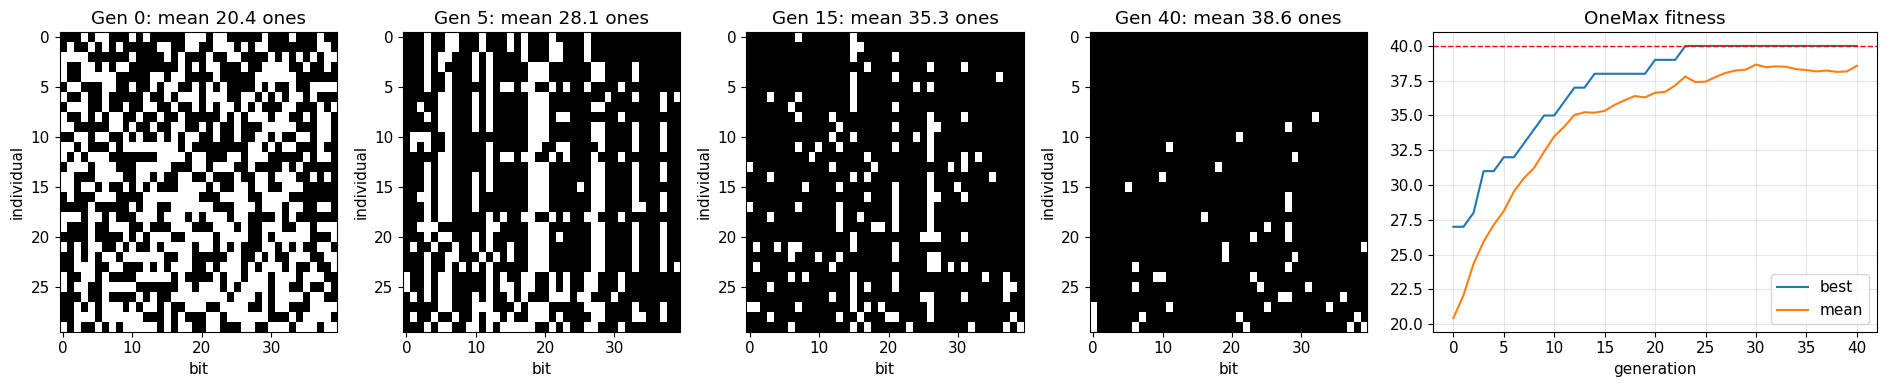

In [32]:
def binary_ga(fitness, n_bits, pop_size=30, n_gens=60, cx_rate=0.9, mut_rate=None,
              k=3, elite=1, rng=None, snapshot_gens=()):
    # Minimal GA for bit strings. MAXIMIZES fitness(bits).
    rng = rng or np.random.default_rng()
    mut_rate = mut_rate if mut_rate is not None else 1.0 / n_bits     # common default: 1 flip per child
    pop = rng.integers(0, 2, size=(pop_size, n_bits))
    fit = np.array([fitness(ind) for ind in pop], dtype=float)
    hist = {"best": [fit.max()], "mean": [fit.mean()], "snapshots": {}}
    if 0 in snapshot_gens: hist["snapshots"][0] = pop.copy()

    for g in range(1, n_gens + 1):
        # 1) elitism: keep the best individual(s) unchanged
        elites = pop[np.argsort(-fit)[:elite]]
        # 2) tournament selection: best of k random individuals
        n_children = pop_size - elite
        contestants = rng.integers(0, pop_size, size=(n_children, k))
        parents = pop[contestants[np.arange(n_children), np.argmax(fit[contestants], axis=1)]]
        # 3) one-point crossover on consecutive pairs
        children = parents.copy()
        for i in range(0, n_children - 1, 2):
            if rng.random() < cx_rate:
                cut = rng.integers(1, n_bits)
                children[i, cut:], children[i + 1, cut:] = parents[i + 1, cut:], parents[i, cut:]
        # 4) bit-flip mutation
        children ^= (rng.random(children.shape) < mut_rate)
        # 5) replacement
        pop = np.vstack([elites, children])
        fit = np.array([fitness(ind) for ind in pop], dtype=float)
        hist["best"].append(fit.max()); hist["mean"].append(fit.mean())
        if g in snapshot_gens: hist["snapshots"][g] = pop.copy()

    i = np.argmax(fit)
    return pop[i], fit[i], hist

onemax = lambda bits: bits.sum()
snaps = (0, 5, 15, 40)
best, best_fit, h = binary_ga(onemax, n_bits=40, pop_size=30, n_gens=40,
                              rng=np.random.default_rng(SEED), snapshot_gens=snaps)
print(f"Best after 40 generations: {best_fit:.0f}/40 ones  ->  {''.join(map(str, best))}")

fig, ax = plt.subplots(1, 5, figsize=(19, 4), gridspec_kw={"width_ratios": [1, 1, 1, 1, 1.6]})
for a, gen in zip(ax[:4], snaps):
    P = h["snapshots"][gen]
    a.imshow(P[np.argsort(-P.sum(1))], cmap="Greys", aspect="auto", interpolation="nearest")
    a.set_title(f"Gen {gen}: mean {P.sum(1).mean():.1f} ones"); a.set_xlabel("bit"); a.set_ylabel("individual"); a.grid(False)
ax[4].plot(h["best"], label="best"); ax[4].plot(h["mean"], label="mean")
ax[4].axhline(40, color="r", ls="--", lw=1); ax[4].set_xlabel("generation"); ax[4].legend()
ax[4].set_title("OneMax fitness")
plt.tight_layout(); plt.show()

#### 🔍 Explanation of the cell above — a complete binary GA on OneMax

**Concept.** A complete, practical GA for bit strings, which **maximises** fitness. Compared with the slide version it uses two common improvements:
- **Tournament selection** instead of roulette: pick $k$ individuals at random and keep the fittest. It needs no positive fitness, does not depend on the *scale* of fitness (only on comparisons), and its pressure is easy to tune: larger $k$ means stronger pressure.
- **Elitism** (1 individual by default), so the best solution is never lost.

The test problem is **OneMax**: maximise the number of 1s in a 40-bit string. The answer is trivial, but with $2^{40} \approx 10^{12}$ strings it shows clearly how good bits *spread* through a population: selection copies strings with many 1s, and crossover combines the 1s of different parents.

The default mutation rate $1/n$ flips on average **one bit per child**, a widely used rule of thumb.

**Diagram.** Why the later GAs switch from roulette to tournament selection. Roulette probabilities depend on the *scale* of fitness: shifting all values by 1000 makes every slice almost equal, so selection stops favouring the fit. A tournament only compares values, so any shift or rescaling leaves it unchanged; larger $k$ means stronger pressure.

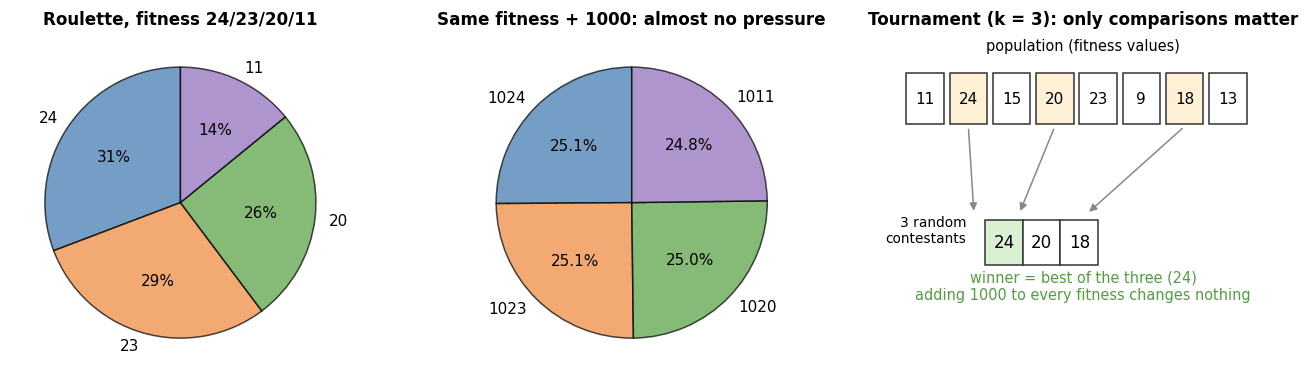

**Line by line.**
- `def binary_ga(fitness, n_bits, pop_size=30, n_gens=60, cx_rate=0.9, mut_rate=None, k=3, elite=1, rng=None, snapshot_gens=()):`
  - `mut_rate = mut_rate if mut_rate is not None else 1.0 / n_bits` — the default rate.
  - `pop = rng.integers(0, 2, size=(pop_size, n_bits))` — a random 0/1 population.
  - `fit = np.array([fitness(ind) for ind in pop], dtype=float)` — fitness of each individual.
  - `hist = {...}` — best and mean per generation, plus population snapshots for plotting; `if 0 in snapshot_gens` saves the initial one.
  - `for g in range(1, n_gens + 1):`
    1. `elites = pop[np.argsort(-fit)[:elite]]` — the top individual(s).
    2. Tournament selection, vectorised:
       - `n_children = pop_size - elite`.
       - `contestants = rng.integers(0, pop_size, size=(n_children, k))` — each row holds k random indices, one tournament per row.
       - `fit[contestants]` looks up their fitness (shape n_children × k); `np.argmax(..., axis=1)` gives the winner's *column* in each row; `contestants[np.arange(n_children), winner_col]` converts that to a population index; `pop[...]` gathers the winners.
    3. One-point crossover on pairs (0, 1), (2, 3), …:
       - `if rng.random() < cx_rate:` — crossover happens with probability 0.9; otherwise the pair passes through unchanged.
       - `cut = rng.integers(1, n_bits)`.
       - `children[i, cut:], children[i + 1, cut:] = parents[i + 1, cut:], parents[i, cut:]` — swap tails. Reading from `parents` and writing into `children` keeps the swap correct.
       - With an odd number of children (29 here), the last one has no partner and only gets mutated.
    4. `children ^= (rng.random(children.shape) < mut_rate)` — bit-flip mutation: XOR with a random mask.
    5. `pop = np.vstack([elites, children])` — the new population (elites on top); then re-evaluate, record history, and save a snapshot if requested.
  - `return pop[i], fit[i], hist` with `i = np.argmax(fit)`.
- `onemax = lambda bits: bits.sum()` — the fitness: the count of 1s.
- `snaps = (0, 5, 15, 40)` — generations to visualise.
- The run uses 40 bits, population 30, 40 generations, seed `SEED`.
- Plot: `gridspec_kw={"width_ratios": [1, 1, 1, 1, 1.6]}` makes the last panel wider. For each snapshot, `P[np.argsort(-P.sum(1))]` sorts individuals by number of ones (most first); `imshow(..., cmap="Greys")` shows 1 as black and 0 as white; `interpolation="nearest"` keeps the pixels sharp. The last panel plots best and mean fitness.

**Reading the output.** The best individual reaches 40/40 ones. In the images, generation 0 is random noise and the columns turn black over the generations. The mean stays slightly below 40 even after the best reaches 40, because mutation keeps flipping about one bit per child.

In the population images, black pixels are 1s. Generation 0 is random noise. Over the generations the columns turn black as good bits **spread through the population**, both by selection copying good individuals and by crossover combining good segments from different parents.

Notice that the *mean* stays slightly below 40 even after the *best* reaches 40. Mutation keeps flipping roughly one bit per child, so the population never becomes perfect clones. Elitism guarantees the best solution is never lost.

### 4.9 Checking the GA against a known optimum: 15-item knapsack
Knapsack adds a **constraint**: total weight ≤ capacity. GAs have no built-in notion of constraints, so a common approach is a **penalty**: infeasible solutions get a fitness worse than any feasible one, so selection removes them.

$$
\text{fitness}(\mathbf{b}) =
\begin{cases}
\text{value}(\mathbf{b}) & \text{if weight}(\mathbf{b}) \le C\\
-\big(\text{weight}(\mathbf{b}) - C\big) & \text{otherwise (more overweight = worse)}
\end{cases}
$$

The same `binary_ga` is reused; only the fitness function changes. Budget: 30 individuals × 30 generations ≈ 930 evaluations, under 3% of the 32,768 subsets brute force checked.

Optimum (brute force): 165
GA found the exact optimum in 9/20 runs; worst run = 163 (1.2% below optimal)


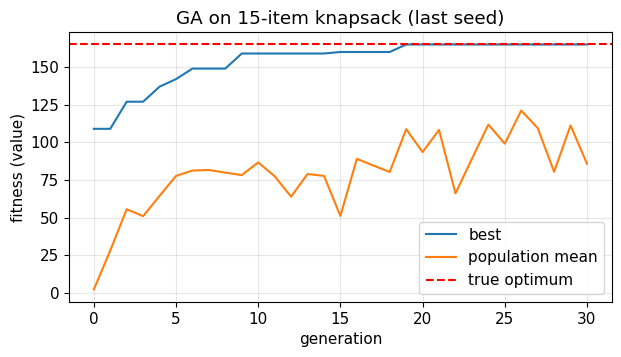

In [33]:
def knapsack_fitness(bits):
    w, v = bits @ KS_W, bits @ KS_V
    return v if w <= KS_CAP else -(w - KS_CAP)

RUNS = 20
results = []
for s in range(RUNS):
    b, fv, hk = binary_ga(knapsack_fitness, N_ITEMS, pop_size=30, n_gens=30, rng=np.random.default_rng(s))
    results.append(fv)
results = np.array(results)
print(f"Optimum (brute force): {KS_OPT_VAL}")
print(f"GA found the exact optimum in {np.sum(results == KS_OPT_VAL)}/{RUNS} runs; "
      f"worst run = {results.min():.0f} ({(1 - results.min() / KS_OPT_VAL) * 100:.1f}% below optimal)")

plt.figure(figsize=(7, 3.5))
plt.plot(hk["best"], label="best"); plt.plot(hk["mean"], label="population mean")
plt.axhline(KS_OPT_VAL, color="r", ls="--", label="true optimum")
plt.xlabel("generation"); plt.ylabel("fitness (value)"); plt.legend(); plt.title("GA on 15-item knapsack (last seed)")
plt.show()

#### 🔍 Explanation of the cell above — the GA on the 15-item knapsack (penalty for infeasibility)

**Concept.** GAs have no built-in notion of constraints, so infeasible (overweight) solutions must be handled somehow. Two classic approaches:
- **Repair**: modify an infeasible child until it is feasible (e.g. remove items until it fits).
- **Penalty**: give infeasible solutions a fitness worse than any feasible one, so selection removes them.

This cell uses a penalty: fitness = value if feasible, otherwise $-(\text{weight} - C)$. Every infeasible solution scores below 0 (worse than any feasible one), and *how far* it is overweight still matters, which guides the search back toward feasibility.

Because the optimum (165) was found by brute force in Section 1.5, the GA can be checked: 20 runs, each with about 930 evaluations (30 individuals × 31 generations), under 3% of brute force's 32,768.

**Diagram.** The penalty fitness, plotted for random subsets of the actual 15-item instance. Every overweight subset (red) scores below every feasible one (green), and the further over capacity it is, the lower it scores. That slope steers selection back toward feasibility. The optimum (gold star) sits just inside the capacity line.

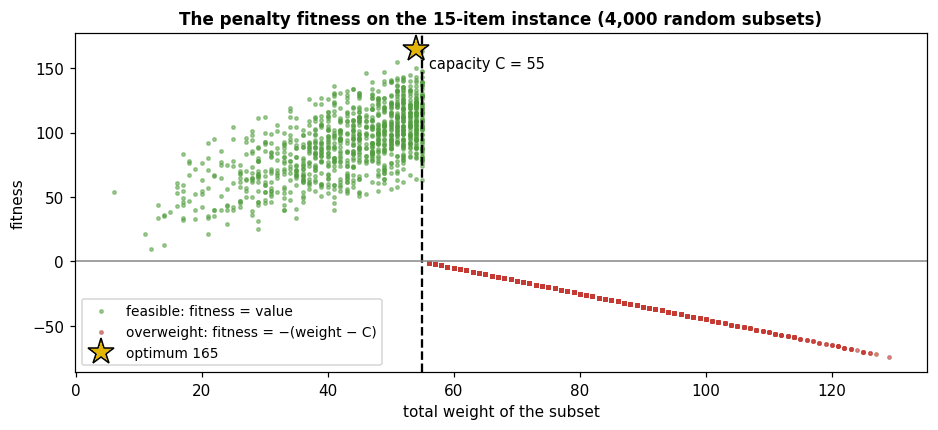

**Line by line.**
- `def knapsack_fitness(bits):` — `w, v = bits @ KS_W, bits @ KS_V` (dot products); `return v if w <= KS_CAP else -(w - KS_CAP)`.
- `RUNS = 20`; `results = []`.
- For each seed: `b, fv, hk = binary_ga(knapsack_fitness, N_ITEMS, pop_size=30, n_gens=30, rng=np.random.default_rng(s))` — the *same* GA as OneMax; only the fitness function changed.
- `np.sum(results == KS_OPT_VAL)` — the number of exact hits; the worst run's shortfall is `(1 − worst/optimum) × 100`.
- The plot shows the last seed's best and mean fitness against the true optimum.

**Reading the output.** The GA finds the exact optimum in 9 of 20 runs, and the worst run reaches 163 (1.2% below). The mean curve starts low, even negative, because many random subsets are overweight, then rises as selection removes them. More evaluations (larger population or more generations) buy reliability, but nothing is guaranteed. For a problem this small, brute force is the right tool in practice; the exercise is about *verifying* the GA.

The population mean starts low, often negative, because many random subsets are overweight and penalised. Within a few generations, selection removes the infeasible ones.

Read the success rate printed above carefully: the GA does **not** always find the exact optimum, but runs that miss it end up close. Try doubling `pop_size` or `n_gens` and watch how the success rate responds. This is the typical metaheuristic trade-off: more evaluations buy reliability, with no guarantee.

**Honest note:** for a 15-item problem, brute force takes milliseconds and is guaranteed to be optimal, so you would not use a GA here in practice. The value of this exercise is **verification**. For 100 items ($2^{100}$ subsets), brute force is impossible, but the same GA code still runs. Exact methods such as dynamic programming also exist for knapsack; GAs earn their place on problems without such structure.

Next we move from bit strings to **real-valued chromosomes**, which need different crossover and mutation operators.

In [37]:
def tournament_selection(pop, fit, n_select, k, rng):
    # Return n_select individuals; each is the best of k randomly drawn contestants.
    contestants = rng.integers(0, len(pop), size=(n_select, k))
    winners = contestants[np.arange(n_select), np.argmin(fit[contestants], axis=1)]
    return pop[winners].copy()

def blx_alpha_crossover(parents, rate, rng, alpha=0.5):
    # Pairs (0,1), (2,3), ... produce two children each; with probability 1-rate parents pass unchanged.
    children = parents.copy()
    m = len(parents) // 2
    p1, p2 = parents[0:2*m:2], parents[1:2*m:2]
    lo, hi = np.minimum(p1, p2), np.maximum(p1, p2)
    span = hi - lo
    c1 = rng.uniform(lo - alpha * span, hi + alpha * span)
    c2 = rng.uniform(lo - alpha * span, hi + alpha * span)
    do = rng.random(m) < rate
    children[0:2*m:2][do] = c1[do]
    children[1:2*m:2][do] = c2[do]
    return children

def gaussian_mutation(pop, rate, sigma, bounds, rng):
    mask = rng.random(pop.shape) < rate
    return np.clip(pop + mask * rng.normal(0, sigma, size=pop.shape), *bounds)

# --- tiny sanity demo of each operator ---
r = np.random.default_rng(0)
toy = np.array([[0.0, 0.0], [1.0, 1.0], [2.0, -2.0], [3.0, 3.0]])
toy_fit = rastrigin(toy)
print("toy fitness           :", np.round(toy_fit, 2))
print("tournament (k=2) picks:\n", tournament_selection(toy, toy_fit, 4, 2, r))
print("BLX-0.5 children of (0,0)&(1,1):\n", np.round(blx_alpha_crossover(toy[:2], 1.0, r), 3))

toy fitness           : [ 0.  2.  8. 18.]
tournament (k=2) picks:
 [[ 2. -2.]
 [ 1.  1.]
 [ 0.  0.]
 [ 0.  0.]]
BLX-0.5 children of (0,0)&(1,1):
 [[1.127 1.326]
 [0.713 0.959]]


#### 🔍 Explanation of the cell above — operators for real-valued chromosomes

**Concept.** When genes are real numbers (coordinates), bit-string operators no longer fit, and three replacements are used:
- **Tournament selection** (here written for **minimisation**: the *lowest* f wins).
- **BLX-α crossover** (Eshelman and Schaffer, 1993): for each gene, with parent values $p_1, p_2$ and $d = |p_1 - p_2|$, draw the child uniformly from $[\min - \alpha d,\ \max + \alpha d]$. With $\alpha = 0.5$ the interval extends half the parents' distance beyond each parent, so children can lie *outside* the parents' range. This keeps the population from shrinking too fast. As parents become similar, $d$ shrinks and so do the children's variations: crossover adapts its step size automatically.
- **Gaussian mutation**: each gene, independently with probability $p_m$, gets $\mathcal{N}(0, \sigma^2)$ noise; the result is clipped to the bounds.

**Diagram.** BLX-α crossover. For each gene the child is drawn uniformly from the parents' interval, extended by $\alpha d$ on both sides. In 2-D this gives a box around the parents (grey dots are possible children). Because the box is built gene by gene, it is aligned with the coordinate axes, which matters on the rotated benchmark in Part 5.

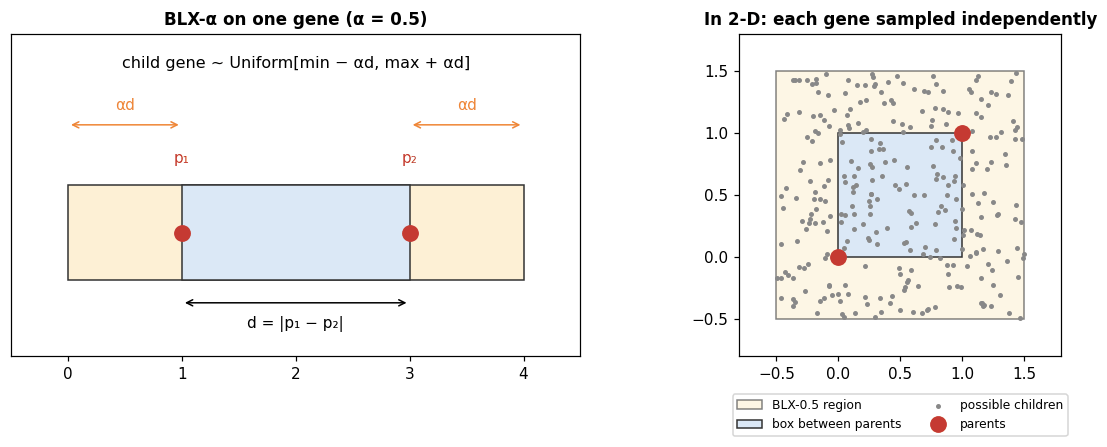

**Line by line.**
- `def tournament_selection(pop, fit, n_select, k, rng):`
  - `contestants = rng.integers(0, len(pop), size=(n_select, k))` — k random indices per tournament.
  - `winners = contestants[np.arange(n_select), np.argmin(fit[contestants], axis=1)]` — the lowest-f contestant in each row.
  - `return pop[winners].copy()`.
- `def blx_alpha_crossover(parents, rate, rng, alpha=0.5):`
  - `children = parents.copy()`; `m = len(parents) // 2` — number of pairs.
  - `p1, p2 = parents[0:2*m:2], parents[1:2*m:2]` — even-indexed and odd-indexed parents (slices with step 2), so pairs are (0, 1), (2, 3), ….
  - `lo, hi = np.minimum(p1, p2), np.maximum(p1, p2)`; `span = hi - lo` — per gene, per pair.
  - `c1 = rng.uniform(lo - alpha * span, hi + alpha * span)` and `c2` likewise — two independent children per pair, every gene sampled from its own interval (vectorised).
  - `do = rng.random(m) < rate` — which pairs actually cross over.
  - `children[0:2*m:2][do] = c1[do]` — `children[0:2*m:2]` is a *view* into `children` (slicing does not copy), so assigning through the boolean mask writes directly into `children`. The same is done for the odd positions.
- `def gaussian_mutation(pop, rate, sigma, bounds, rng):` — `mask = rng.random(pop.shape) < rate` chooses genes; `pop + mask * rng.normal(...)` adds noise only where the mask is True (multiplying by False gives 0); `np.clip` keeps genes in bounds.
- Demo: four toy points with fitness 0, 2, 8, 18; a k = 2 tournament (low-f points should be picked more often); BLX children of (0, 0) and (1, 1).

**Reading the output.** The tournament picks favour (0, 0) and (1, 1), the low-f points. The BLX children are (1.127, 1.326) and (0.713, 0.959); the first lies *outside* the parents' box [0, 1]², as $\alpha > 0$ allows.

In [38]:
def genetic_algorithm(f, dim, bounds=BOUNDS, pop_size=60, n_gens=200,
                      crossover_rate=0.9, mutation_rate=0.1, mutation_sigma=0.3,
                      tournament_k=3, elite=2, rng=None, snapshot_gens=()):
    rng = rng or np.random.default_rng()
    pop = rng.uniform(*bounds, size=(pop_size, dim))
    fit = f(pop)
    log = {"best": [], "mean": [], "diversity": [], "snapshots": {}}

    def record(g):
        log["best"].append(fit.min()); log["mean"].append(fit.mean())
        log["diversity"].append(pop.std(axis=0).mean())
        if g in snapshot_gens:
            log["snapshots"][g] = pop.copy()

    record(0)
    for g in range(1, n_gens + 1):
        elites = pop[np.argsort(fit)[:elite]]                                      # 1. elitism
        parents = tournament_selection(pop, fit, pop_size - elite, tournament_k, rng)  # 2. selection
        rng.shuffle(parents)                                                       #    random mating
        children = blx_alpha_crossover(parents, crossover_rate, rng)              # 3. crossover
        children = gaussian_mutation(children, mutation_rate, mutation_sigma, bounds, rng)  # 4. mutation
        pop = np.vstack([elites, children])                                        # 5. replacement
        fit = f(pop)
        record(g)

    i = np.argmin(fit)
    log = {k: (np.array(v) if k != "snapshots" else v) for k, v in log.items()}
    return pop[i], fit[i], log

#### 🔍 Explanation of the cell above — the real-valued GA engine

**Concept.** A complete generational GA for continuous minimisation. Each generation:
1. **Elitism** — keep the `elite` best individuals.
2. **Selection** — fill the remaining slots by tournament.
3. **Random mating** — shuffle the selected parents so that pairs (0, 1), (2, 3), … are random.
4. **Crossover** — BLX-α on each pair with probability `crossover_rate`.
5. **Mutation** — Gaussian, per gene, with probability `mutation_rate`.
6. **Replacement** — elites plus children form the new population.

It also logs **diversity**, measured as the standard deviation of each gene across the population, averaged over genes. Diversity is the GA's counterpart of SA's temperature: high means exploring, low means converged.

**Diagram.** The six steps inside one generation of `genetic_algorithm`. Elites bypass selection, crossover and mutation; everyone else goes through all of them. Each generation costs `pop_size` evaluations.

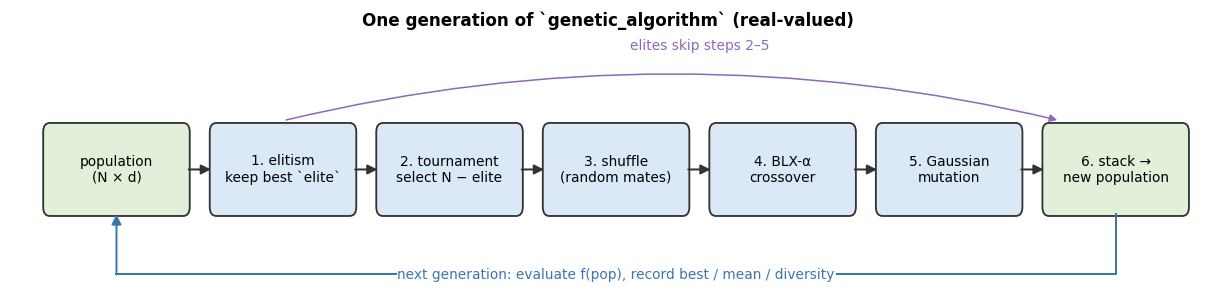

**Line by line.**
- Signature: objective `f`, dimension `dim`, `bounds`, population size, number of generations, the three operator rates/sizes, tournament size, elite count, rng, and which generations to snapshot.
- `pop = rng.uniform(*bounds, size=(pop_size, dim))` — a uniformly random initial population.
- `fit = f(pop)` — vectorised evaluation of all individuals (this is why `rastrigin` was written to accept a population).
- `log = {"best": [], "mean": [], "diversity": [], "snapshots": {}}`.
- `def record(g):` — a nested function that appends `fit.min()`, `fit.mean()` and `pop.std(axis=0).mean()`, and saves a copy of the population if `g` is a snapshot generation. It reads `pop` and `fit` from the enclosing function. Python closures look up these names *when called*, so `record` always sees the current population even after `pop` has been reassigned.
- `record(0)` — log the initial population.
- `for g in range(1, n_gens + 1):`
  - `elites = pop[np.argsort(fit)[:elite]]` — ascending sort, since lower f is better.
  - `parents = tournament_selection(pop, fit, pop_size - elite, tournament_k, rng)`.
  - `rng.shuffle(parents)` — shuffles the rows in place, so mating partners are random.
  - `children = blx_alpha_crossover(parents, crossover_rate, rng)`.
  - `children = gaussian_mutation(children, mutation_rate, mutation_sigma, bounds, rng)`.
  - `pop = np.vstack([elites, children])`; `fit = f(pop)`; `record(g)`.
- `i = np.argmin(fit)` — the best of the final population.
- `log = {k: (np.array(v) if k != "snapshots" else v) for k, v in log.items()}` — convert the lists to arrays for plotting, leaving the snapshots dictionary as is.
- `return pop[i], fit[i], log`.

**Evaluation cost.** Each generation evaluates `pop_size` individuals (elites included), so a run costs `pop_size × (n_gens + 1)` evaluations. This is the unit used for the fair comparison in Part 5.

There is no output; the cell only defines the function.

### 4.11 Watching a population evolve (2-D Rastrigin)

GA best: x = [-0. -0.], f = 0.00000


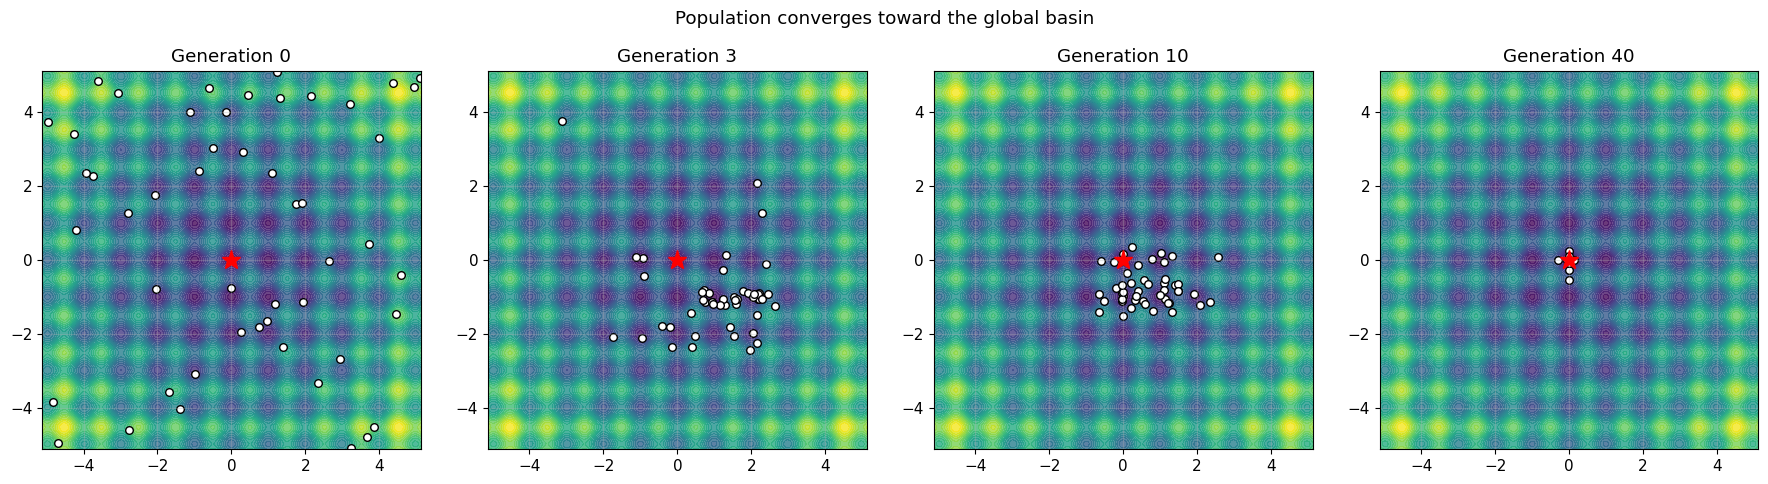

In [39]:
snaps = (0, 3, 10, 40)
ga_x, ga_f, ga_log = genetic_algorithm(rastrigin, dim=2, pop_size=50, n_gens=40,
                                       rng=np.random.default_rng(0), snapshot_gens=snaps)
print(f"GA best: x = {np.round(ga_x, 4)}, f = {ga_f:.5f}")

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, gen in zip(axes, snaps):
    P = ga_log["snapshots"][gen]
    ax.contourf(X, Y, Z, levels=30, cmap="viridis", alpha=0.8)
    ax.scatter(P[:, 0], P[:, 1], c="white", edgecolors="k", s=30)
    ax.plot(0, 0, "r*", ms=14); ax.set_title(f"Generation {gen}"); ax.set_aspect("equal")
plt.suptitle("Population converges toward the global basin", y=1.02); plt.tight_layout(); plt.show()

#### 🔍 Explanation of the cell above — watching a population evolve on 2-D Rastrigin

**Concept.** A GA's search is easiest to understand by watching the population. Generation 0 is spread uniformly over the domain. Selection removes points in high basins, crossover produces points *between and around* good parents, and the cloud contracts toward the best region it has found. Unlike SA's single moving point, a population samples many basins at once.

**Line by line.**
- `snaps = (0, 3, 10, 40)` — generations to show.
- `ga_x, ga_f, ga_log = genetic_algorithm(rastrigin, dim=2, pop_size=50, n_gens=40, rng=np.random.default_rng(0), snapshot_gens=snaps)`.
- Print the best point and value.
- `fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))` — one panel per snapshot.
- For each panel: `P = ga_log["snapshots"][gen]` (a 50 × 2 array); contour background; `ax.scatter(P[:, 0], P[:, 1], c="white", edgecolors="k", s=30)` draws individuals as white dots with black outlines; the global minimum is starred; `set_aspect("equal")`.
- `plt.suptitle(..., y=1.02)` — an overall title above the panels.

**Reading the output.** The best found is (−0, −0) with $f = 0.00000$, the exact global minimum. ("−0" is a negative number that rounds to zero.) The panels show the scattered population collapsing onto the centre by generation 40.

That run succeeded, but **a GA is also stochastic and can converge prematurely**. Let's check the success rate over 20 seeds instead of trusting a single run.

In [ ]:
finals = np.array([genetic_algorithm(rastrigin, dim=2, pop_size=50, n_gens=60,
                                     rng=np.random.default_rng(s))[1] for s in range(20)])
print("final f per seed:", np.round(finals, 3))
print(f"reached global min (f < 0.01): {np.mean(finals < 0.01):.0%} of runs")
print("other runs stopped at f ≈ 0.995, the local minima at distance 1 from the origin, e.g. (±1, 0).")

final f per seed: [0.    0.    0.995 0.995 0.    0.    0.    0.    0.    0.995 0.    0.
 0.995 0.995 0.    0.    0.995 0.    0.    0.   ]
reached global min (f < 0.01): 70% of runs
other runs stopped at f ≈ 0.995, the local minima at distance 1 from the origin, e.g. (±1, 0).


#### 🔍 Explanation of the cell above — success rate of the GA over 20 seeds

**Concept.** One successful run can be luck. GAs can **converge prematurely**: if the population collapses into a good-but-not-best basin early, crossover can only produce points near that basin, and small mutations rarely jump far enough to escape. The honest measure is a **success rate over many seeds**.

The value 0.995 is not arbitrary. Rastrigin's local minima nearest the origin are at a distance of about 1, e.g. near (1, 0). Exactly at (1, 0), $f = 1$; the true local minimum sits slightly inward, at about (0.995, 0), with $f \approx 0.995$, because the $x^2$ term pulls toward the origin.

**Diagram.** Premature convergence, sketched along one axis. Once the whole population sits in one basin (right), crossover between near-identical parents can only produce points in the same basin, and small mutations rarely jump over the ridge. That is the fate of the 30% of runs that end at 0.995.

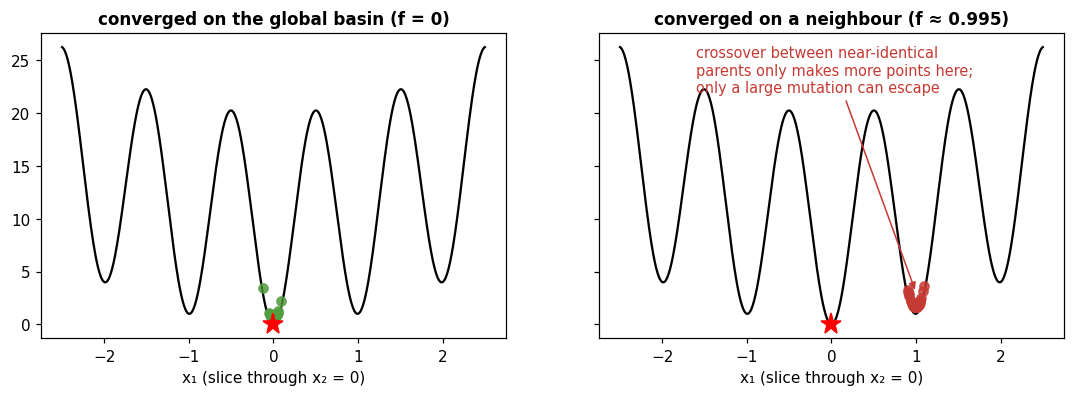

**Line by line.**
- `finals = np.array([genetic_algorithm(...)[1] for s in range(20)])` — 20 runs with seeds 0–19 (60 generations, population 50); `[1]` keeps only the best f from the returned tuple.
- `np.round(finals, 3)` — print the results.
- `np.mean(finals < 0.01)` — the fraction of runs that reached the global minimum.

**Reading the output.** 14 of 20 runs (70%) reach $f = 0$; the other 6 stop at 0.995, a neighbouring basin. A GA greatly improves on hill climbing but, like SA, offers no guarantee for any single run.

### 4.12 A harder case: 10-D Rastrigin — fitness and diversity over time

**What to point out:**
- The *mean* curve trails the *best* curve. When they meet, the population has converged.
- Diversity collapses over time. Once it reaches roughly the mutation scale, crossover can no longer generate anything new, and progress depends on mutation alone. This is the GA analogue of SA "freezing".

**Interpretation:** with $p_m = 0$, diversity collapses and the population stalls (premature convergence). If $p_m$ is too high, offspring are mostly random noise and good building blocks are destroyed. The best setting sits in between. Mutation and selection play the same role as temperature in SA: they set the exploration–exploitation balance.

#### 🔍 Explanation of the cell above — plotting the head-to-head results

**Concept.** Show the mean result per method with **error bars** (± one standard deviation across seeds), one panel per problem. When the bars of two methods overlap a lot, the difference between them is not convincing with only 5 seeds.

**Diagram.** A schematic of the two search styles. SA (left, a short illustrative run) moves a single point; its path wanders while hot and tightens as it cools. A GA (right, illustrative clouds) moves a whole population that contracts around good regions. The population costs more per step but samples many basins at once and can be evaluated in parallel.

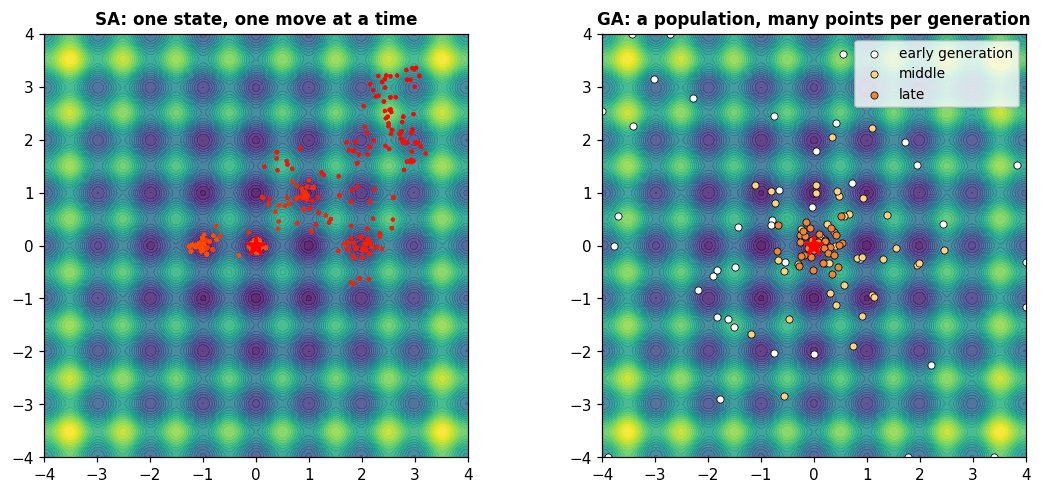

**Reading the output.** The three panels show the same conclusions as the table: the coordinate SA dominates only on the separable problem, the GA is the most robust under rotation, and SA and GA overlap on TSP-30.

> ⚠️ *Note:* `a.containers[1]` relies on Matplotlib storing the error-bar container *before* the bar container when `yerr` is given. If someone removes the error bars, index 1 no longer exists and the call fails. A more robust pattern is `bars = a.bar(...)` followed by `a.bar_label(bars, ...)`.

### How to read the results honestly
- **The neighbourhood mattered more than the algorithm.** On separable Rastrigin, SA with single-coordinate moves beats the GA by orders of magnitude, while SA with full-vector moves is the worst of the three. Both runs use the same SA engine; only the move operator differs.
- **That win depends on structure, not on SA itself.** Single-coordinate moves effectively solve 10 independent 1-D problems, which works only because the function is separable. After rotation, the same configuration becomes one of the worst. The GA degrades much less here, although BLX is also axis-aligned and does lose some quality.
- **On TSP**, SA with 2-opt and the GA end up close, with overlapping spread. The GA uses the same 2-opt move only as a mutation and spends its budget across a population, which is why GAs for TSP are usually hybridised with local search (*memetic algorithms*).
- **No Free Lunch** (Wolpert & Macready, 1997): averaged over all problems, all optimizers perform equally. Practical performance comes from how well the operators match the problem's structure.
- With 5 seeds the confidence intervals are wide. For a paper, use 30+ runs and a non-parametric test such as Wilcoxon rank-sum, and test on rotated or shifted variants of benchmarks so that you do not reward axis-aligned operators by accident.

### SA vs. GA at a glance

| Aspect | Simulated Annealing | Genetic Algorithm |
|---|---|---|
| Search state | One solution | Population of solutions |
| Escape mechanism | Probabilistic uphill moves ($T$) | Recombination + mutation + diversity |
| Key hyperparameters | $T_0$, cooling schedule, neighbourhood | pop size, $p_c$, $p_m$, selection pressure, elitism |
| Problem-specific design | Neighbourhood move | Encoding + crossover + mutation |
| Memory / cost per step | Very low, one evaluation | `pop_size` evaluations per generation |
| Parallelism | Limited (parallel chains / restarts) | Natural: evaluate population in parallel |
| Theory | Asymptotic convergence with log cooling | Schema theorem (heuristic), Markov-chain analyses |
| Shines when | A good local move exists that matches the problem's structure | Solutions combine meaningfully; parallel evaluation available; multi-objective (e.g. NSGA-II) |

---
## Wrap-up & exercises

**Key takeaways**
1. Greedy search is fast but myopic: hill climbing solved only a minority of 8-queens boards. Both SA and GA trade some short-term greed for global exploration.
2. In SA, **temperature** controls exploration. Calibrate $T_0$, then cool geometrically in practice.
3. In a GA, **selection pressure vs. diversity** controls exploration. Mutation prevents premature convergence.
4. **Representation matters:** permutations need permutation-preserving operators.
5. Compare optimizers at **equal evaluation budgets, across many seeds**, and on rotated or shifted benchmarks. Part 5 showed how an operator matched to a structural quirk can flip the ranking.

**Glossary**

| Term | One-line meaning |
|---|---|
| Objective / fitness | The number we minimize (objective) or maximize (fitness) |
| Search space | All candidate solutions |
| Neighbourhood | Solutions reachable by one small change |
| Local / global optimum | Best among neighbours / best overall |
| Temperature (SA) | Tolerance for accepting worse moves; decreases over time |
| Cooling schedule (SA) | Rule for lowering the temperature |
| Chromosome / encoding (GA) | How a solution is written as genes (bits, reals, permutation) |
| Selection (GA) | Choosing parents, biased toward fitter individuals |
| Crossover (GA) | Combining two parents into children |
| Mutation (GA) | Small random change to a child |
| Elitism (GA) | Copying the best individuals unchanged into the next generation |
| Culling (GA) | Discarding individuals below a fitness threshold before selection |
| Reproduction (Goldberg) vs. `REPRODUCE` (pseudocode) | Fitness-based copying (selection) vs. the crossover function; same word, different operator |
| Schedule (SA) | Function mapping time $t$ to temperature $T$; SA stops when it returns 0 |
| Premature convergence | Population collapses into one region too early |
| Evaluation budget | Number of objective evaluations allowed; the fair unit for comparisons |

**Exercises (in increasing difficulty)**

*Slide-based exercises*
- **S1.** Do one GA generation on 8-queens *by hand* starting from the slide's population, but with crossing sites k = 2 and k = 6. Check your fitness values with `non_attacking_pairs`.
- **S2.** In `simulated_annealing_slides`, add best-so-far tracking and an early stop when $h = 0$. Does the 8-queens success rate change for the hot schedule?
- **S3.** Scale to **N-queens** with N = 16 and N = 32 (generalise `attacking_pairs`). Which degrades faster, SA or the slide GA?
- **S4.** Implement culling with a **fixed threshold** (for example, fitness < 20) instead of discarding the bottom half. How sensitive is the GA to the threshold?

*General exercises*
0. *Warm-up:* Re-run Section 4.3 (the slides' 8-queens generation) and Section 4.7 with different seeds. How often does the maximum fitness improve after one generation? Then change `sa_1d` in Section 3.5 to use linear cooling.
1. *SA:* Replace the fixed σ in `gaussian_neighbour` with a temperature-scaled step $\sigma_k \propto \sqrt{T_k}$. Does 10-D Rastrigin improve?
2. *SA:* Implement $O(1)$ delta evaluation for the 2-opt move. Measure the speed-up on 200 cities.
3. *GA:* Add **roulette-wheel** selection and compare its diversity curve with tournament selection for $k = 2, 3, 7$.
4. *GA:* Solve the **0/1 knapsack** problem with a binary encoding, one-point crossover, and bit-flip mutation. How do you handle infeasible (overweight) solutions: repair or penalty?
5. *Rotation invariance:* Design a GA crossover that does not depend on the coordinate axes (hint: sample children along the line between parents, or read about CMA-ES). Does it close the gap on rotated Rastrigin?
6. *Hybrid:* Build a **memetic GA** for the TSP by applying a few 2-opt improvements to each child. Compare it to pure SA at equal budget.

**References**
- Kirkpatrick, Gelatt & Vecchi (1983). *Optimization by Simulated Annealing.* Science 220(4598).
- Metropolis et al. (1953). *Equation of State Calculations by Fast Computing Machines.* J. Chem. Phys. 21.
- Hajek (1988). *Cooling Schedules for Optimal Annealing.* Math. of Operations Research 13(2).
- Holland (1975). *Adaptation in Natural and Artificial Systems.* Univ. of Michigan Press.
- Goldberg (1989). *Genetic Algorithms in Search, Optimization, and Machine Learning.* Addison-Wesley.
- Eshelman & Schaffer (1993). *Real-Coded Genetic Algorithms and Interval-Schemata* (BLX-α). FOGA 2.
- Wolpert & Macready (1997). *No Free Lunch Theorems for Optimization.* IEEE TEC 1(1).